In [ ]:
import networkx as nx
import random

def barabasi_albert_graph(n, m, seed=None):
    """
    Manually builds a Barabási–Albert (BA) graph using preferential attachment.

    Parameters:
        n (int): Total number of nodes in the final graph.
        m (int): Number of edges each new node attaches to when added.
        seed (int, optional): Random seed for reproducibility.

    Returns:
        G (nx.Graph): The generated BA graph.
    """
    if seed is not None:
        random.seed(seed)

    if m < 1 or m >= n:
        raise ValueError("m must satisfy 1 <= m < n")

    # Initialize with a small fully connected (complete) graph of m nodes
    G = nx.Graph()
    G.add_nodes_from(range(m))
    for i in range(m):
        for j in range(i + 1, m):
            G.add_edge(i, j)

    # A list of nodes where each node appears as many times as its degree.
    # This is used for preferential attachment sampling.
    node_list = list(G.nodes()) * (m - 1)
    for new_node in range(m, n):
        # Select m distinct existing nodes with probability proportional to degree
        targets = set()
        while len(targets) < m:
            chosen = random.choice(node_list)
            targets.add(chosen)

        # Add the new node and edges to selected targets
        G.add_node(new_node)
        for t in targets:
            G.add_edge(new_node, t)

        # Update node_list for degree weighting
        node_list.extend(targets)
        node_list.extend([new_node] * m)

    return G

In [ ]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def dfs_spanning_tree(G, root=0):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend, weighted=False):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    # G.add_nodes_from(list(range(backend.num_qubits)))
    if weighted:
        # props = backend.properties()
        # # Extract two-qubit gate errors
        # for gate in props.gates:
        #     if gate.gate in ['cz', 'cx', 'ecr']:
        #         q1, q2 = gate.qubits
        #         err = next(param.value for param in gate.parameters if param.name == "gate_error")
        #         if err<1.0:
        #             G.add_edge(q1, q2, weight=1-err)

        props = backend.properties()
        conf = backend.configuration()
        coupling = conf.coupling_map

        alpha=0.9
        beta_readout=0.75
        beta_t12=0.2
        beta_gate=0.1

        G = nx.Graph()
        # G.add_nodes_from(range(conf.num_qubits))

        # ---- Node (1Q) noise ----
        node_noise = {}
        for q in range(conf.num_qubits):
            qb = props.qubits[q]
            readout_err = qb[2].value
            t1, t2 = qb[0].value, qb[1].value
            decoh = (1e-4 / t1 + 1e-4 / t2) if t1 > 0 and t2 > 0 else 0
            gate_errs = [
                param.value
                for g in props.gates
                if len(g.qubits) == 1 and g.qubits[0] == q
                for param in g.parameters
                if param.name == "gate_error"
            ]
            avg_gate_err = np.mean(gate_errs) if gate_errs else 0
            node_noise[q] = (
                beta_readout * readout_err
                + beta_t12 * decoh
                + beta_gate * avg_gate_err
            )

        # ---- Edge (2Q) noise ----
        for g in props.gates:
            if len(g.qubits) == 2:
                q1, q2 = g.qubits
                err = next(param.value for param in g.parameters if param.name == "gate_error")
                node_term = (node_noise[q1] + node_noise[q2]) / 2
                # print(node_term)
                combined_noise = alpha * err + (1 - alpha) * node_term
                reliability = 1 - combined_noise
                # if reliability>0.9:
                G.add_edge(q1, q2, weight=max(reliability, 0))
    else:
        G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

def graph_fiedler_sort(graph):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def graph_laplacian_embedding(G, k=2, alpha=0.95, normalized=False):
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        if normalized:
            A = adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            degrees = np.sum(A, axis=1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degrees, 1e-12)))

            # --- Normalized Laplacian ---
            L_sym = np.eye(G.number_of_nodes()) - D_inv_sqrt @ A @ D_inv_sqrt

            # --- Compute eigenvalues and eigenvectors ---
            vals, vecs = eigh(L_sym)
            # Sort eigenpairs
            idx = np.argsort(vals)
            vals, vecs = vals[idx], vecs[:, idx]

            # Skip the first eigenvector (constant)
            X = vecs[:, 1:k+1]
        else:
            adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            L = laplacian(adj_matrix)
            vals, vecs = eigh(L)
            X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None
    
import matplotlib.pyplot as plt
def gradient_graph(graph : nx.Graph, normalized=False, tree=None, title=None, flip_sign=False):
    if not tree:
        tree = graph
    G = nx.Graph()
    G.add_nodes_from(sorted(graph.nodes()))
    G.add_edges_from(graph.edges())
    graph=G
    fiedler = graph_laplacian_embedding(tree, k=1, normalized=normalized).flatten()
    # sorted_nodes = np.argsort(fiedler)

    fiedler_dict = {}
    fiedler_dict = {list(graph.nodes)[i] : (1+2*flip_sign*(-1))*fiedler[i] for i in range(graph.number_of_nodes())}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()


def selective_bfs(G, source, n, weight='weight', threshold=0.9, relax_factor=0.5, min_threshold=0.0):
    if source not in G:
        raise ValueError(f"Source node {source} not in graph")

    visited = set([source])
    q = deque([source])
    sub_nodes = [source]
    current_threshold = threshold

    while len(sub_nodes) < n:
        progress = False
        temp_q = deque(q)

        while temp_q and len(sub_nodes) < n:
            u = temp_q.popleft()
            for v in G.neighbors(u):
                if v not in visited:
                    w = G[u][v].get(weight, 1.0)
                    if w >= current_threshold:
                        visited.add(v)
                        q.append(v)
                        sub_nodes.append(v)
                        progress = True
                        if len(sub_nodes) >= n:
                            break

        # If no new nodes were added, relax the threshold
        if not progress:
            current_threshold *= relax_factor
            if current_threshold < min_threshold:
                # As a last resort, include any remaining nodes
                remaining = [v for v in G.nodes if v not in visited]
                sub_nodes.extend(remaining[: n - len(sub_nodes)])
                break

    return G.subgraph(sub_nodes).copy()

def initial_layout(graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None, noise_aware=False):
    num_nodes = graph.number_of_nodes()
    n = int(np.sqrt(num_nodes))
    if how=='fiedler':
        sorted_nodes = graph_fiedler_sort(graph)

        if topology=='chain':
            chain = find_linear_chain(backend, num_nodes)
        else:
            if noise_aware:
                G = get_coupling_graph(backend, weighted=True)
            else:
                G = get_coupling_graph(backend)
            if not root_on_backend:
                root_on_backend = backend.num_qubits//2
            
            if noise_aware:
                tree_layout = selective_bfs(G, source=root_on_backend, n=num_nodes)
            else:
                tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)

            order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))

    if how not in ['trivial', 'random']:
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit

In [ ]:
def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai',
                      node_size=100, font_size=6, highlight_nodes=None, title=None):
    import math

    graph = nx.Graph()
    graph.add_nodes_from(G.nodes())
    graph.add_edges_from(G.edges())
    G=graph

    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout with bottom-to-top rows
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        rows = math.ceil(n / side)
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    # Node colors
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size,
            font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

In [ ]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import numpy as np

def optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=None):
    """
    Find optimal mapping between logical and physical qubits
    using Hungarian algorithm on Euclidean distances.

    Args:
        logical_embedding: np.ndarray, shape (n, k)
        physical_embedding: np.ndarray, shape (n, k)

    Returns:
        mapping: dict {logical_index: physical_index}
    """
    if not nodes:
        nodes = list(range(physical_embedding.shape[0]))
    # cost matrix: pairwise distances between embeddings
    cost_matrix = cdist(logical_embedding, physical_embedding, metric='sqeuclidean')

    # Hungarian (linear sum assignment)
    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    # Construct mapping
    mapping = {int(r): int(nodes[c]) for r, c in zip(row_ind, col_ind)}
    return mapping


In [ ]:
def normalized_graph(graph:nx.Graph):
    for u,v in list(graph.edges):
        graph[u][v]['weight'] = 1.0/np.sqrt(graph.degree(u)*graph.degree(v))
    return graph

In [ ]:
def return_ops(backend, graph_type='reg', param=4, average_over=5, node_list=list(range(10,101,2)), reps=2, tech='1D', k=2, topology='tree_dfs', opt_level=3, op_name='ecr', use_custom=True, stop_after_routing=False, normalize_laplacian=False, noise_aware=False):
    swaps = {'means': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]},
             'stddevs': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':[], 'fied':[], 'triv':[], 'rand':[]}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = barabasi_albert_graph(n=n, m=param, seed=0)
        gen = gen_QAOA_circuit(graph, reps=reps)
        spec_graph=graph
        if tech=='1D':
            tree = dfs_spanning_tree(graph, root=0)
            
            proposed_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology, noise_aware=noise_aware)
        elif tech=='2D':
            logical_embedding = graph_laplacian_embedding(spec_graph, k=k, normalized=normalize_laplacian)
            logical_embedding = logical_embedding[:, :k]

            H = get_coupling_graph(backend, weighted=noise_aware)
            if noise_aware:
                S = selective_bfs(H, source=H.number_of_nodes()//2, n=n)
            else:
                S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n)
            physical_embedding = graph_laplacian_embedding(S, k=k)

            # if k>2:
            #     num_extra_cols = k - 2
            #     physical_embedding = np.hstack([physical_embedding, np.zeros((physical_embedding.shape[0], num_extra_cols))])

            proposed_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, proposed_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        # swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial')
        # swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(graph, backend=backend, how='random')
        # swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            swap_avg['fied'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=proposed_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['triv'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['sabre'].append(func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0))
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['means']['SABRE'].append(np.mean(swap_avg['sabre']))
        swaps['stddevs']['SABRE'].append(np.std(swap_avg['sabre']))

        swaps['means']['Proposed'].append(np.mean(swap_avg['fied']))
        swaps['stddevs']['Proposed'].append(np.std(swap_avg['fied']))

        swaps['means']['Trivial'].append(np.mean(swap_avg['triv']))
        swaps['stddevs']['Trivial'].append(np.std(swap_avg['triv']))

    return swaps

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
backend = FakeBrisbane()
# backend = FakeTorino()

In [ ]:
import warnings
warnings.filterwarnings("ignore")

## SWAP Counts

Fiedler Mapped

In [22]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=100, node_list=nodes_reg, tech='1D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

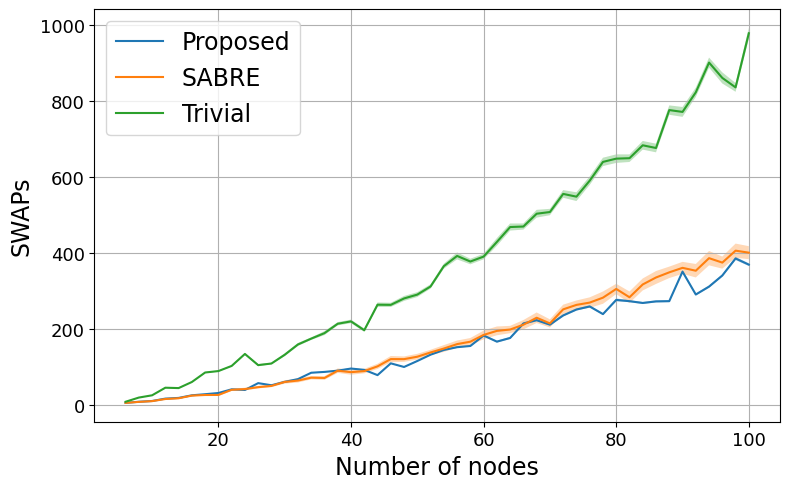

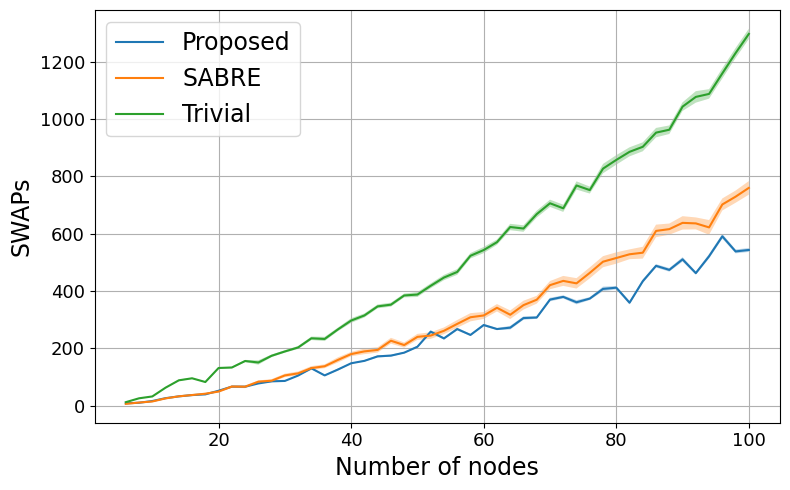

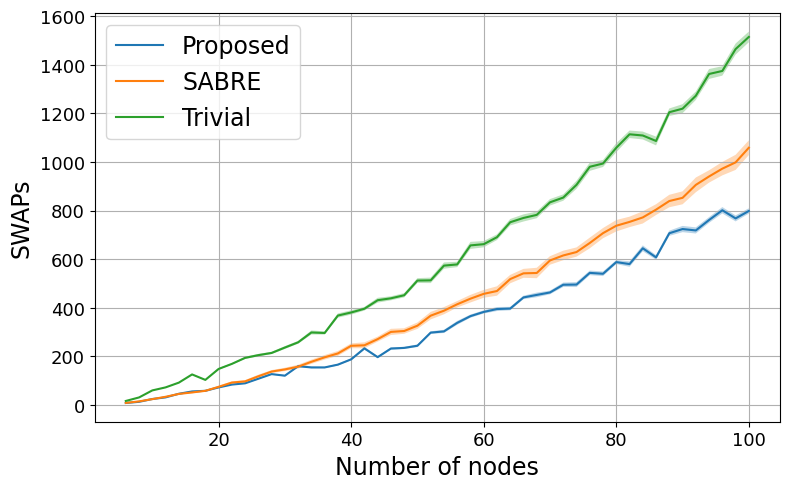

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [24]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

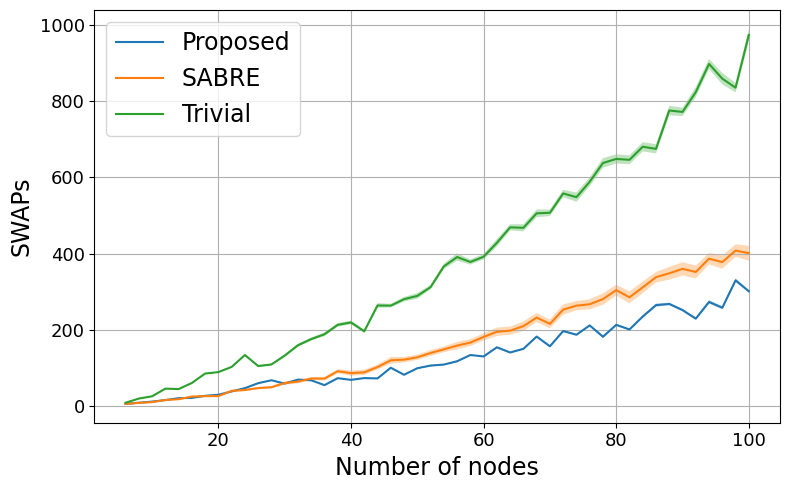

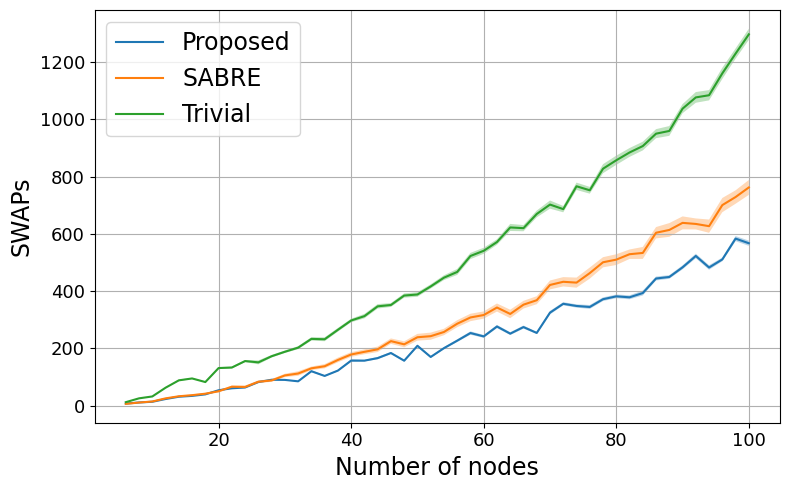

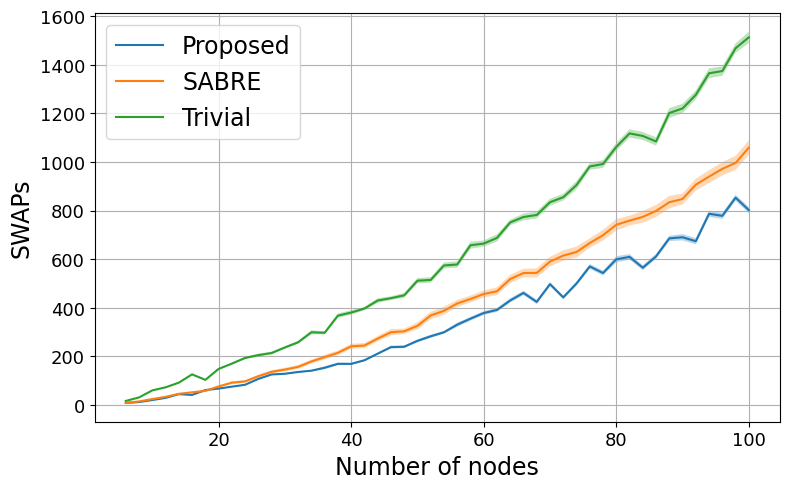

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [26]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

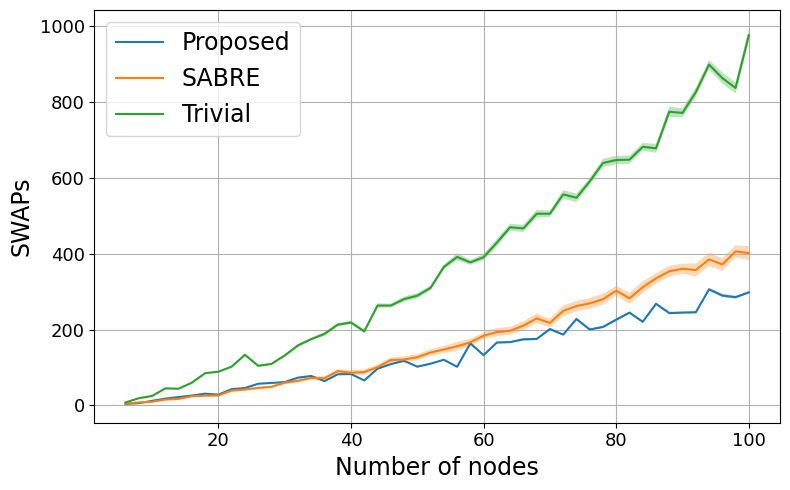

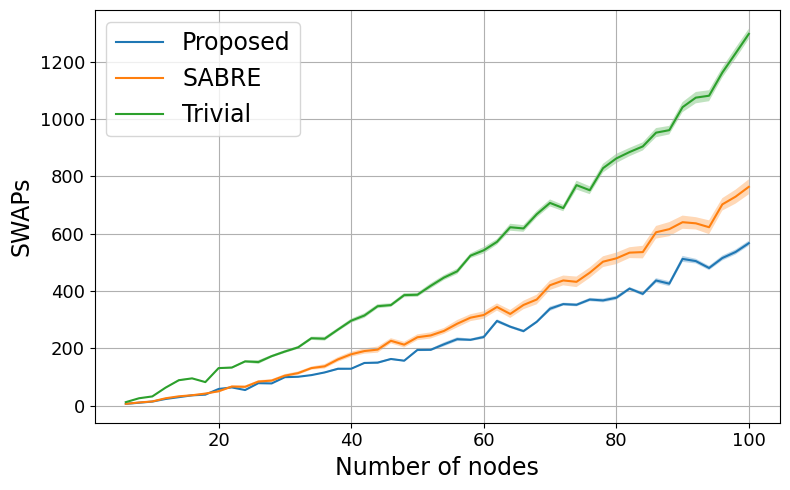

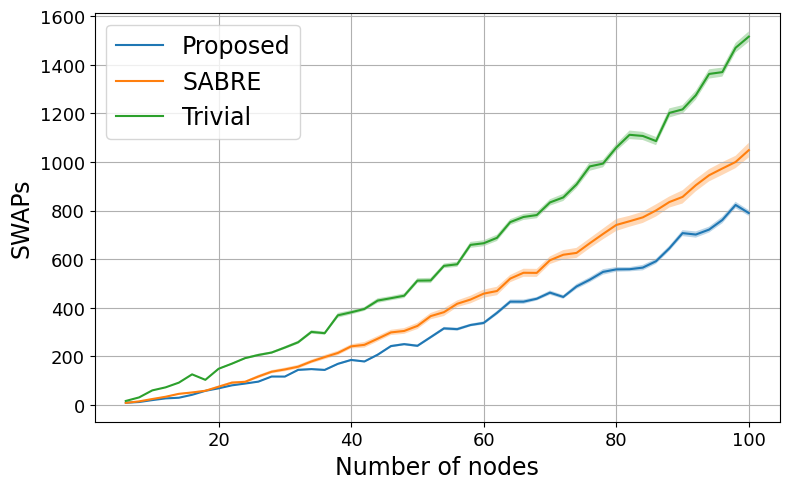

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [28]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

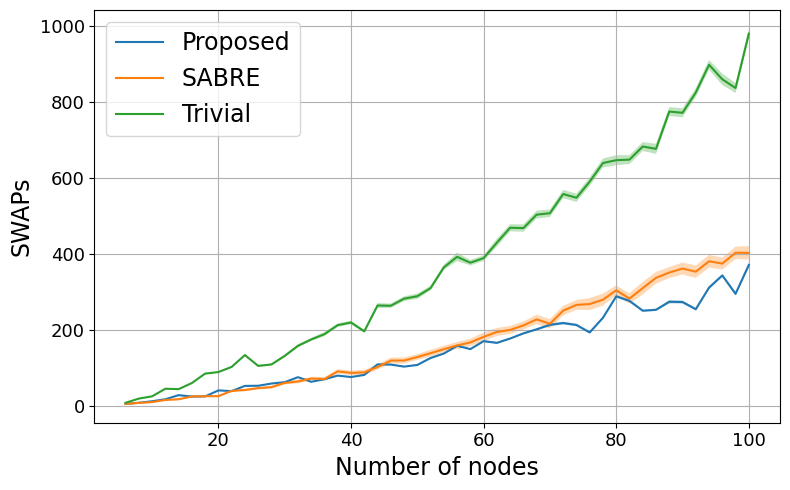

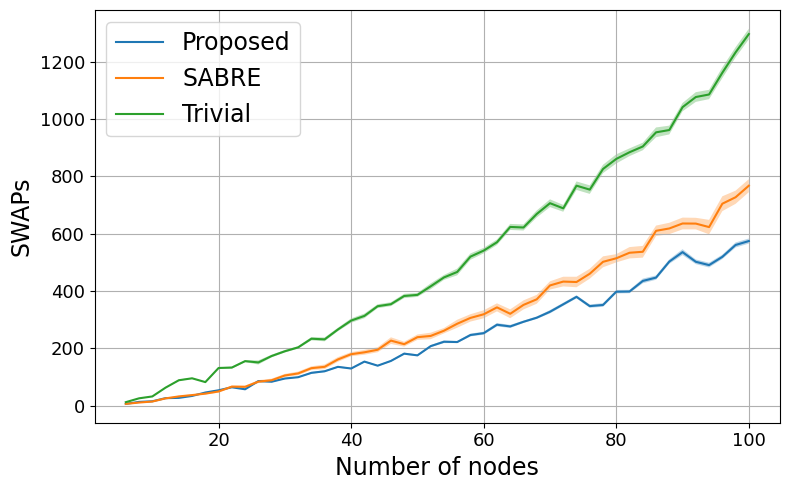

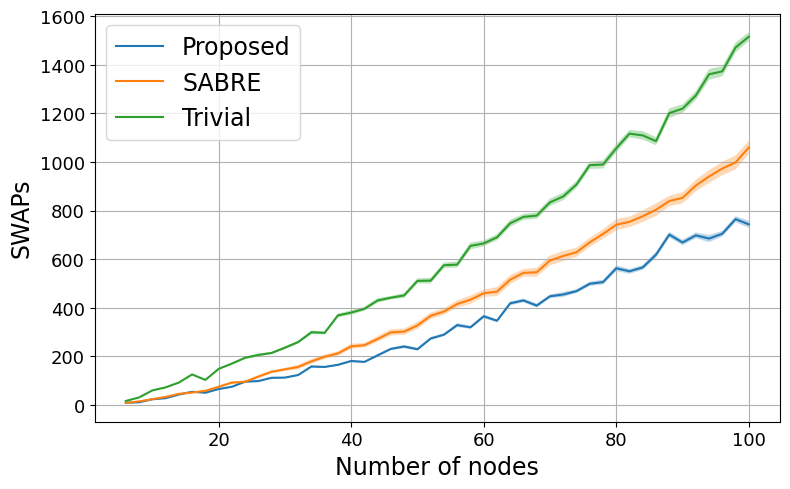

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

Fiedler Mapped

In [30]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='1D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

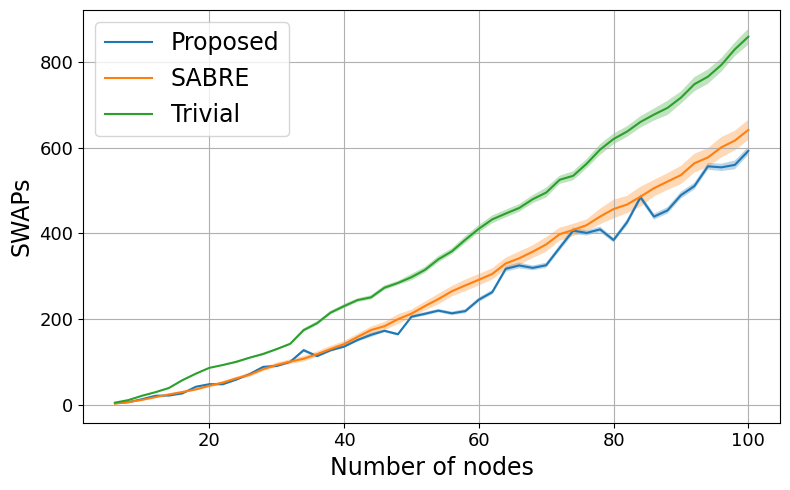

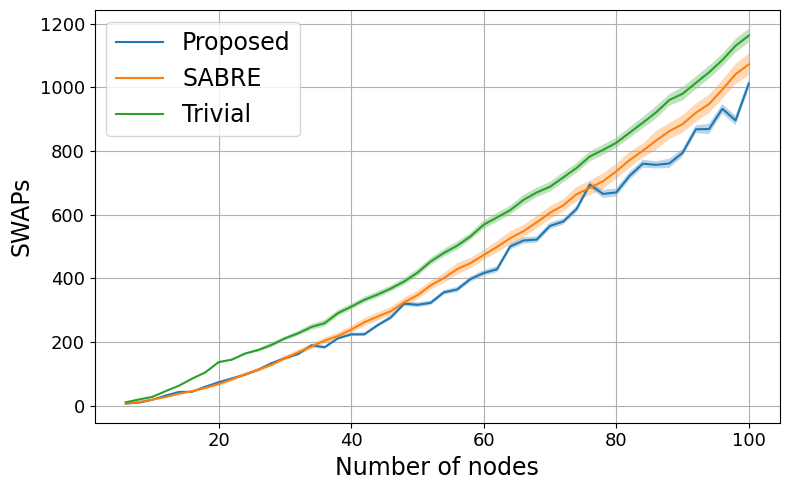

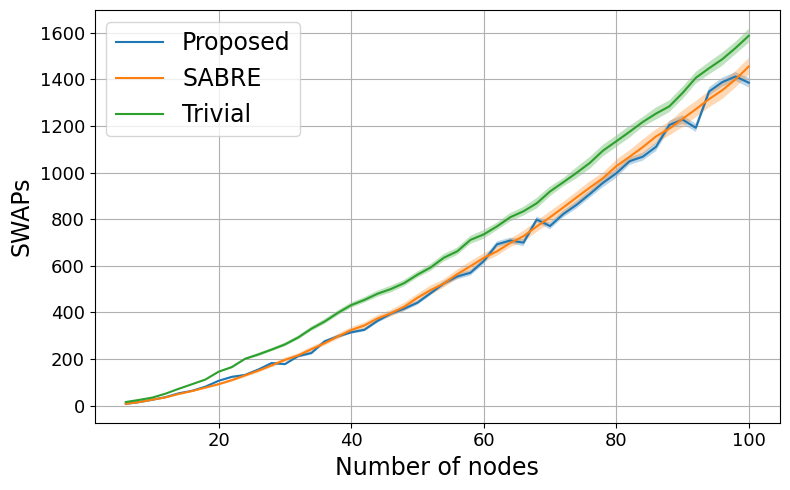

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [32]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=2, normalize_laplacian=True)

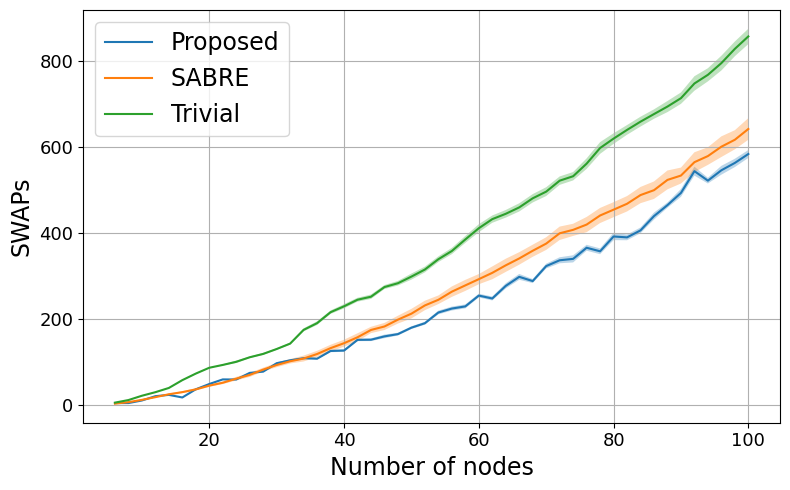

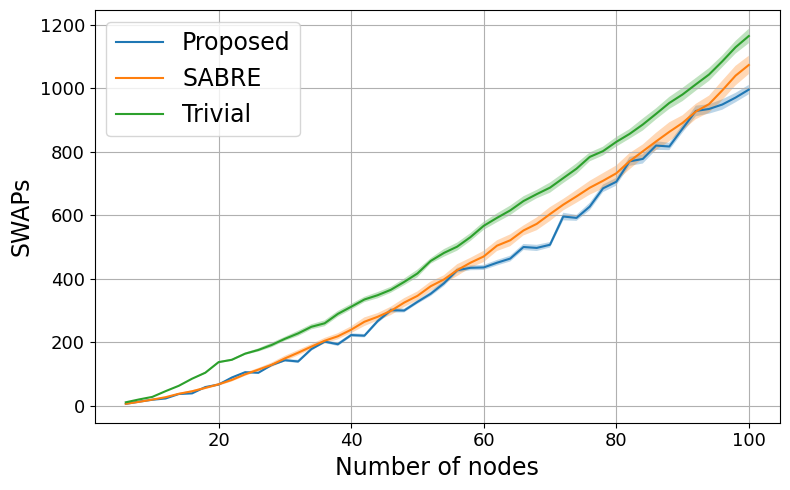

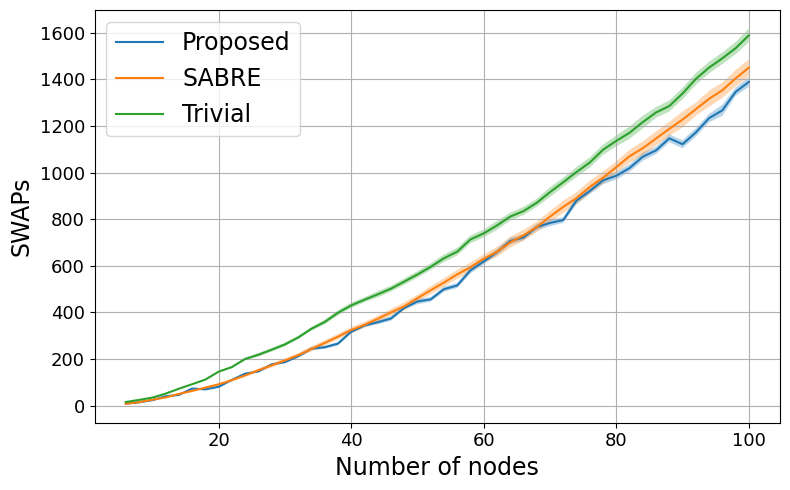

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [35]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=3, normalize_laplacian=True)

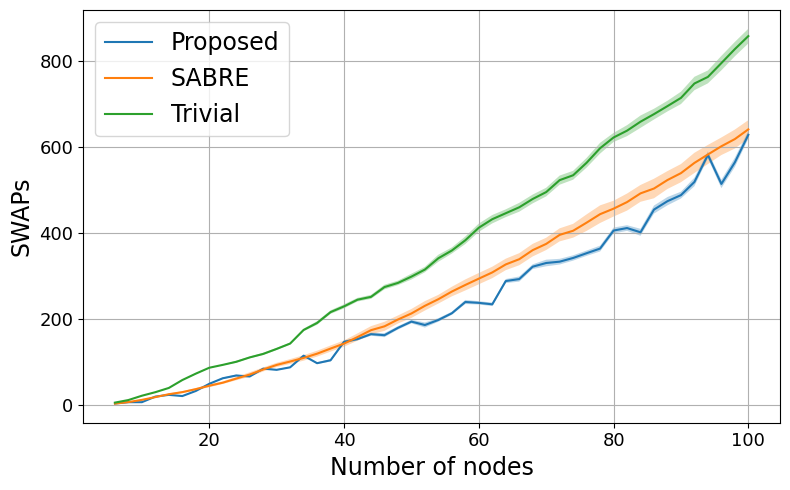

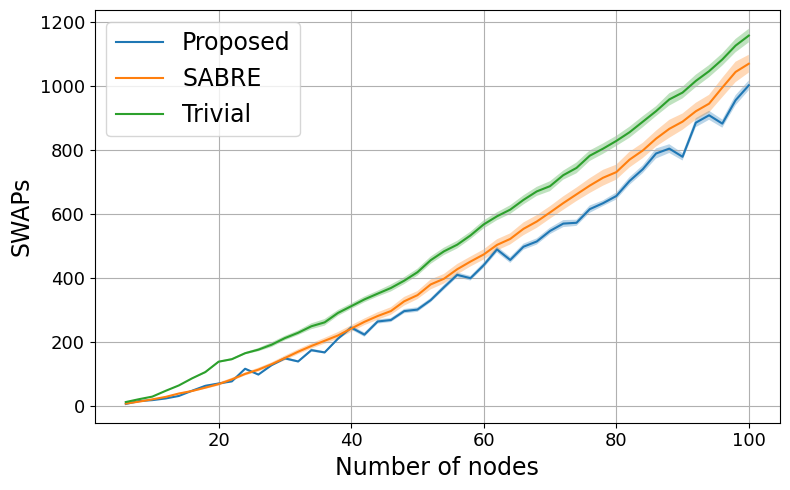

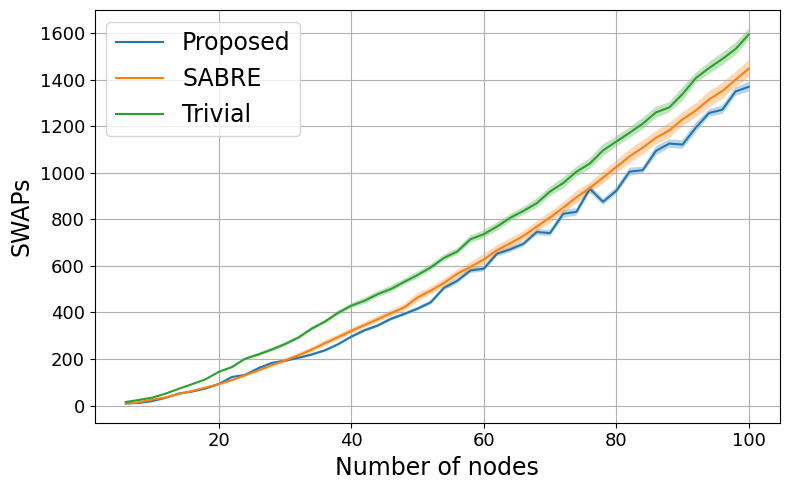

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [37]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=5, normalize_laplacian=True)

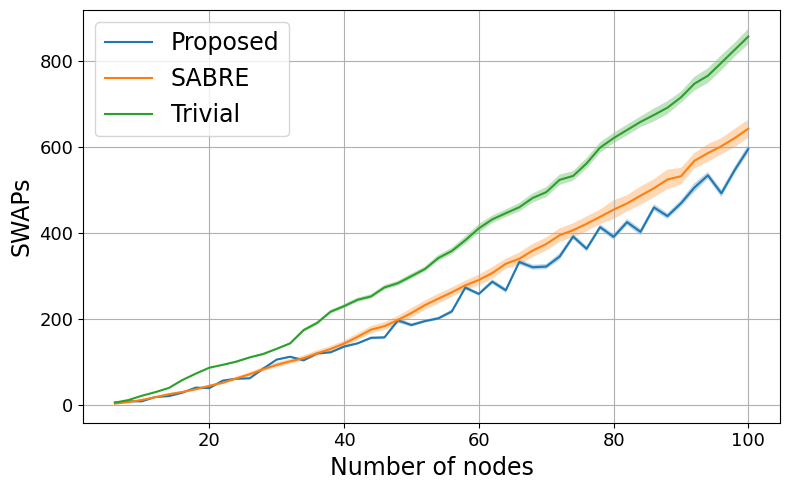

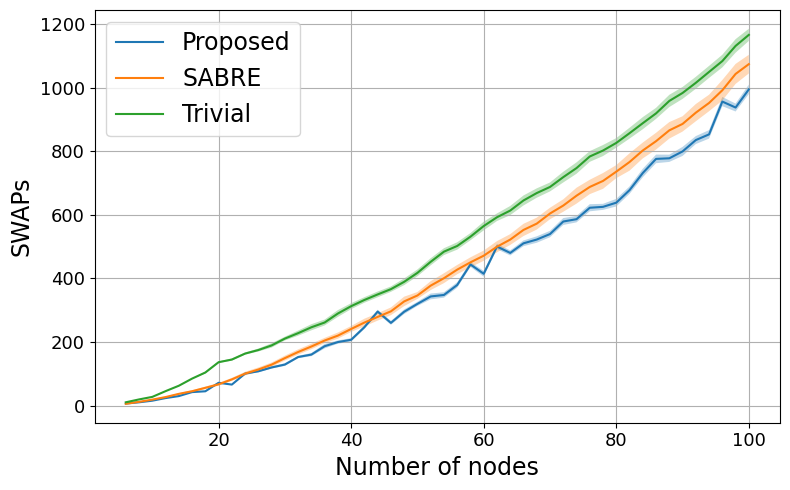

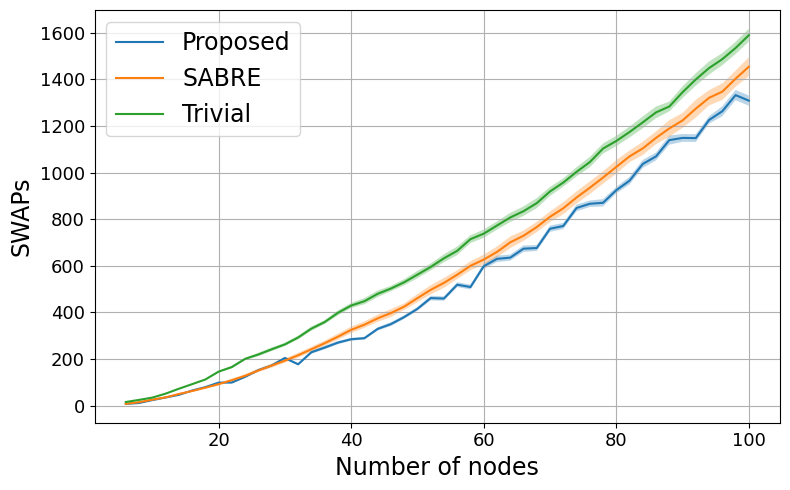

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## 2Q-Gate Counts

Fiedler Mapped

In [39]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=100, node_list=nodes_reg, tech='1D',
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

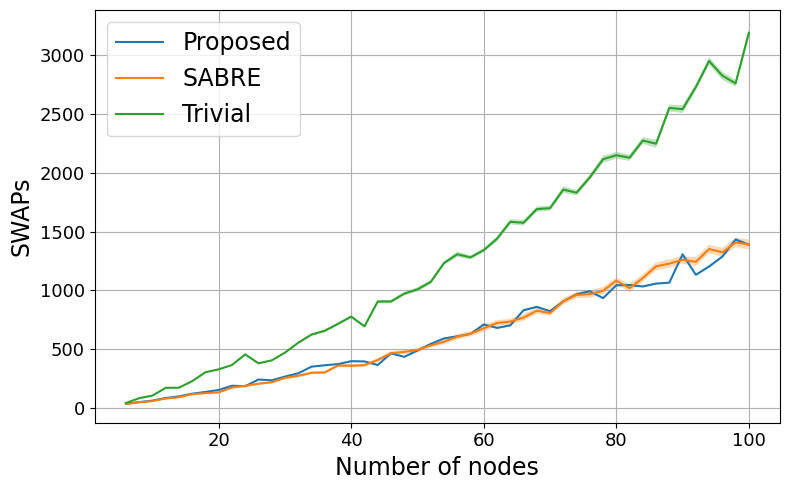

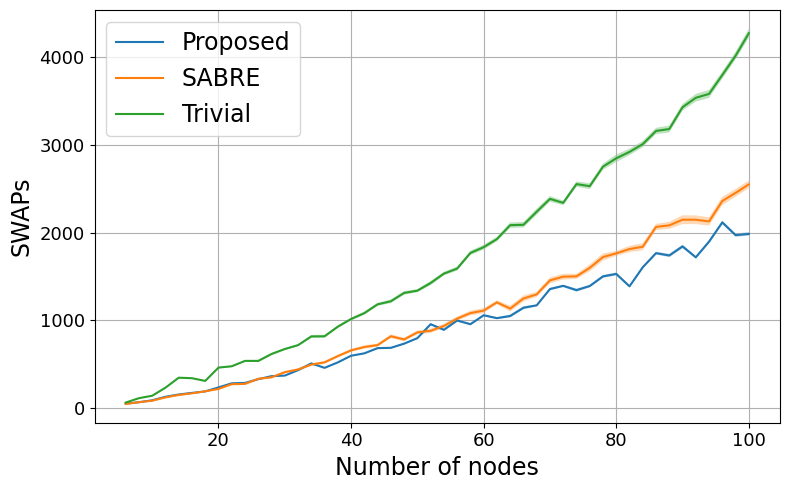

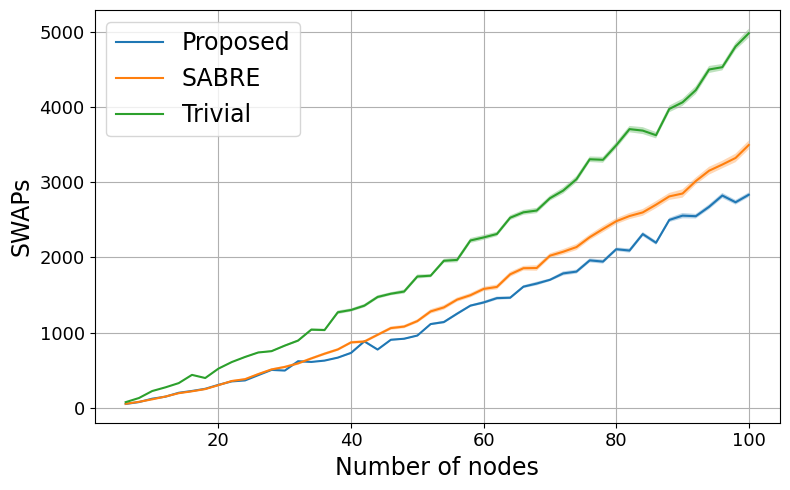

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [41]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

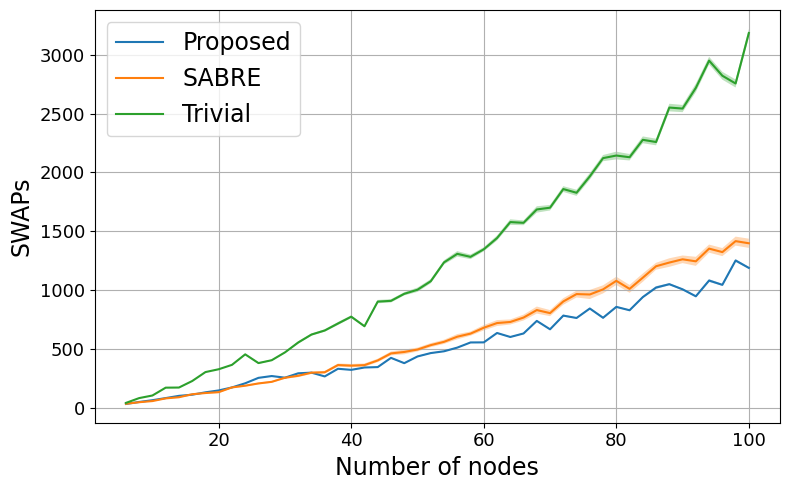

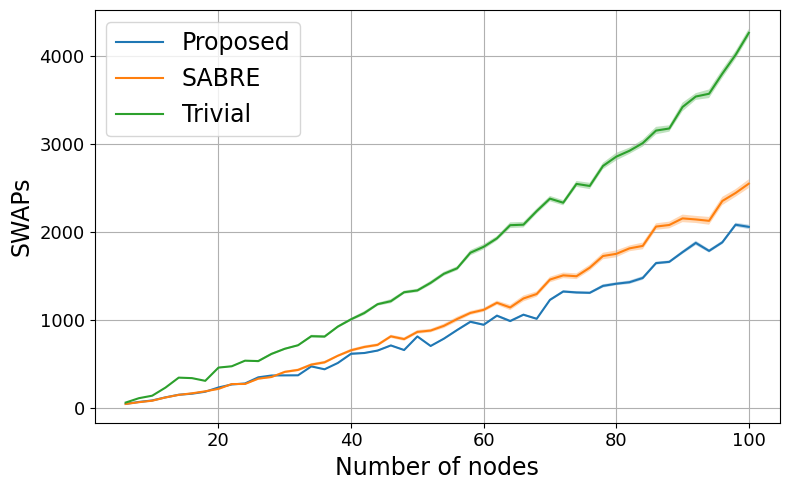

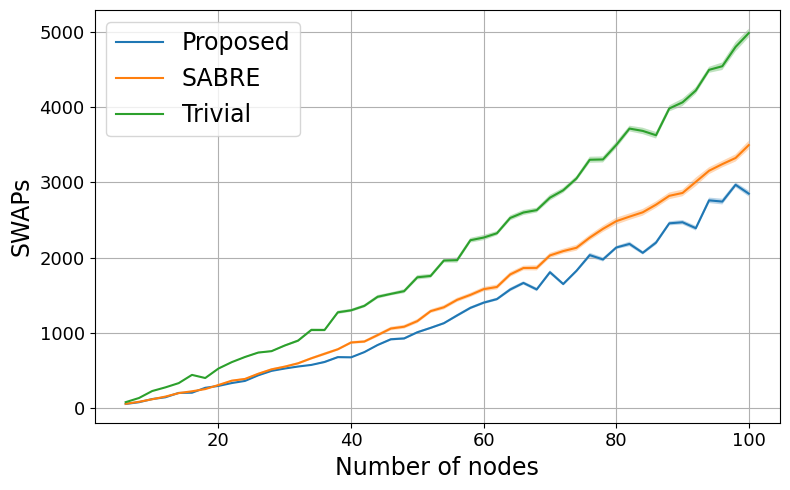

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [43]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

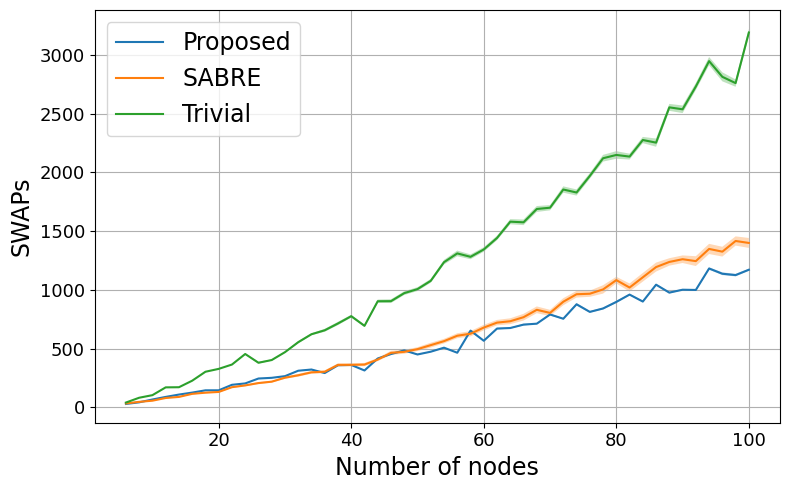

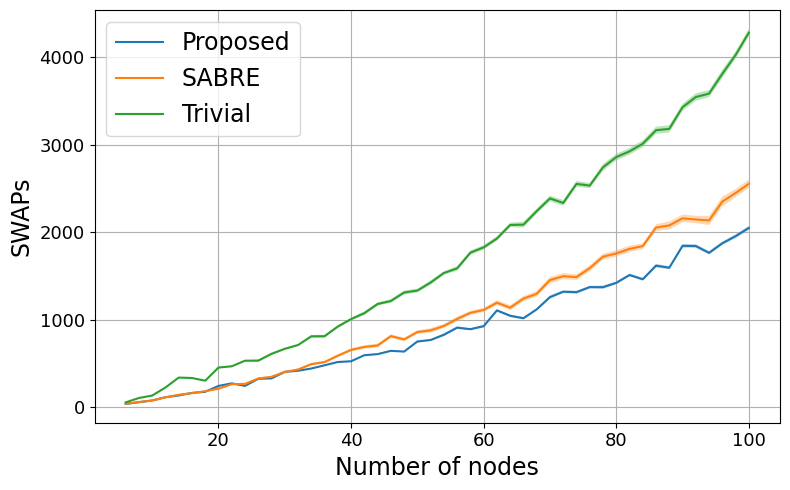

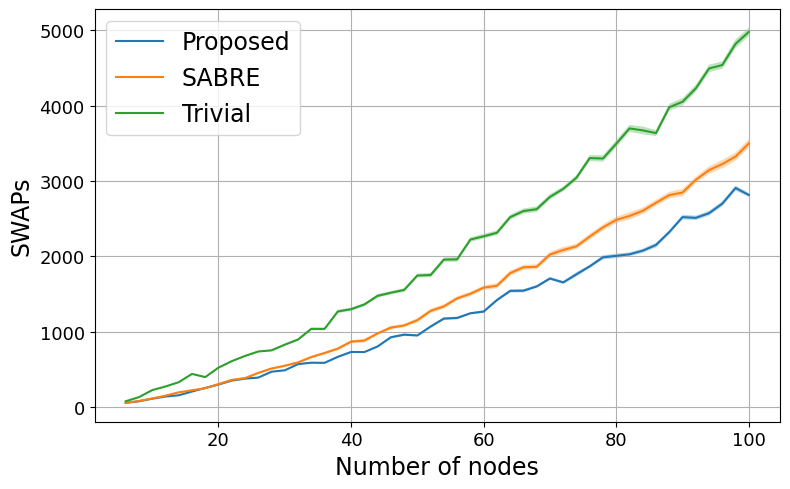

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [45]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

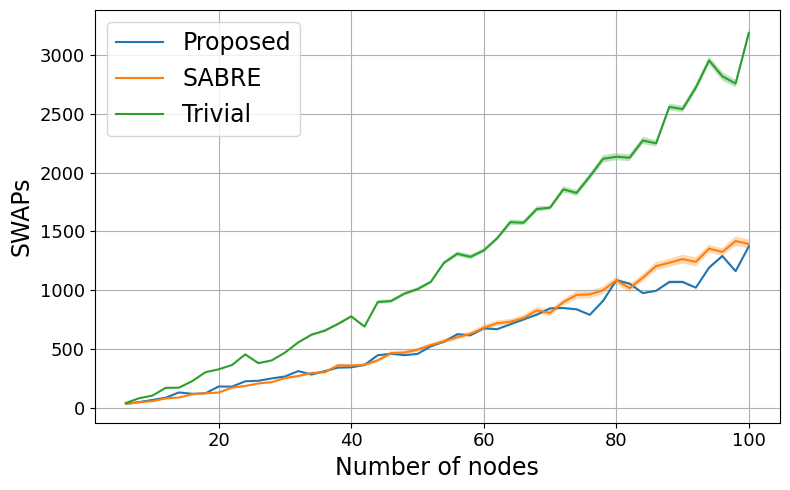

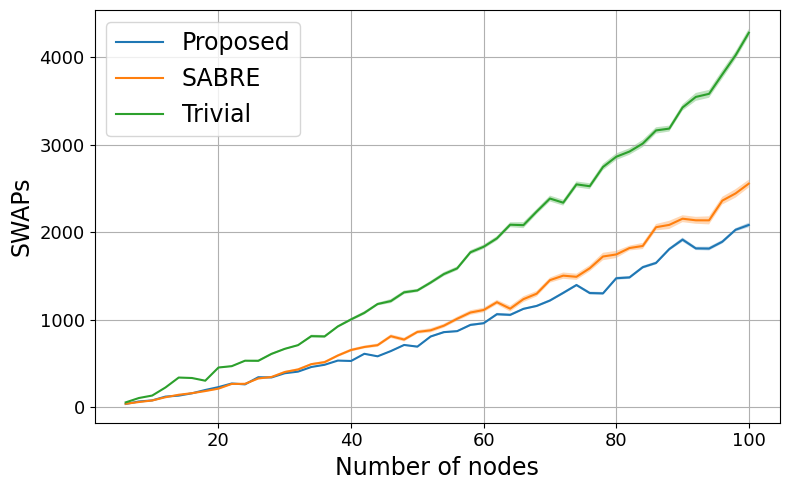

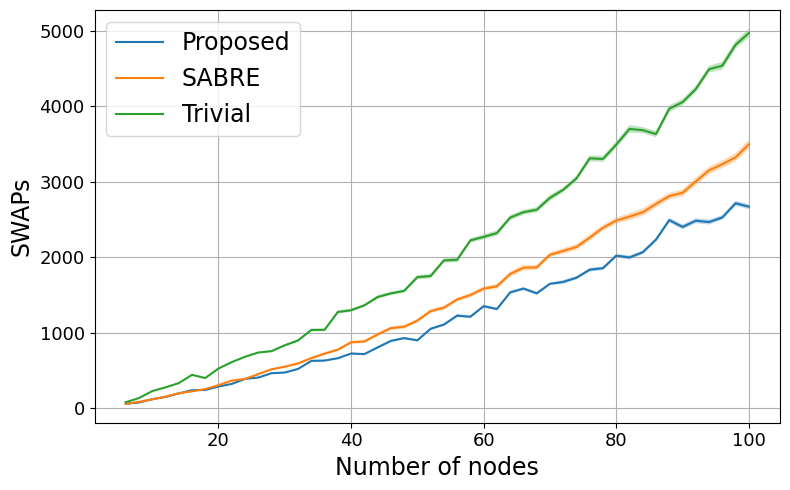

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

Fiedler Mapped

In [47]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='1D', use_custom=True, opt_level=3, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

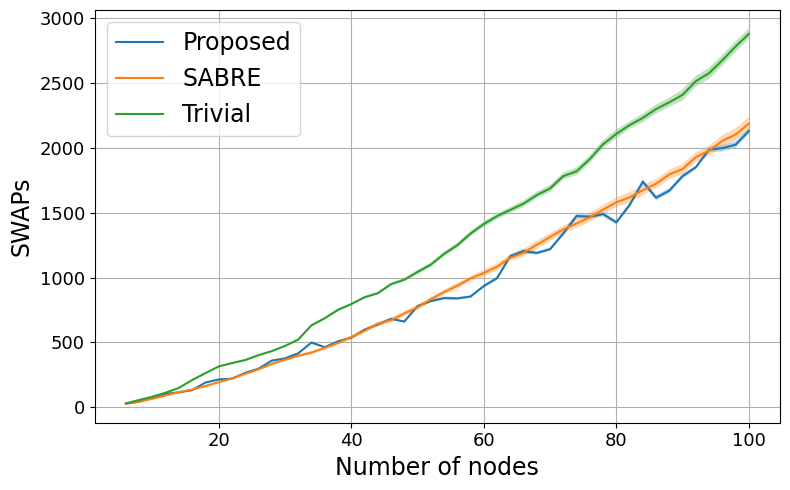

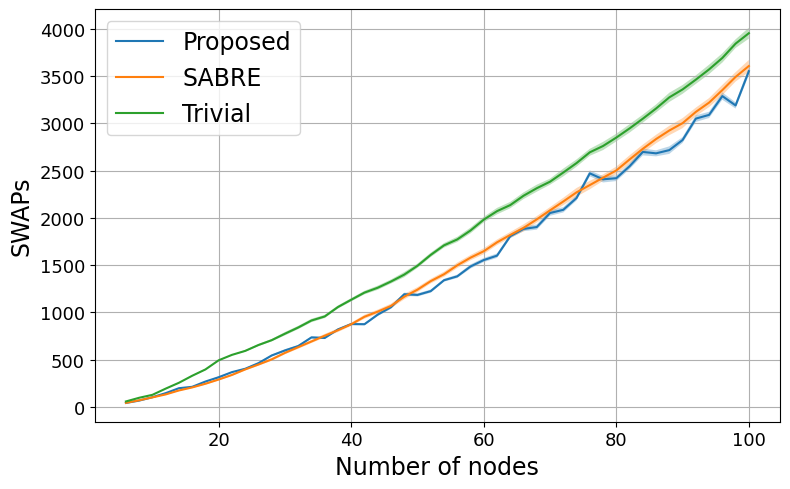

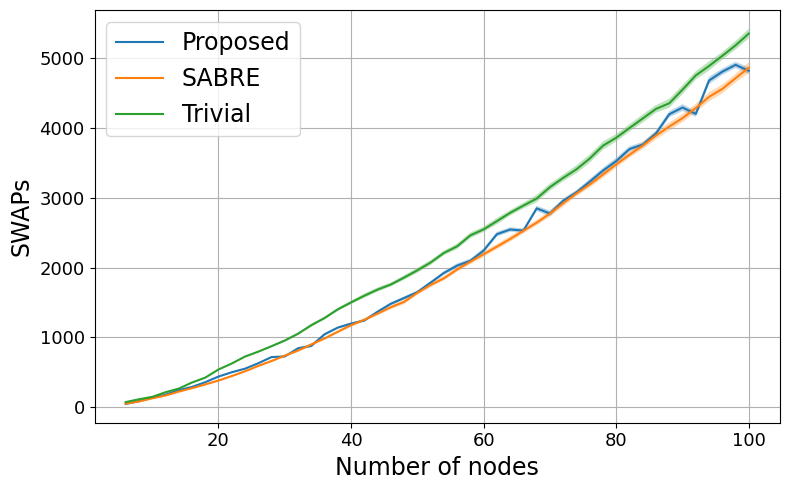

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [49]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='2D', use_custom=True, opt_level=3, reps=1, k=2, normalize_laplacian=True)

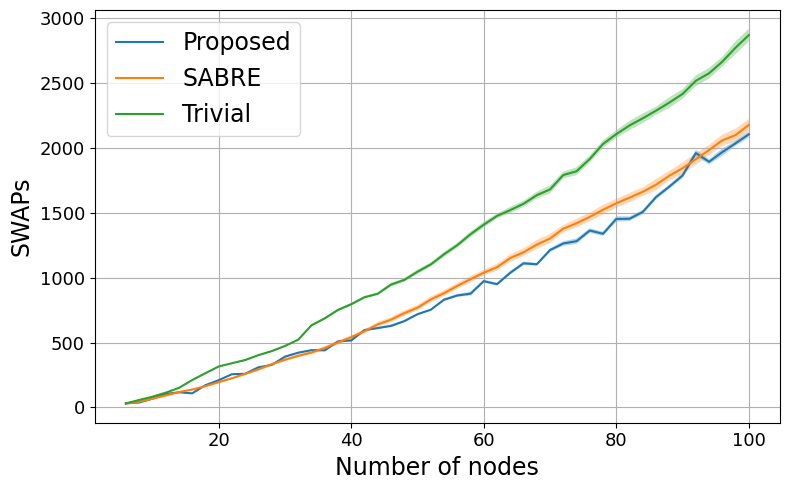

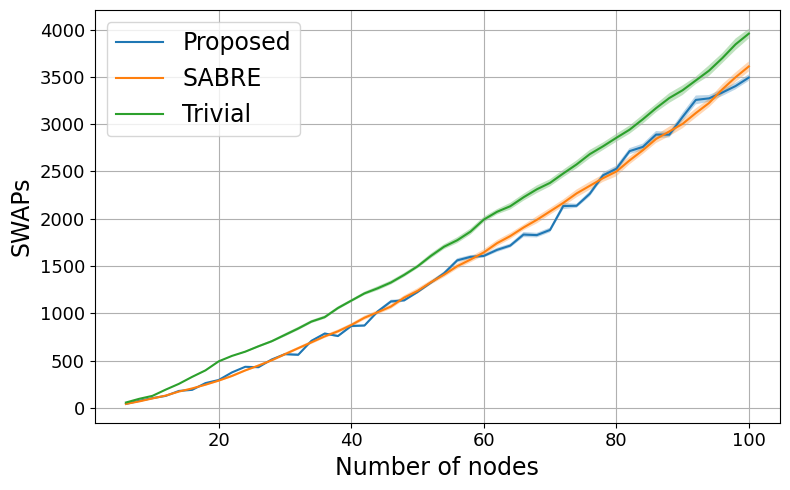

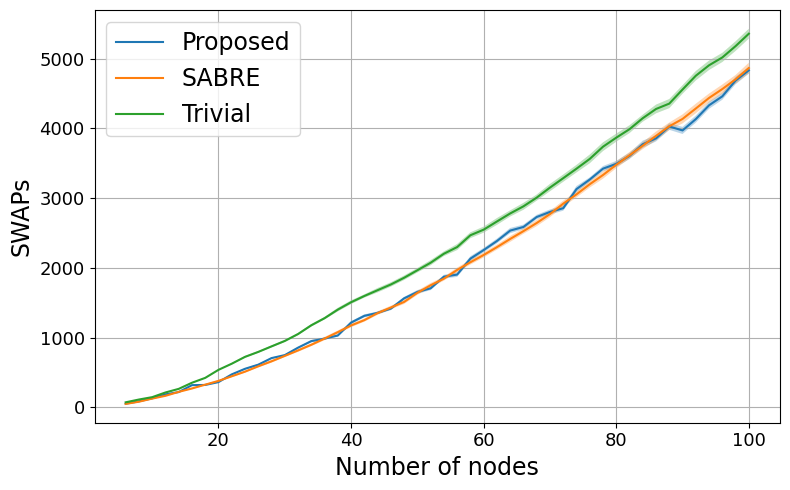

In [50]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [51]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='2D', use_custom=True, opt_level=3, reps=1, k=3, normalize_laplacian=True)

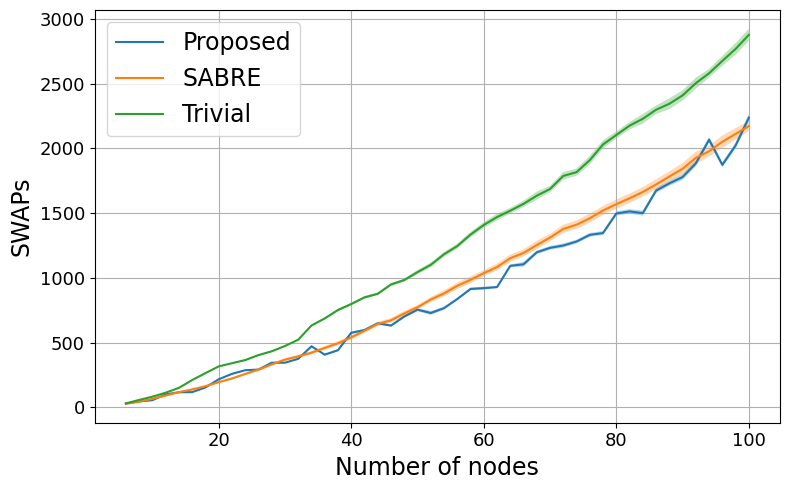

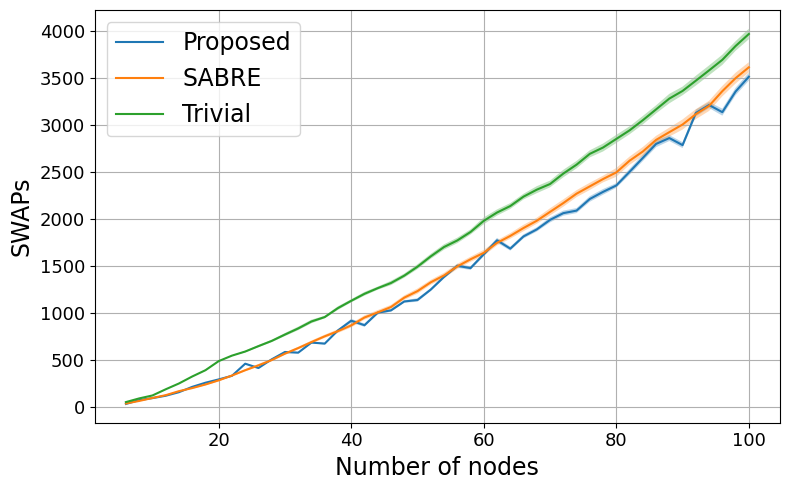

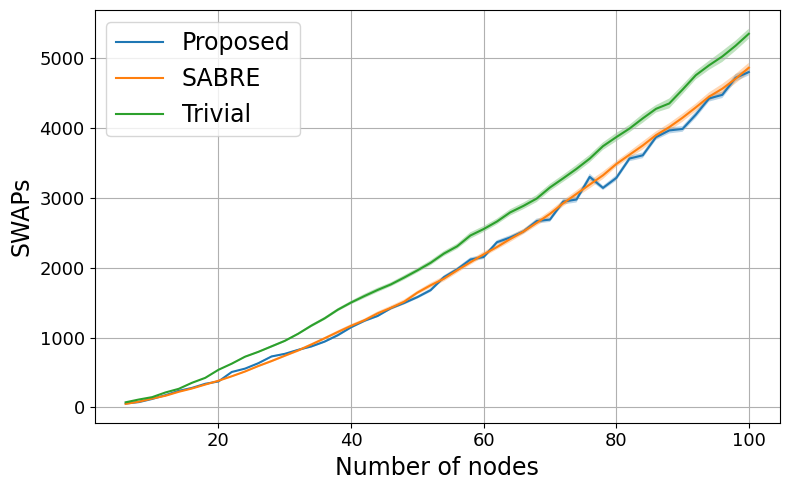

In [52]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [54]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='2D', use_custom=True, opt_level=3, reps=1, k=5, normalize_laplacian=True)

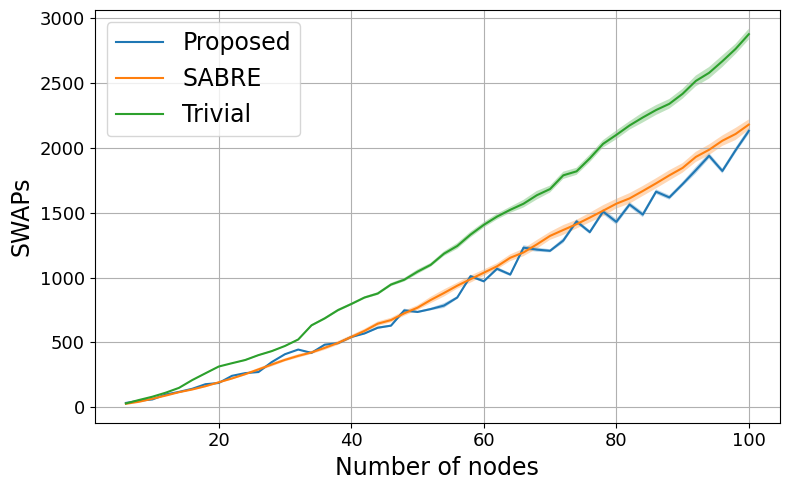

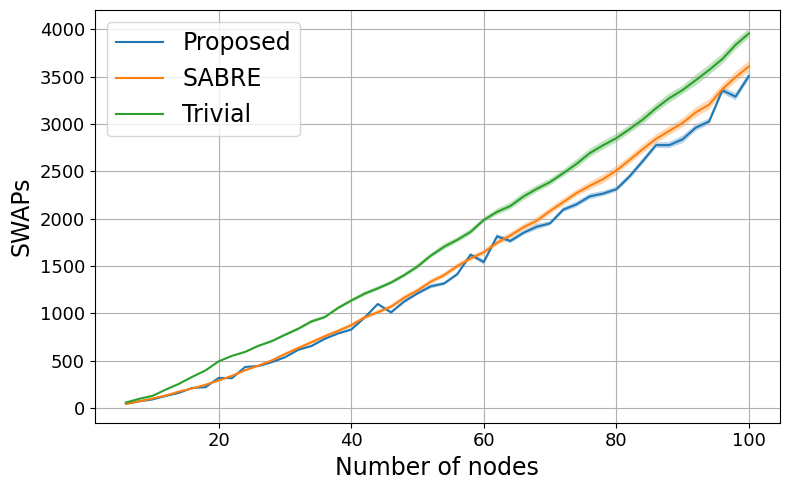

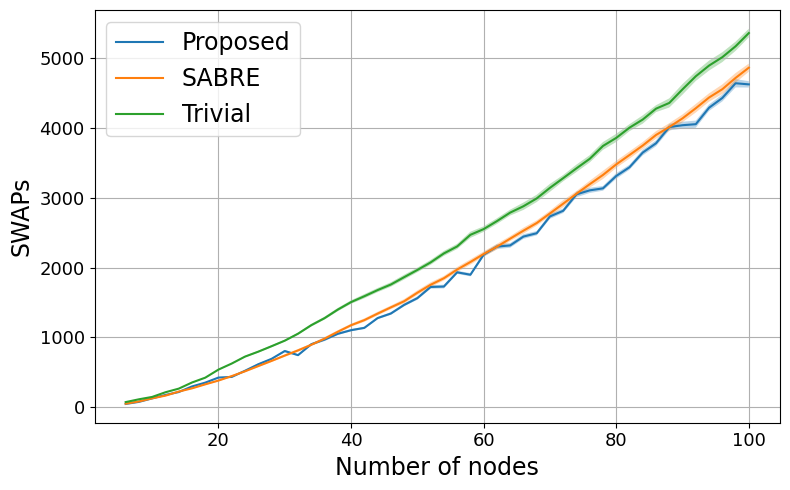

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Zoomed in

In [81]:
backend = FakeBrisbane()

Fiedler Mapped

In [82]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=10, node_list=nodes_reg, tech='1D',
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

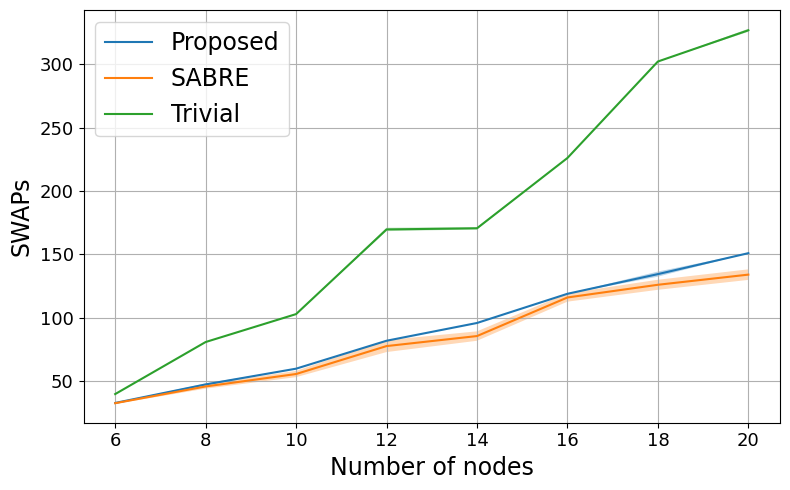

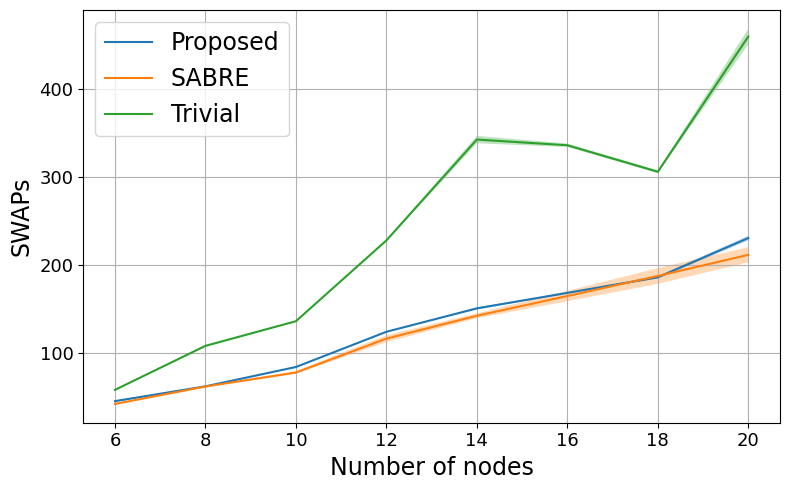

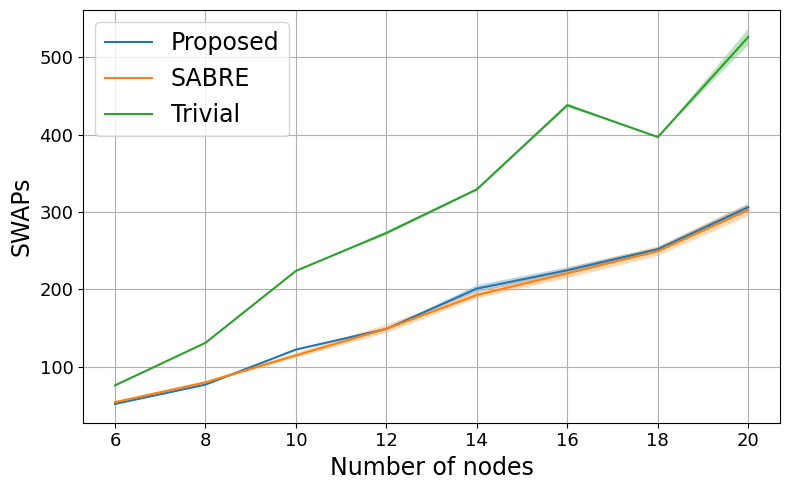

In [83]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [84]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

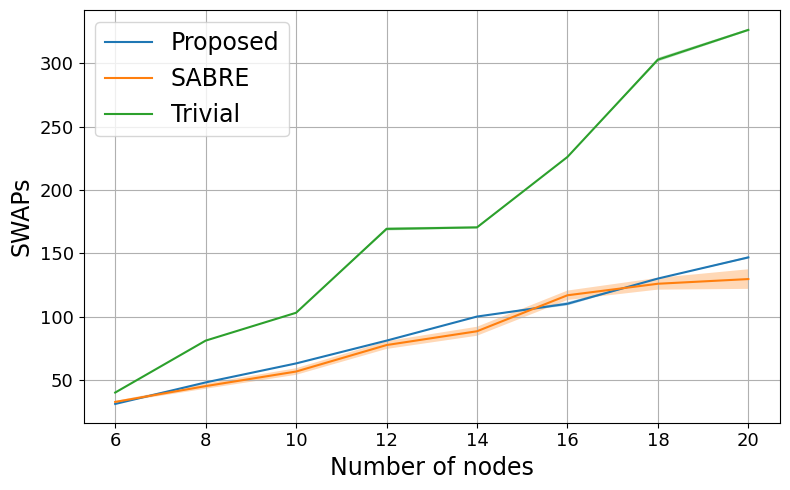

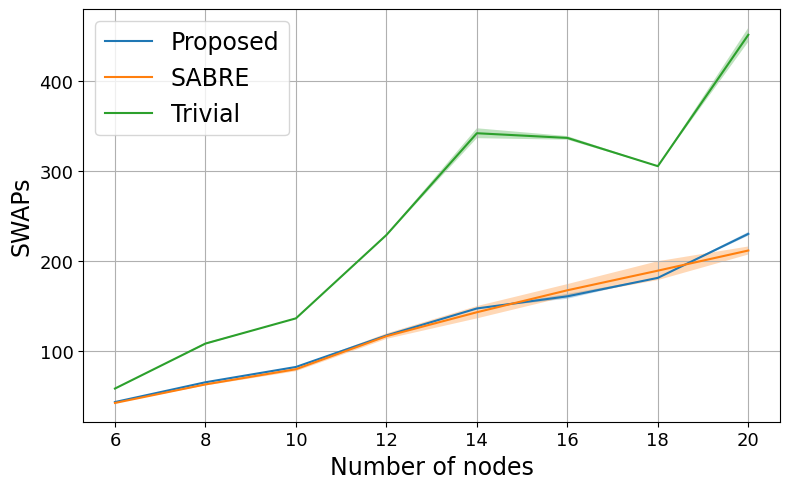

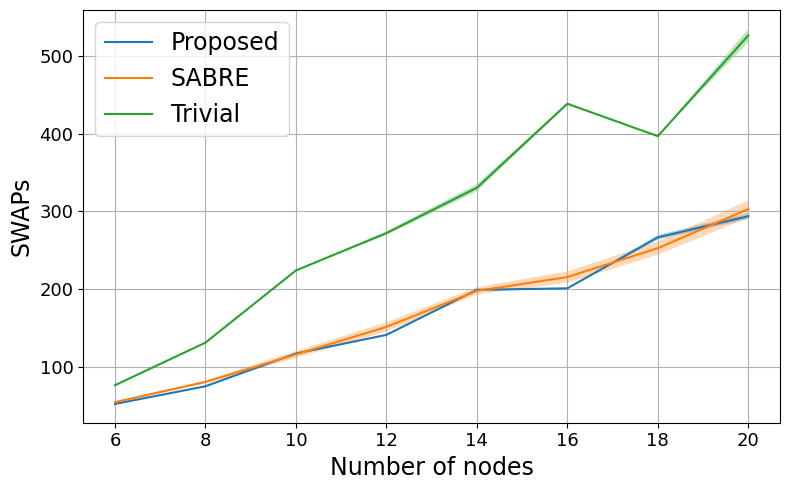

In [85]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [86]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

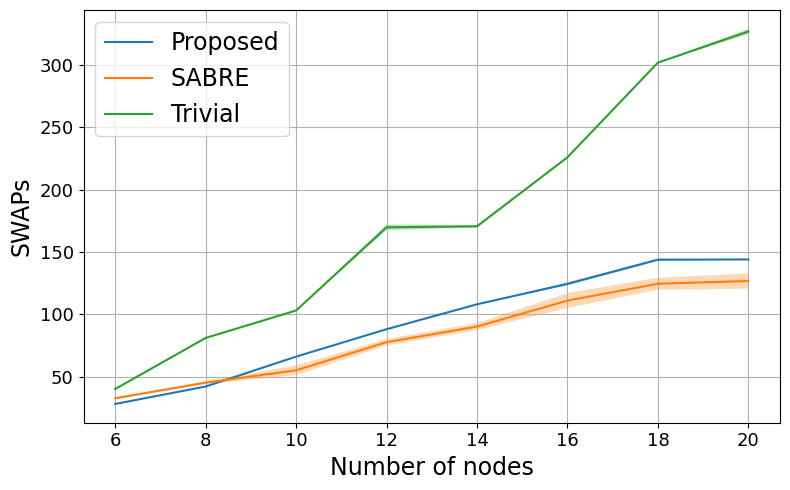

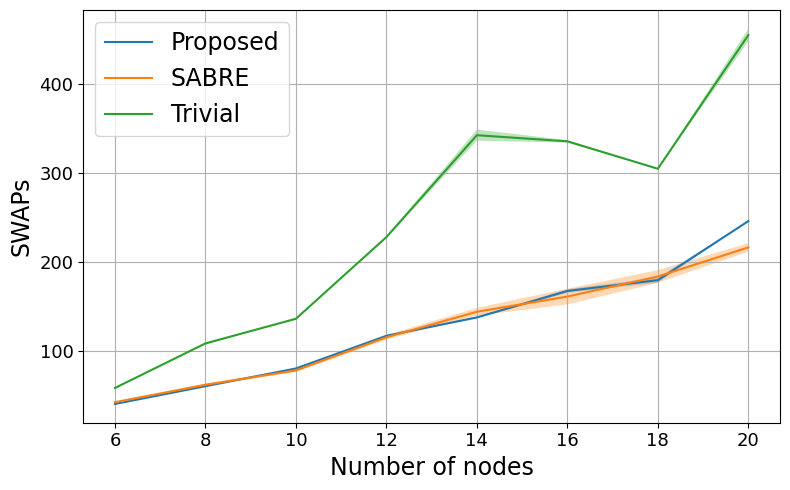

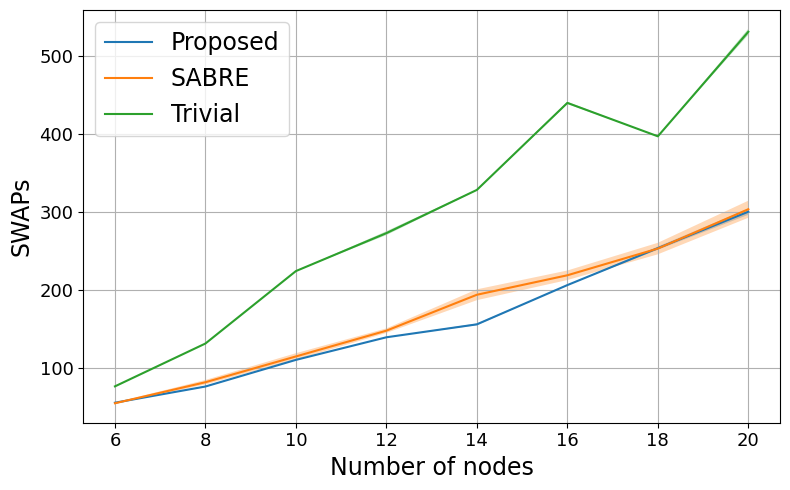

In [87]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [88]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='ecr', use_custom=True, opt_level=3, reps=1)

Iterating for number of nodes:   0%|          | 0/8 [00:00<?, ?it/s]

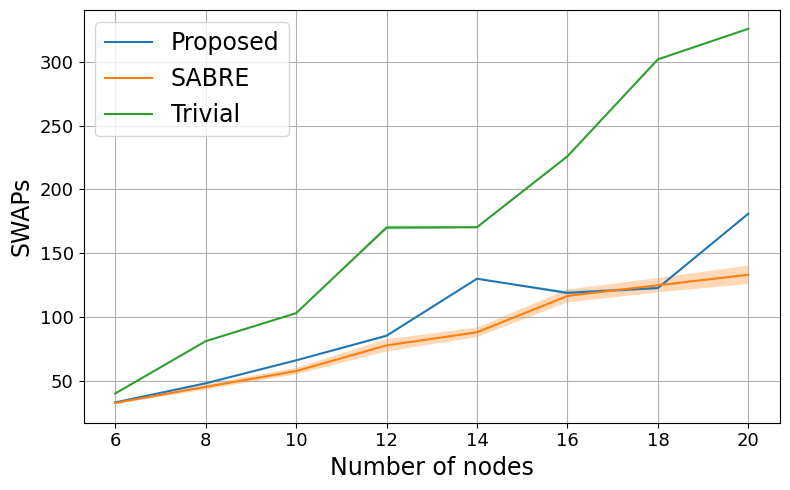

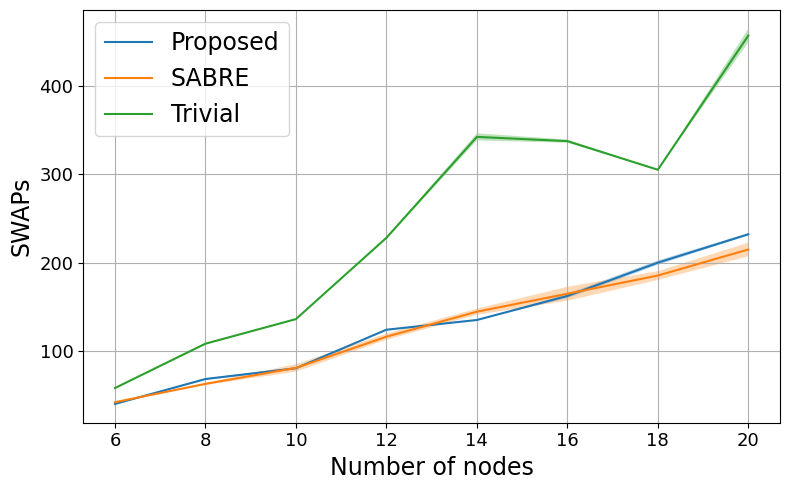

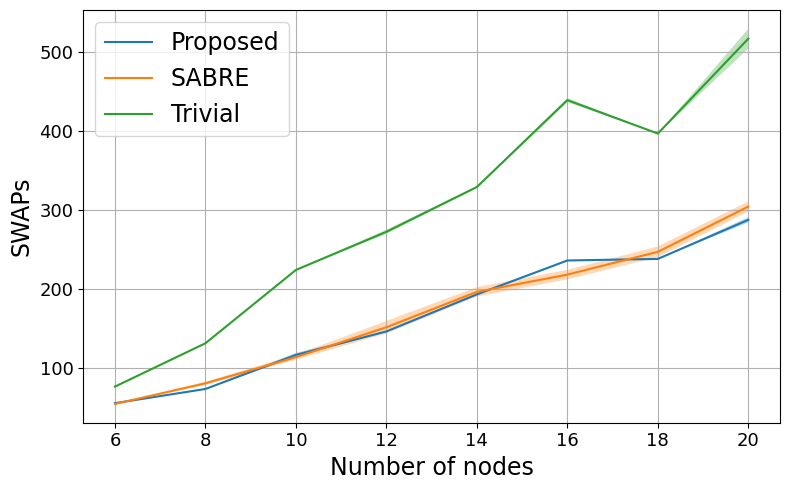

In [89]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

Fiedler Mapped

In [90]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='1D', use_custom=True, opt_level=3, reps=1)

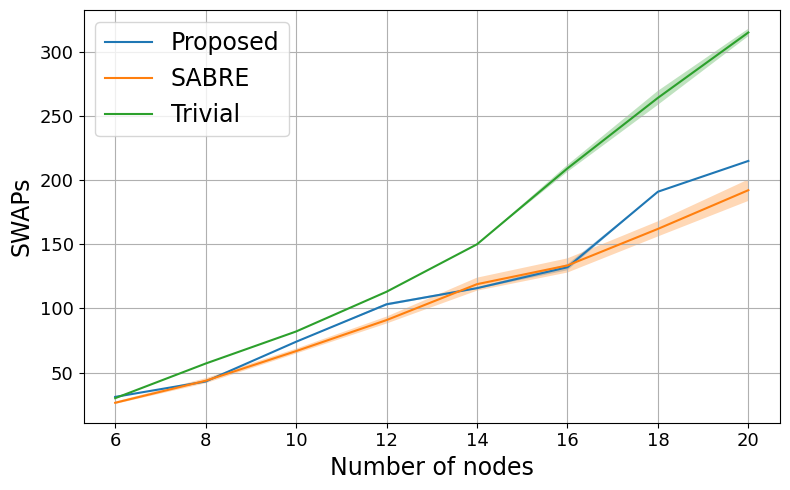

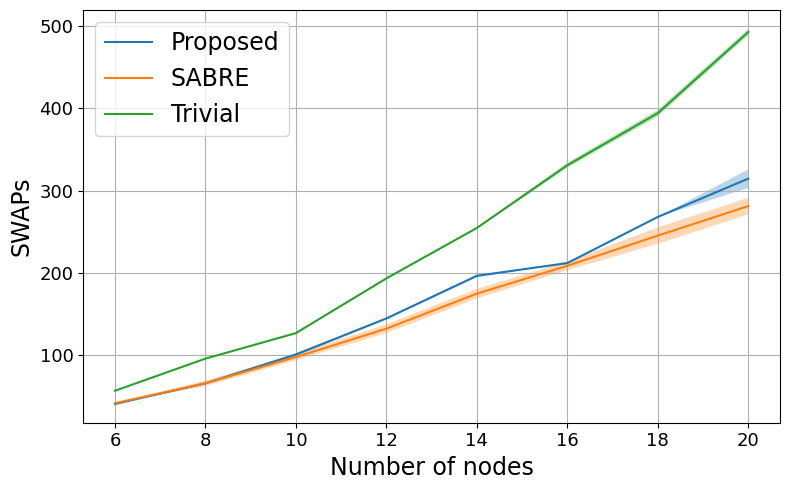

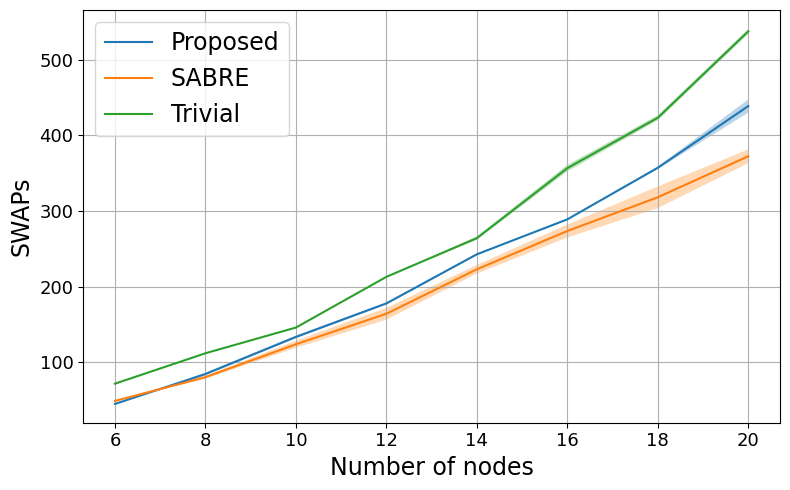

In [91]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [92]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='2D', use_custom=True, opt_level=3, reps=1, k=2, normalize_laplacian=True)

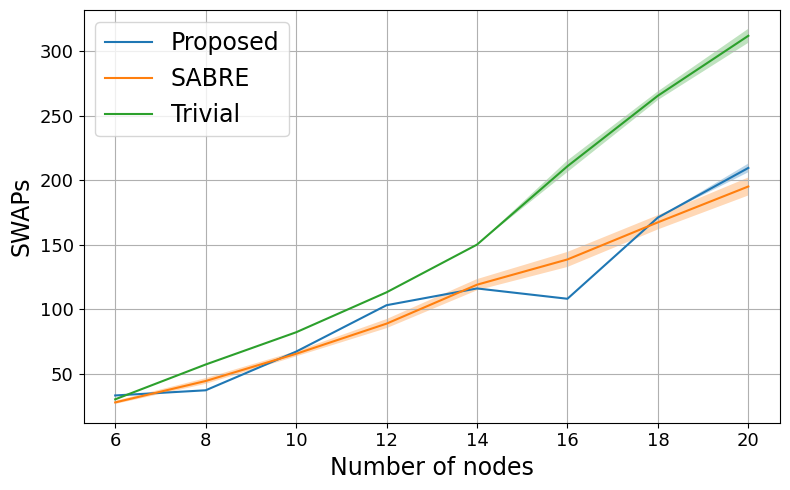

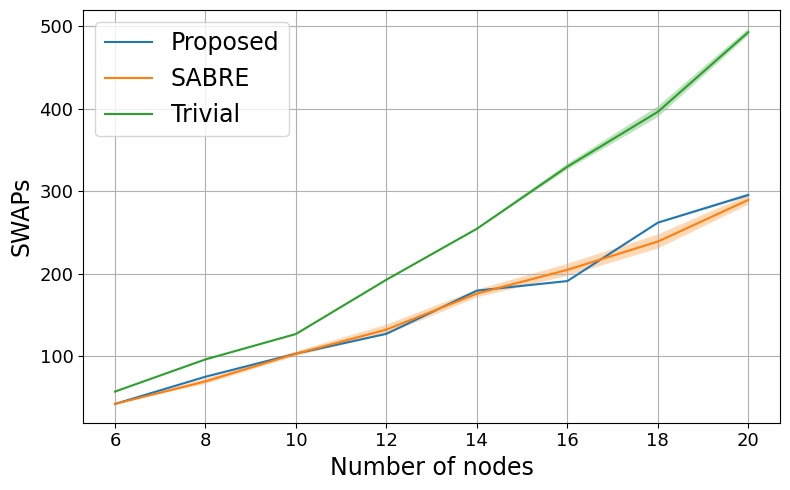

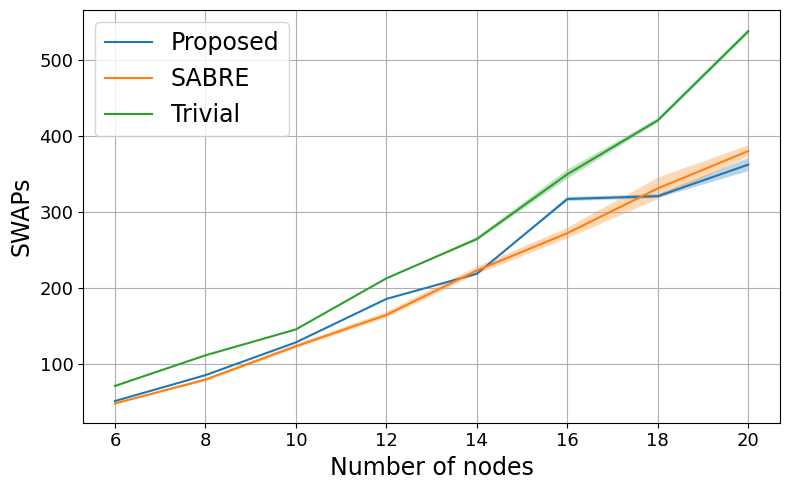

In [93]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [94]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='2D', use_custom=True, opt_level=3, reps=1, k=3, normalize_laplacian=True)

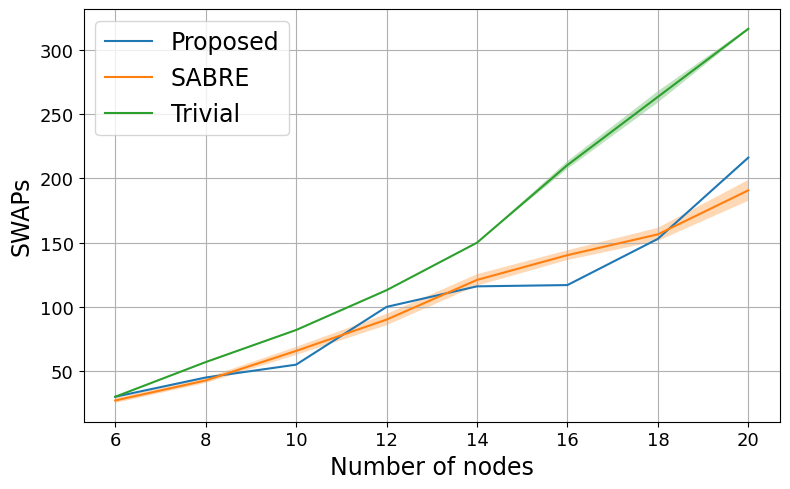

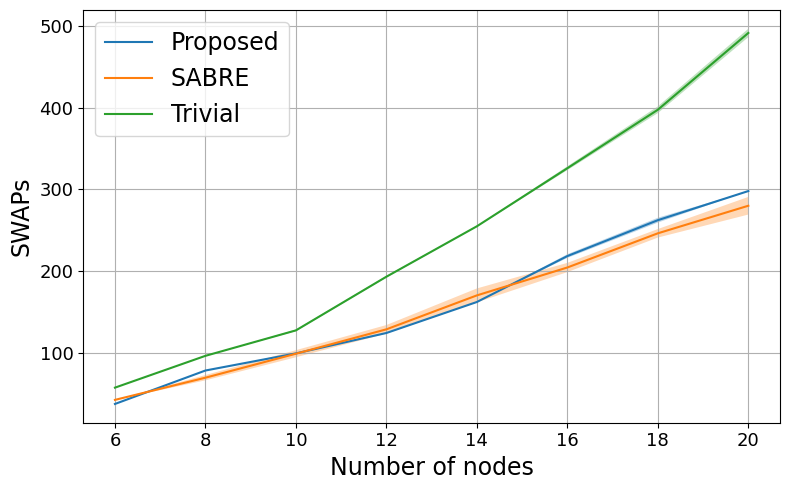

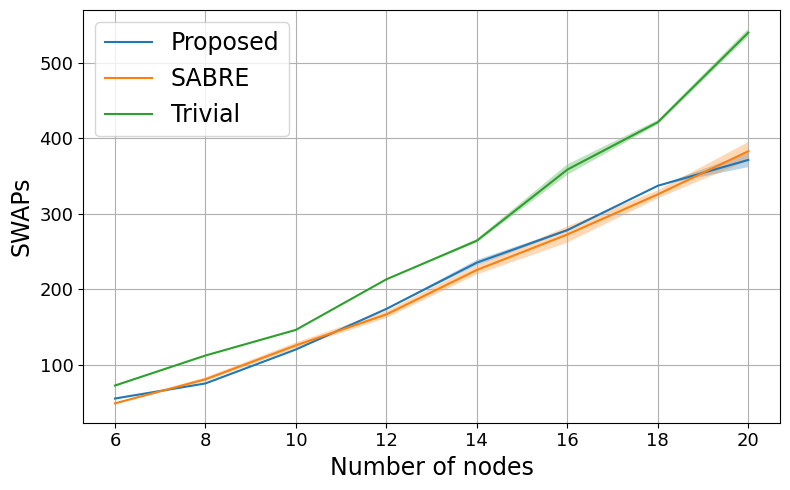

In [95]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [96]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='ecr', tech='2D', use_custom=True, opt_level=3, reps=1, k=5, normalize_laplacian=True)

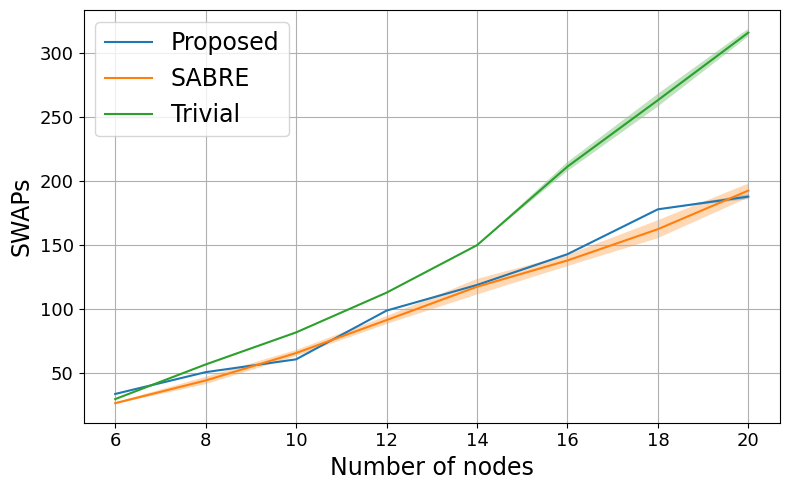

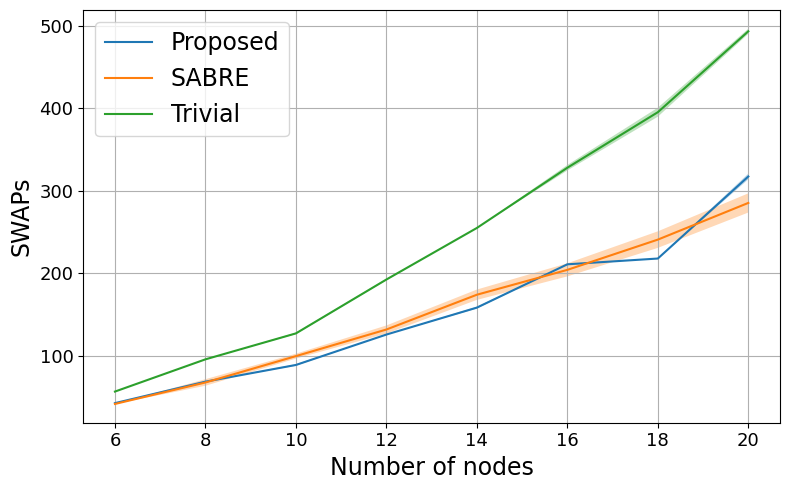

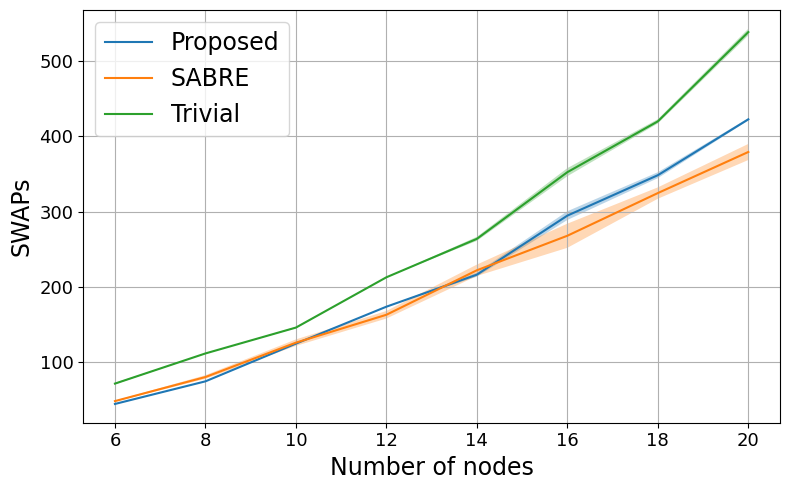

In [97]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [98]:
backend = FakeTorino()

Fiedler Mapped

In [99]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=10, node_list=nodes_reg, tech='1D',
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

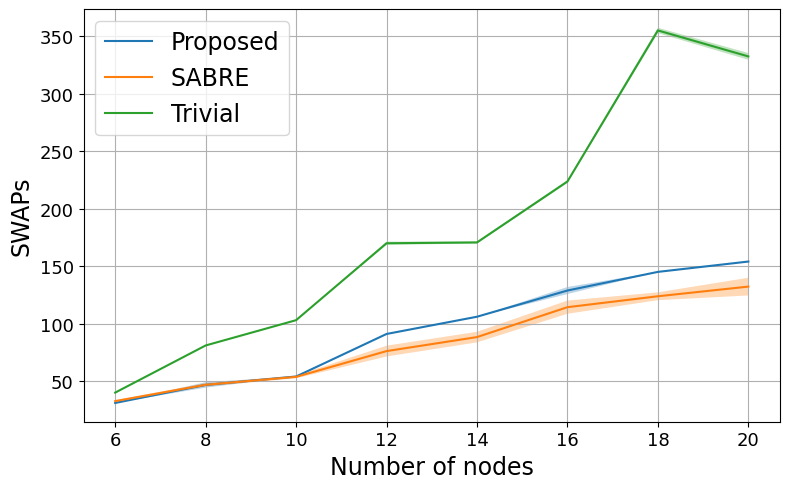

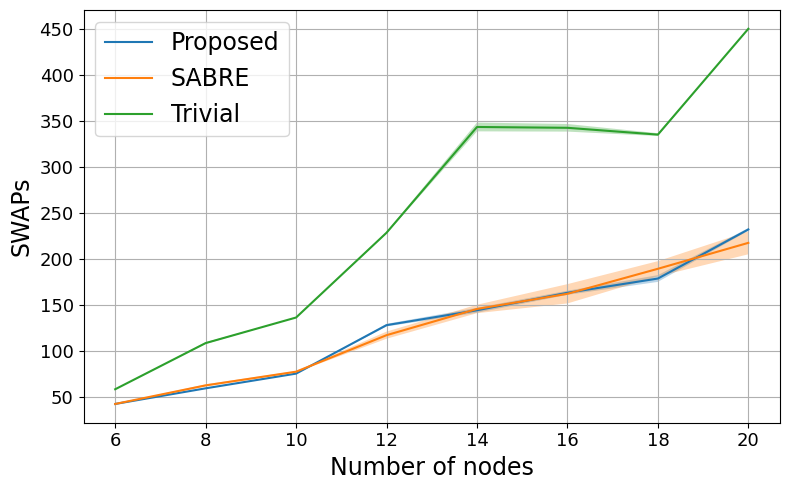

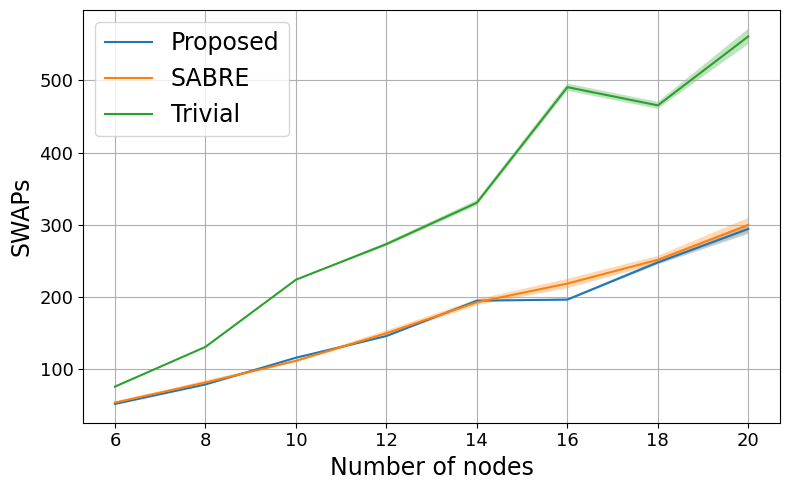

In [100]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [108]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

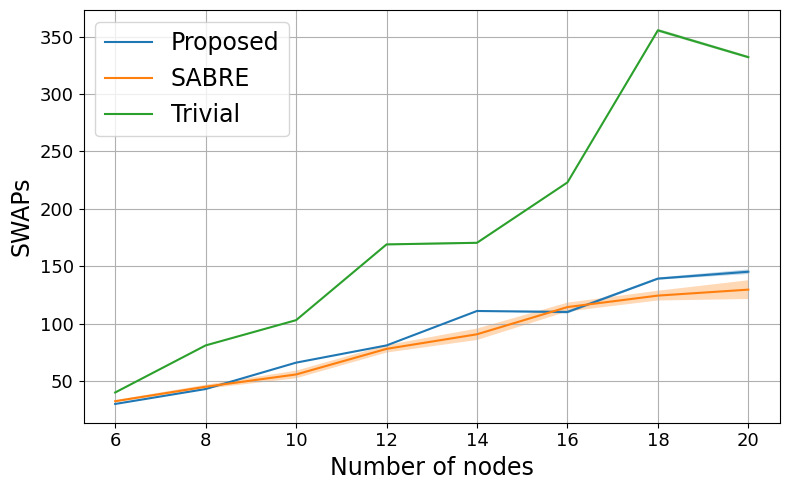

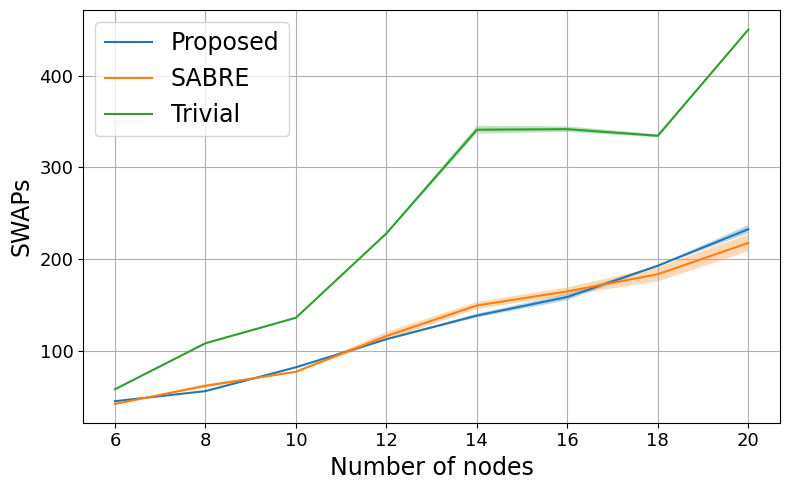

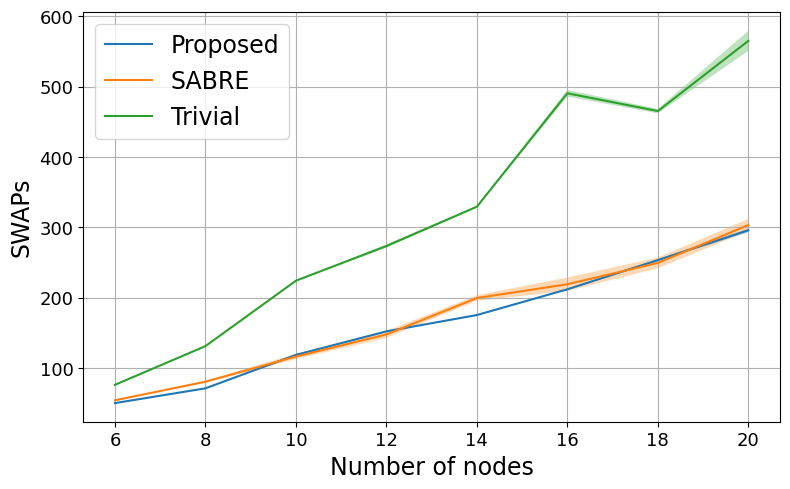

In [109]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [110]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

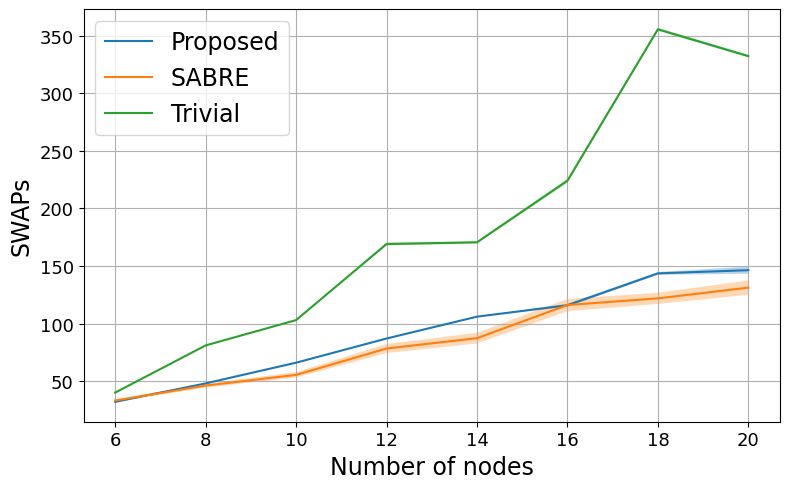

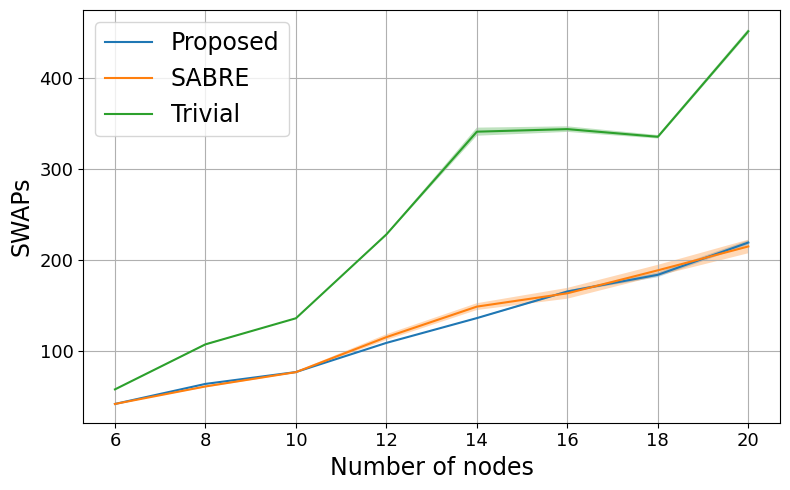

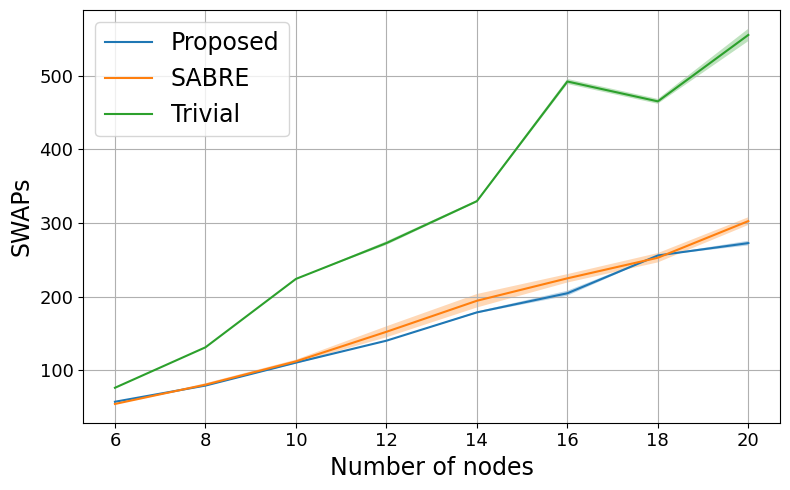

In [111]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [112]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 21, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

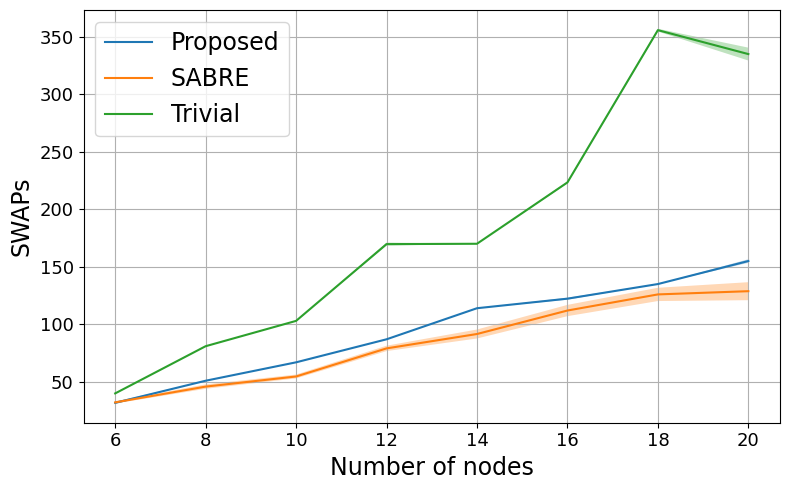

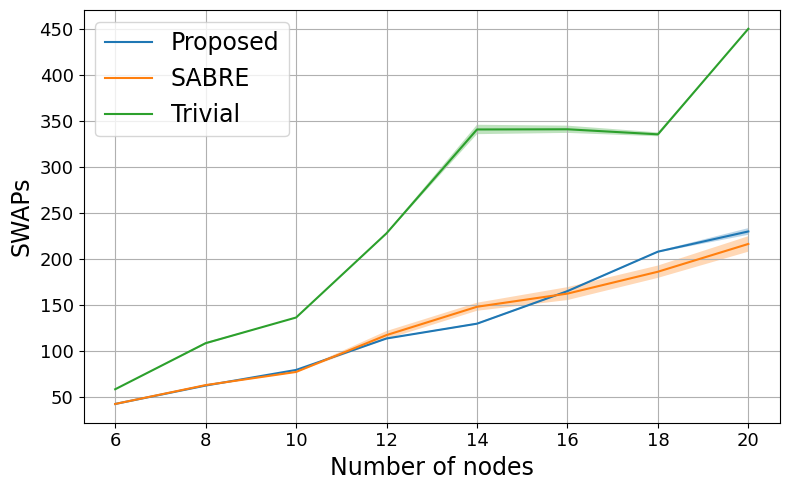

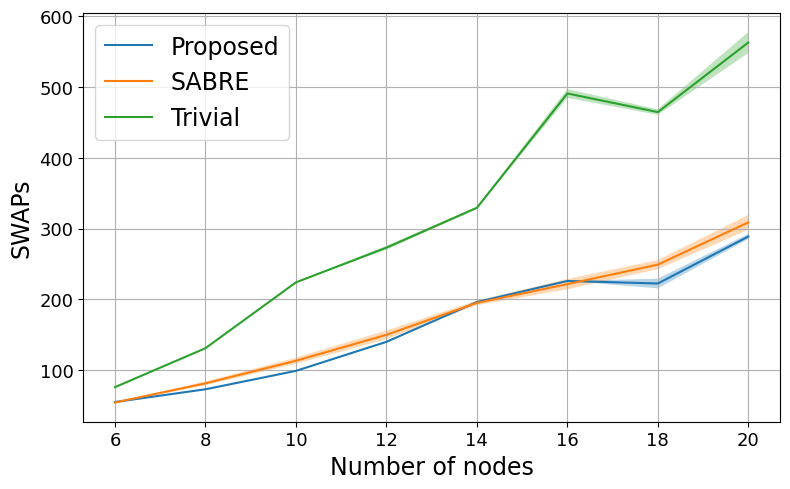

In [113]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

Fiedler Mapped

In [114]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='1D', use_custom=True, opt_level=3, reps=1)

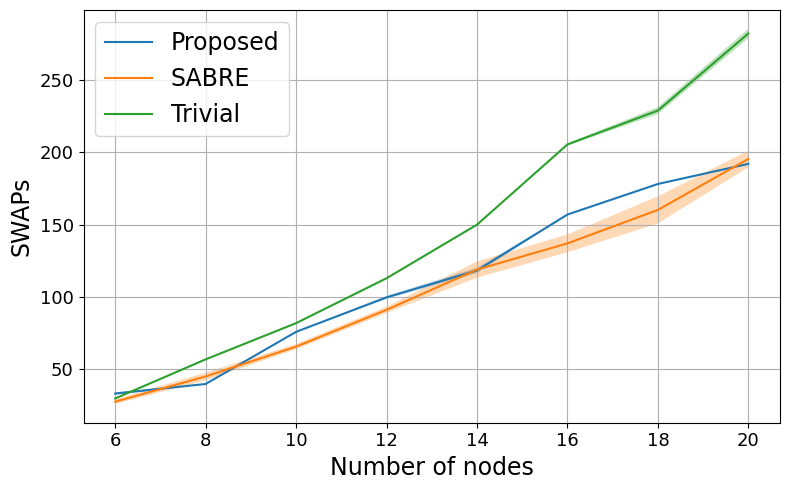

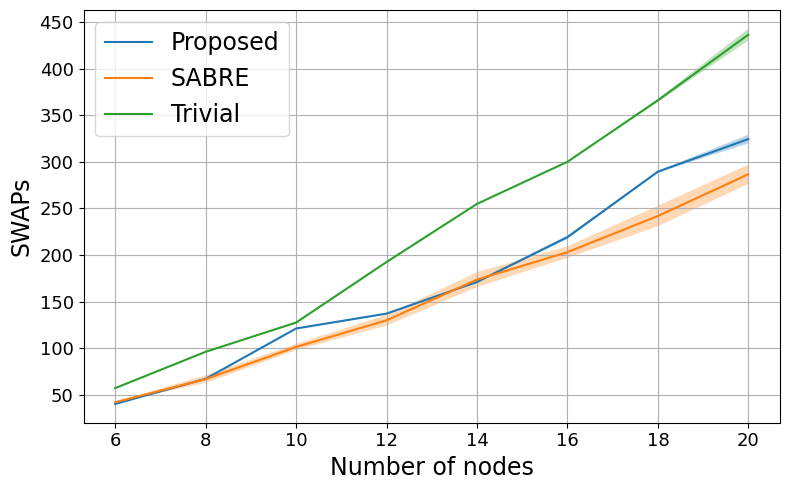

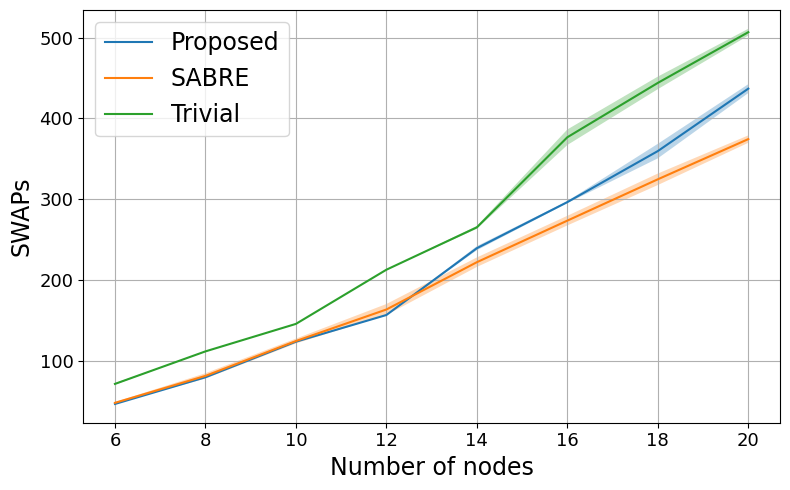

In [115]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [116]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='2D', use_custom=True, opt_level=3, reps=1, k=2, normalize_laplacian=True)

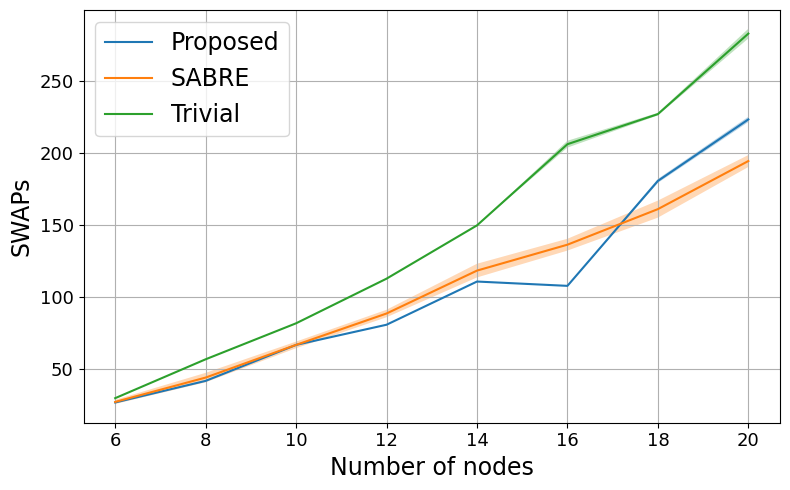

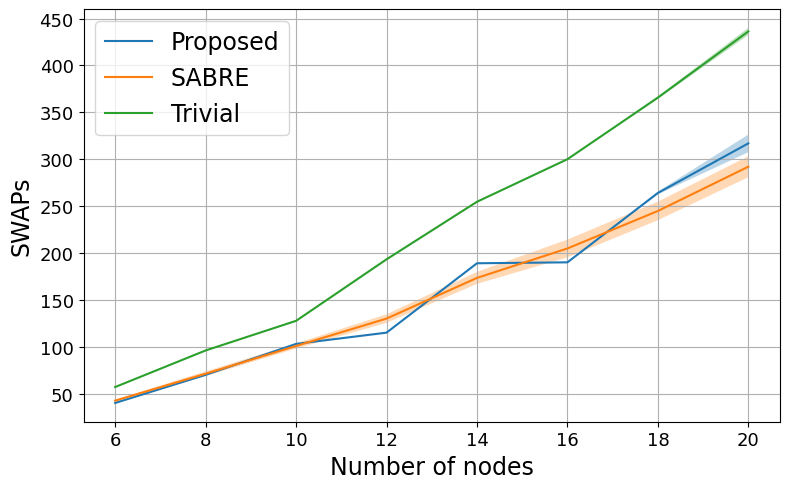

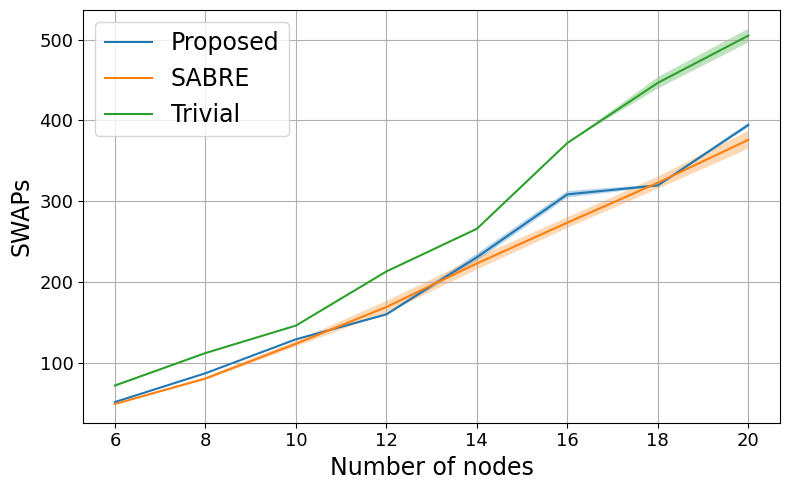

In [117]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [118]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='2D', use_custom=True, opt_level=3, reps=1, k=3, normalize_laplacian=True)

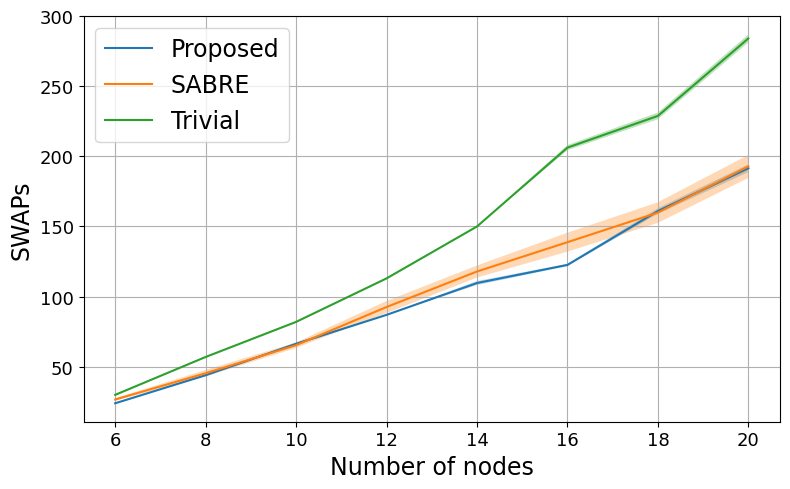

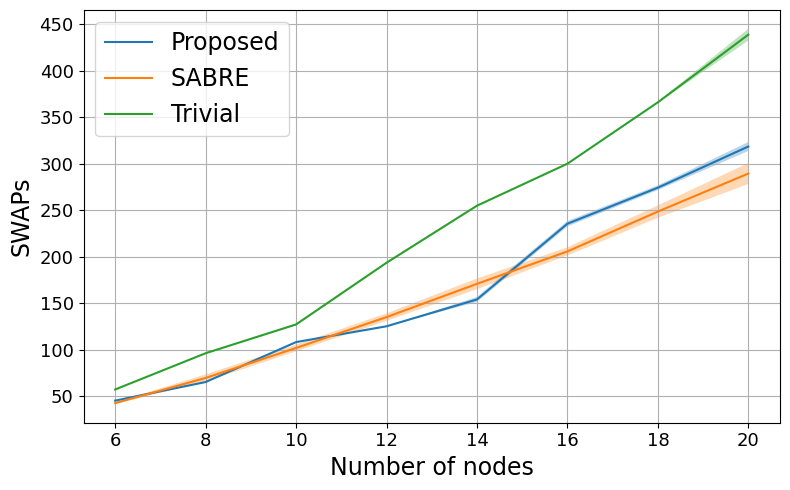

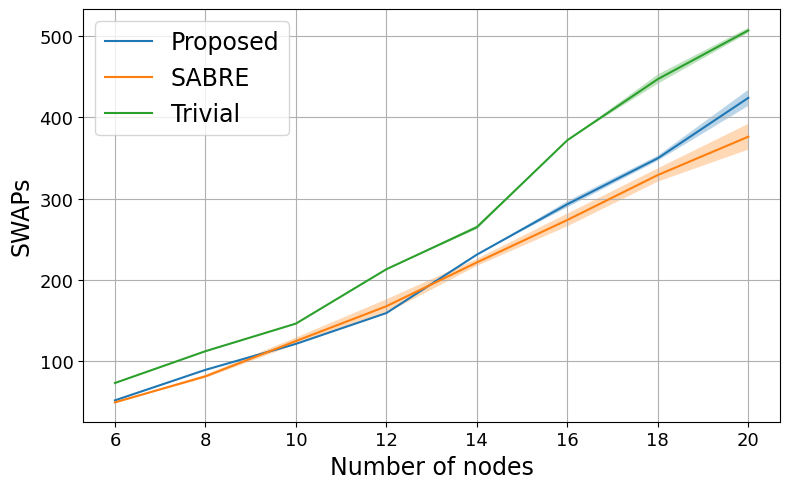

In [119]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [120]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 21, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='2D', use_custom=True, opt_level=3, reps=1, k=5, normalize_laplacian=True)

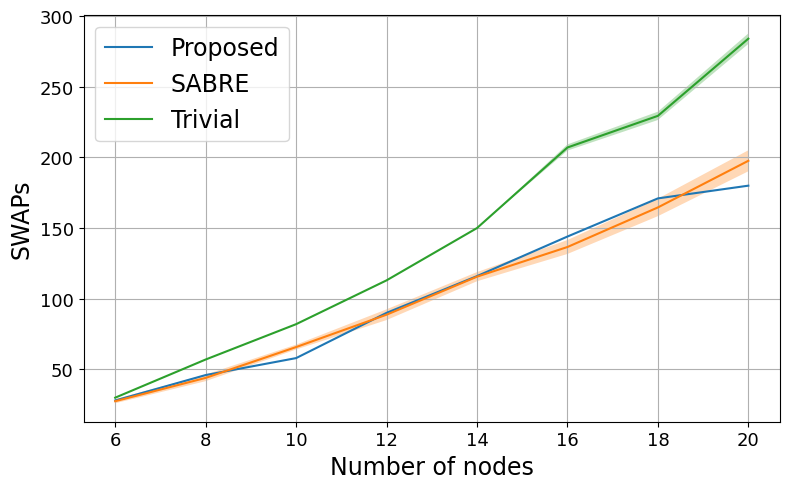

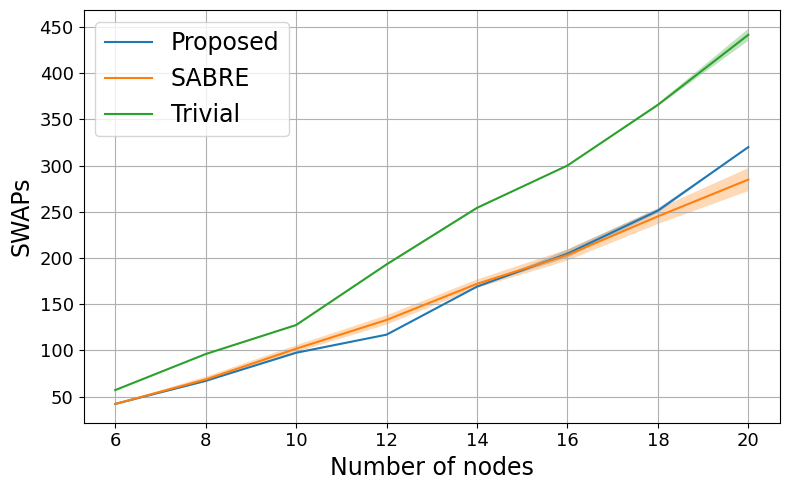

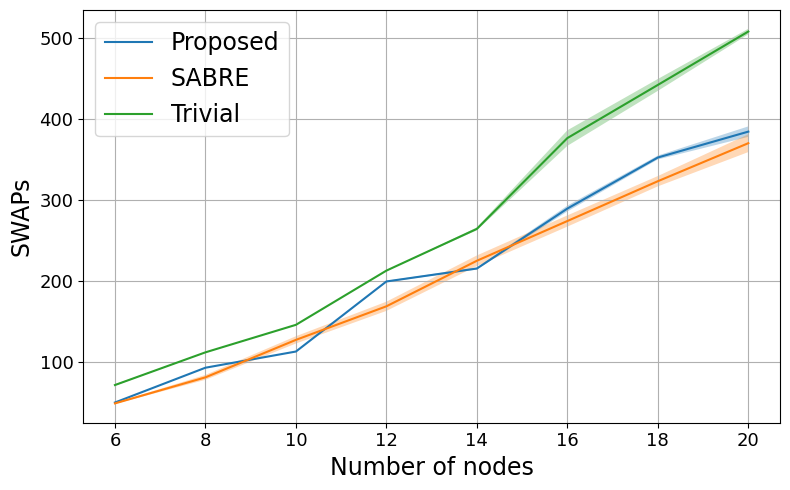

In [121]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# FakeFez

In [ ]:
backend = FakeFez()

## SWAP Counts

Fiedler Mapped

In [ ]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=10, node_list=nodes_reg, tech='1D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

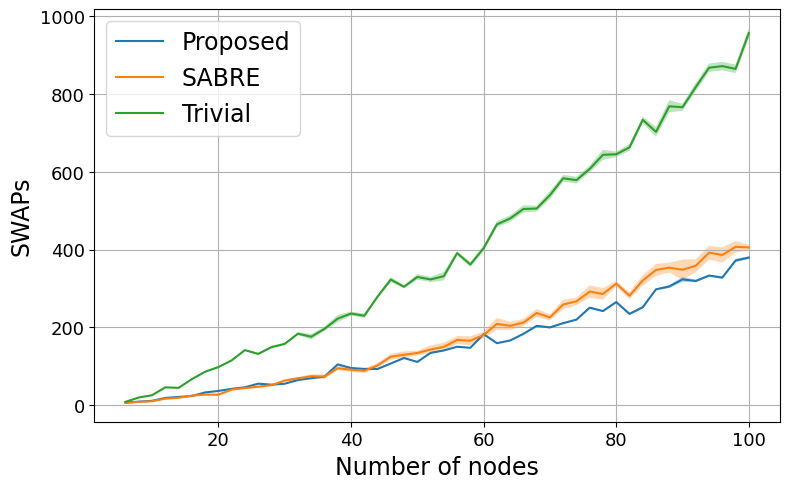

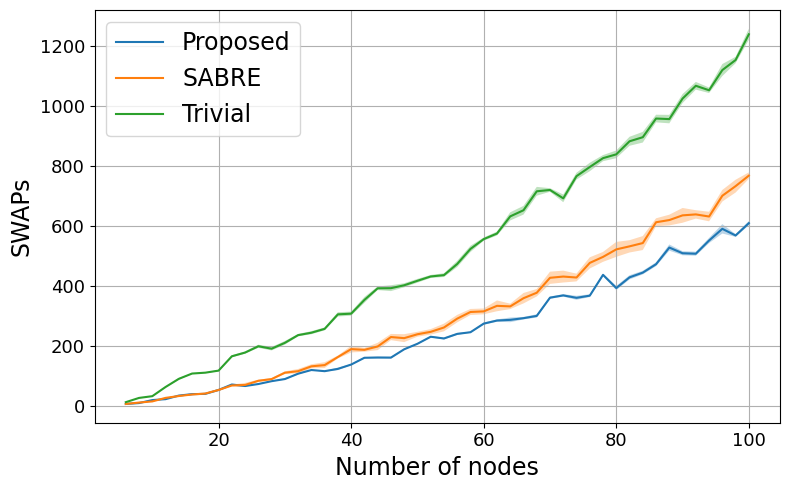

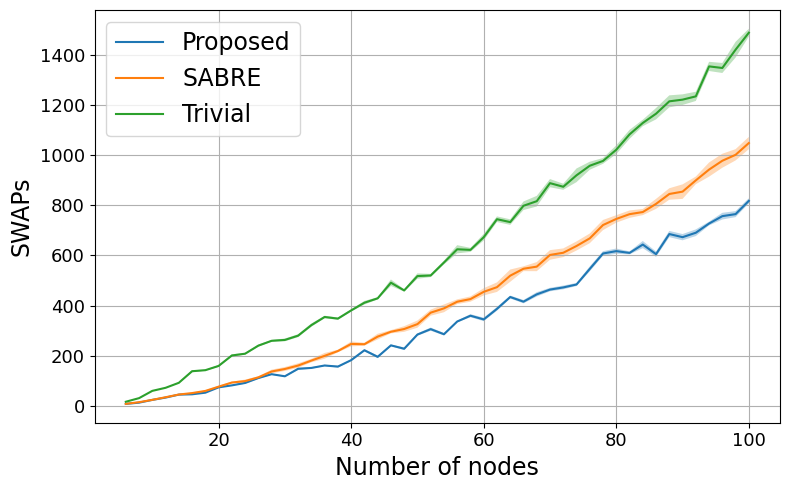

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [13]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

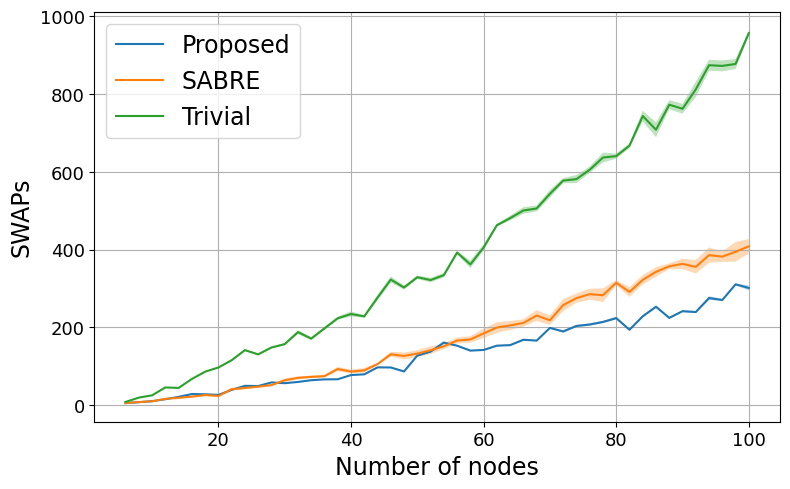

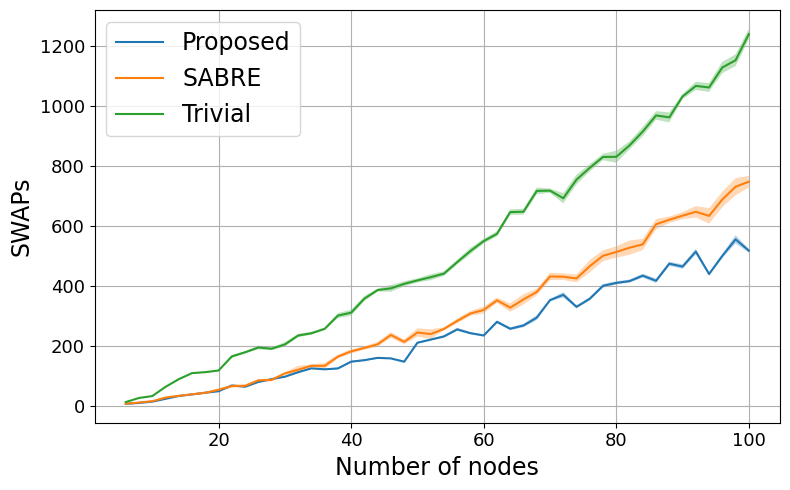

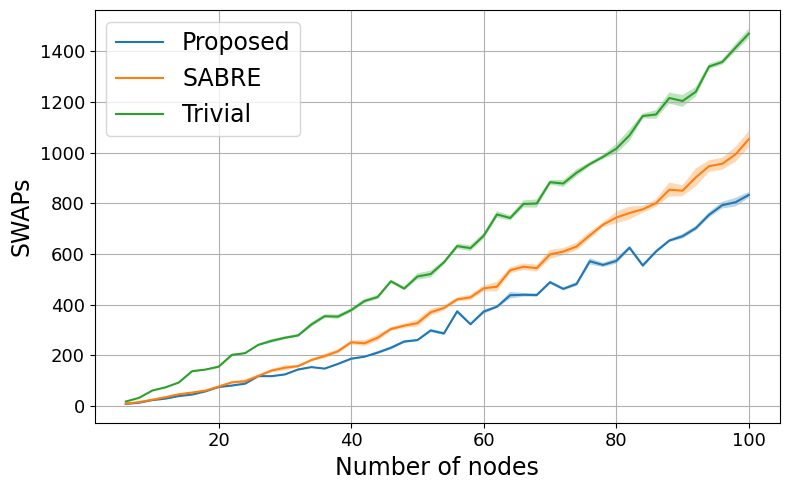

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [16]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

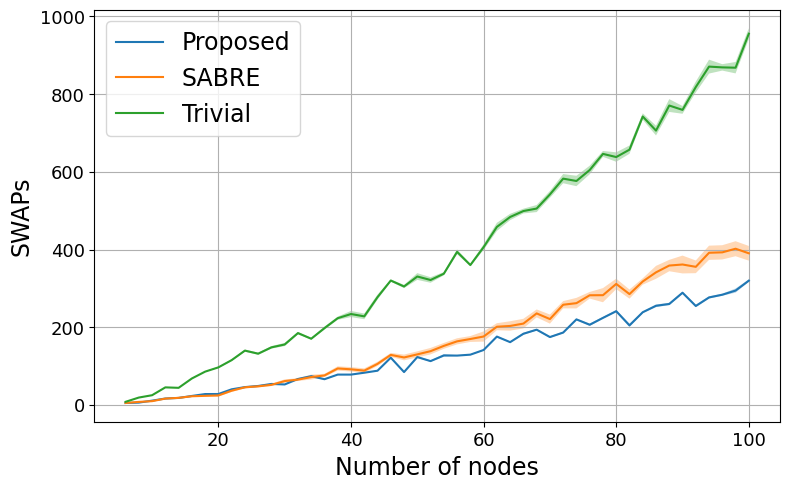

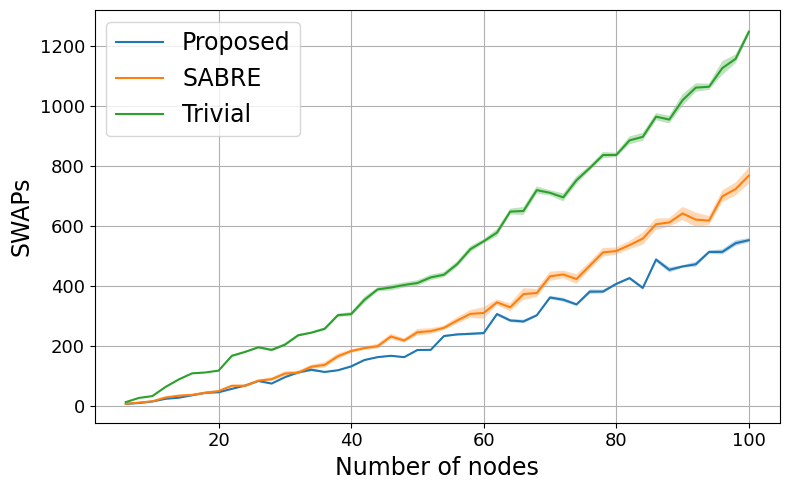

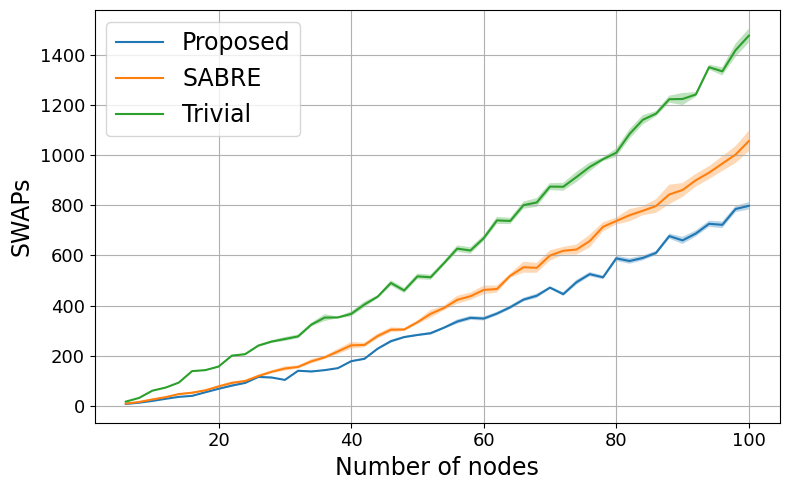

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [18]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

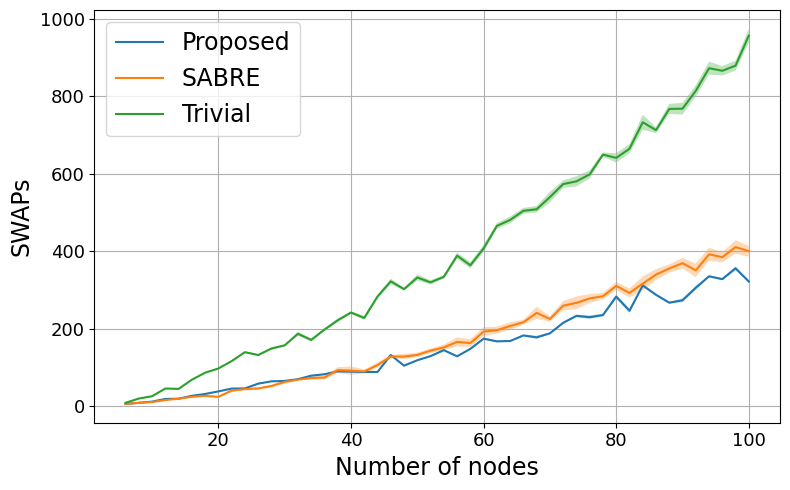

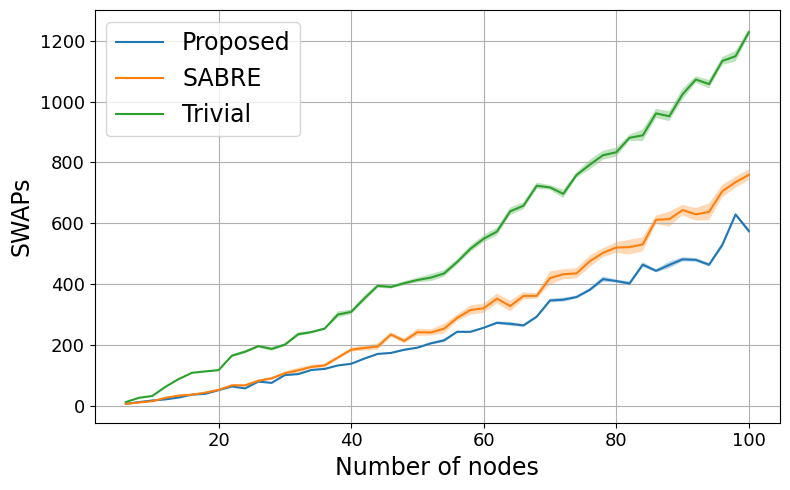

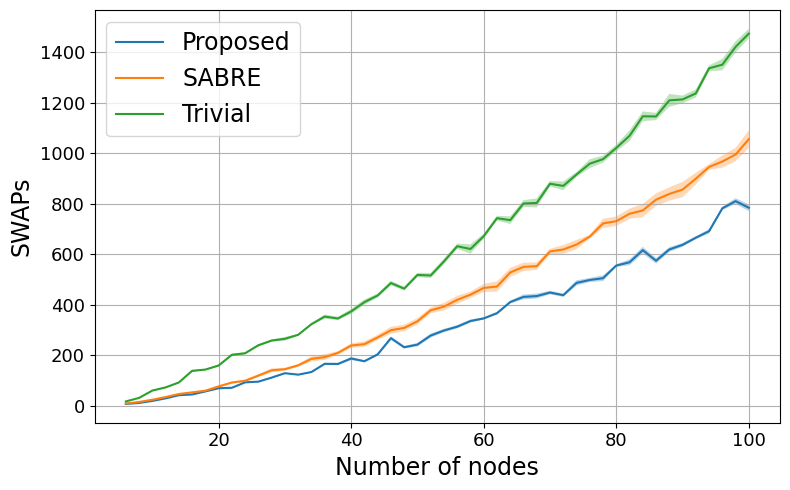

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

Fiedler Mapped

In [20]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='1D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

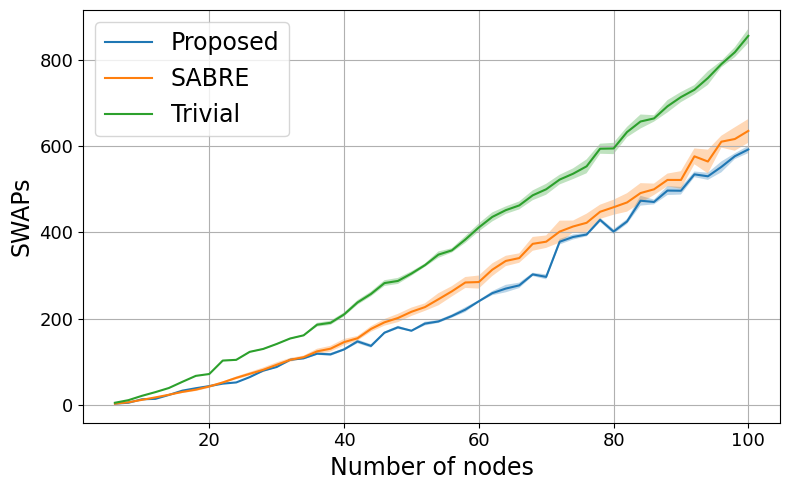

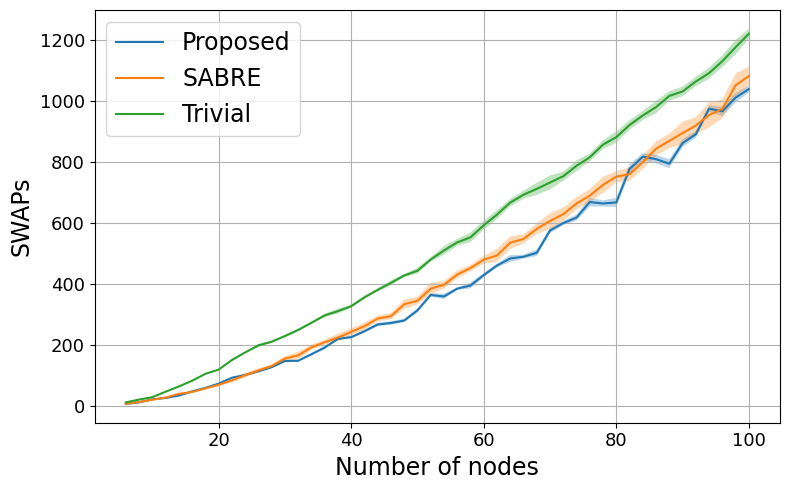

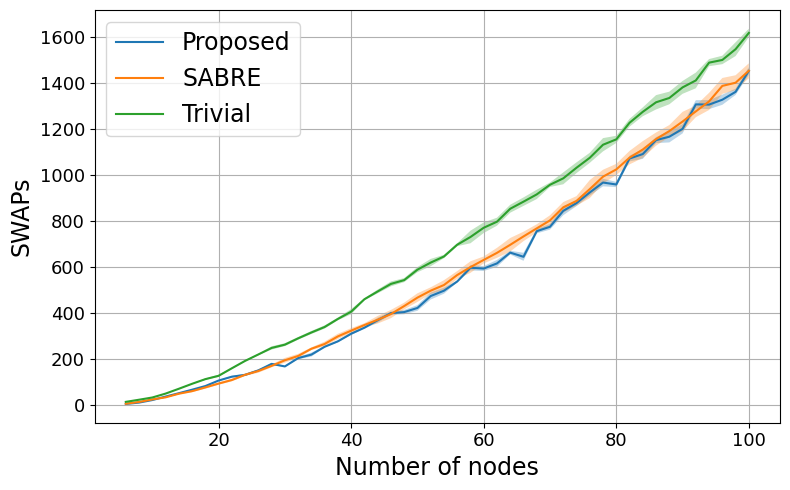

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [22]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=2, normalize_laplacian=True)

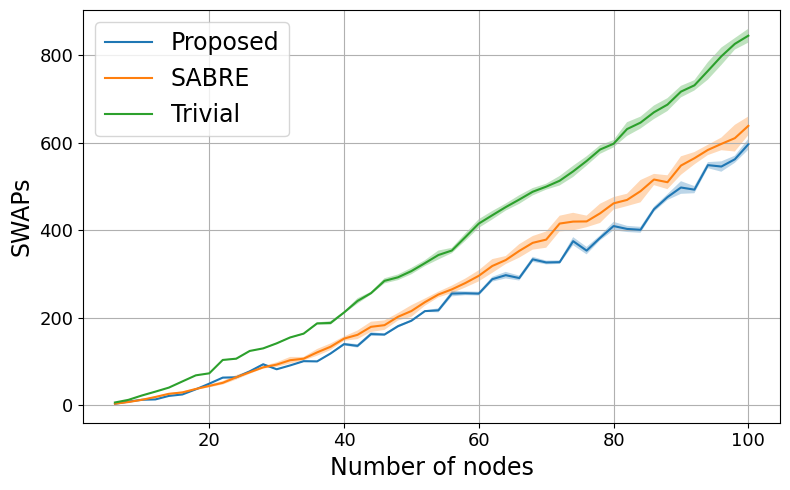

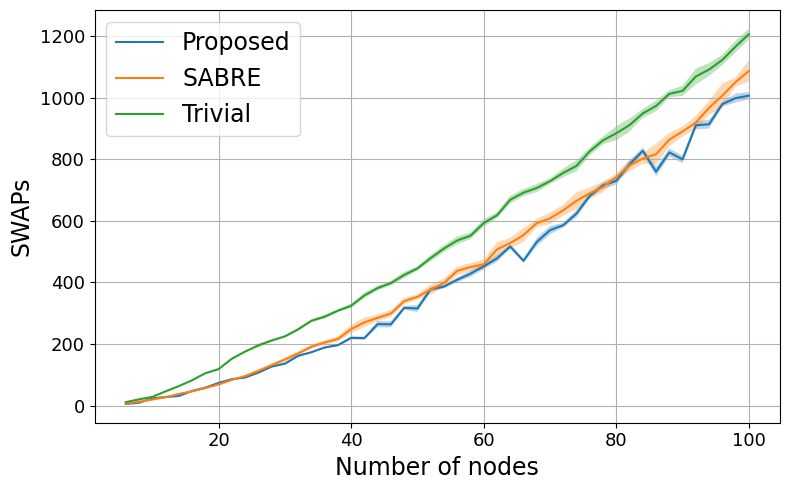

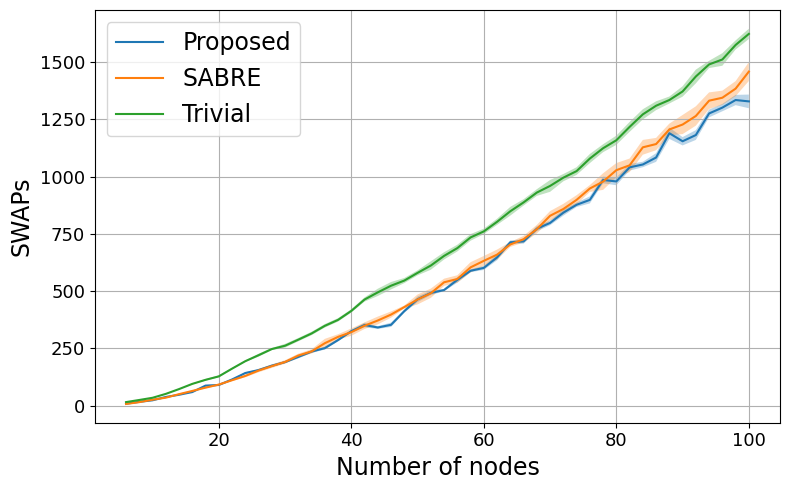

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [24]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=3, normalize_laplacian=True)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

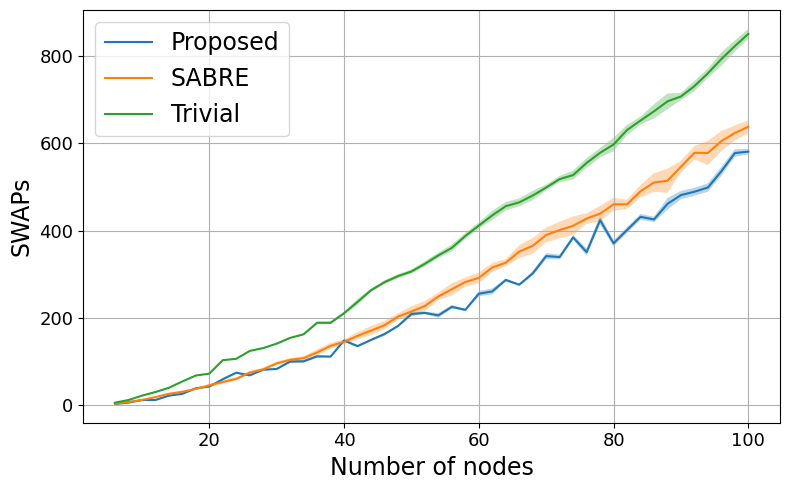

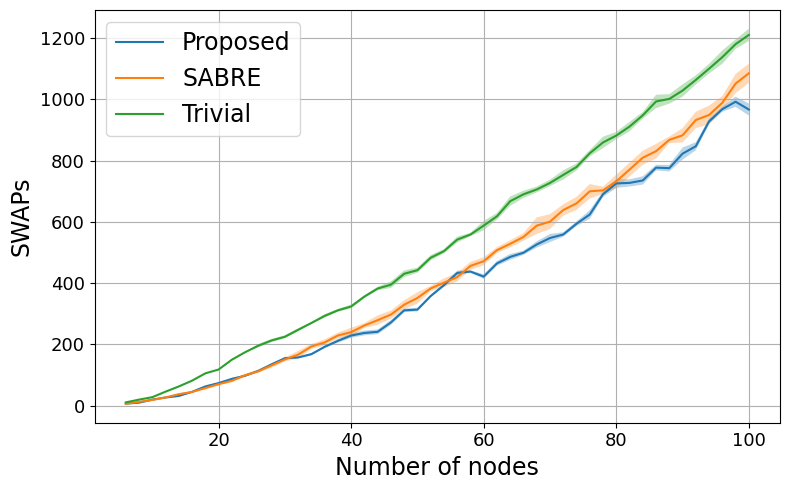

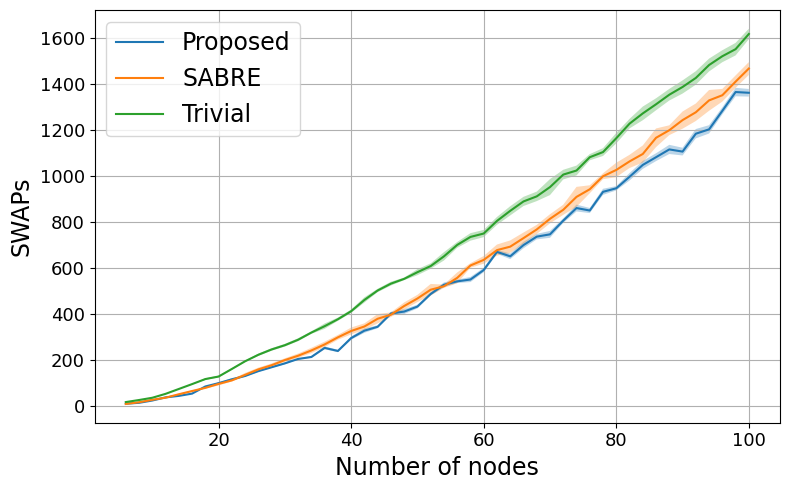

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [26]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=5, normalize_laplacian=True)

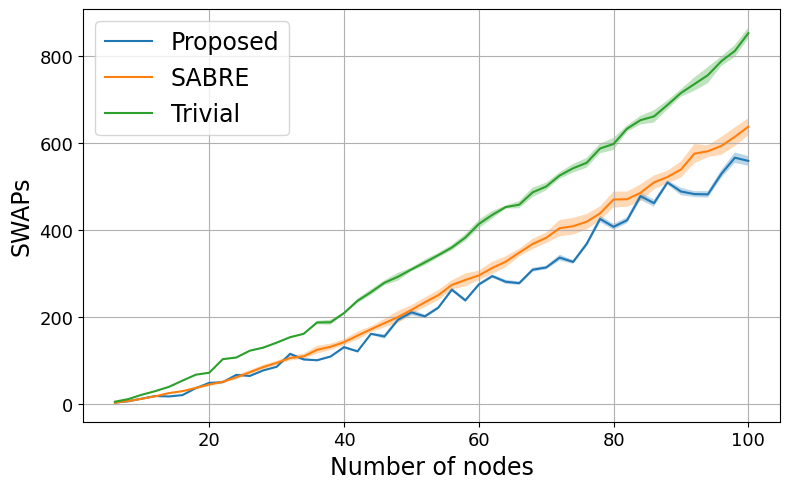

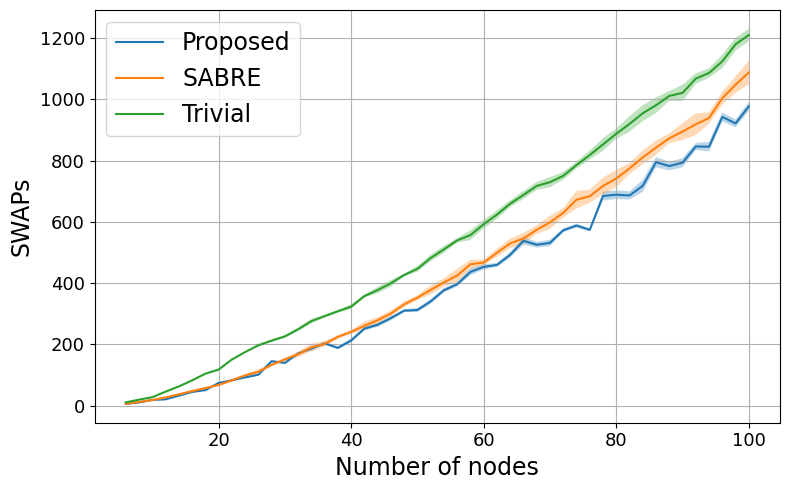

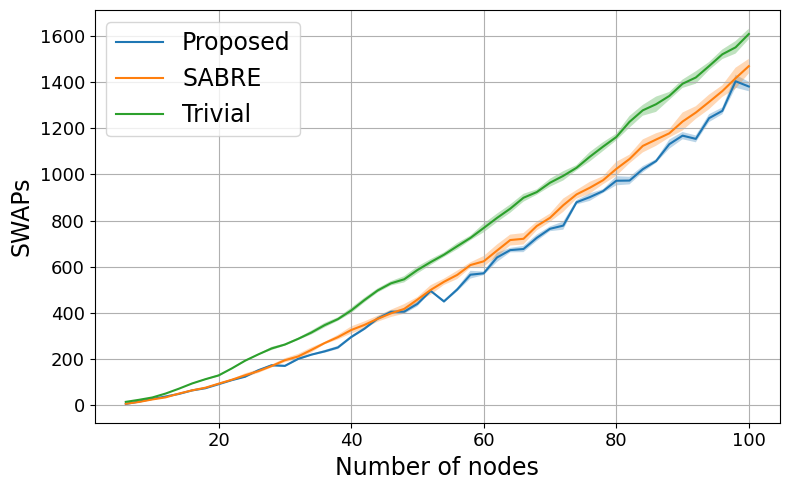

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Transpiled 2Q Gate counts

Fiedler Mapped

In [28]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=10, node_list=nodes_reg, tech='1D',
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

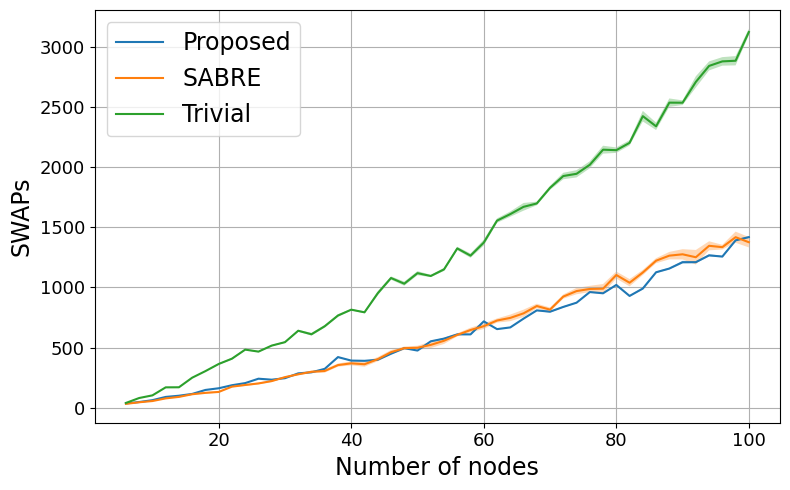

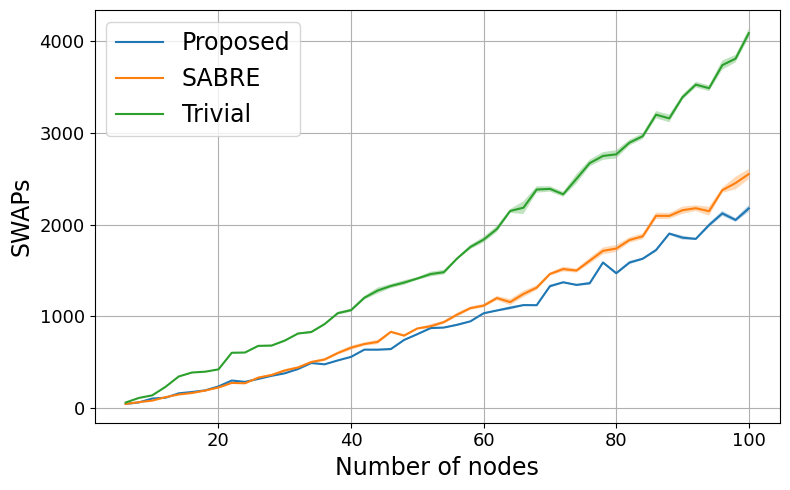

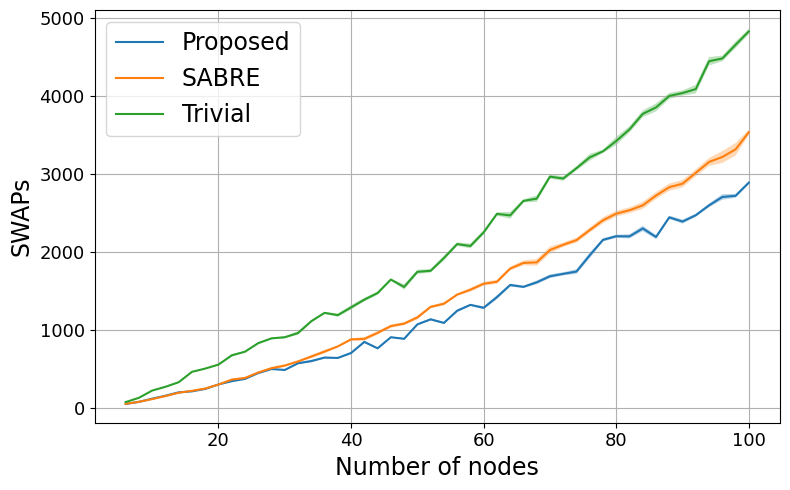

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


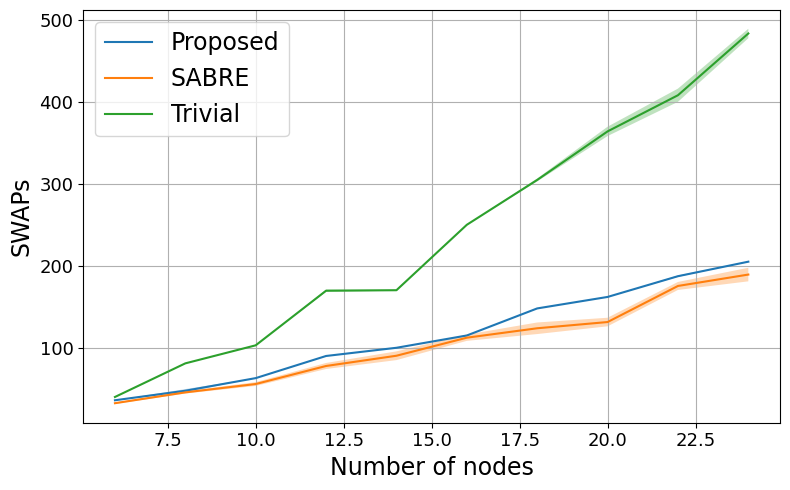

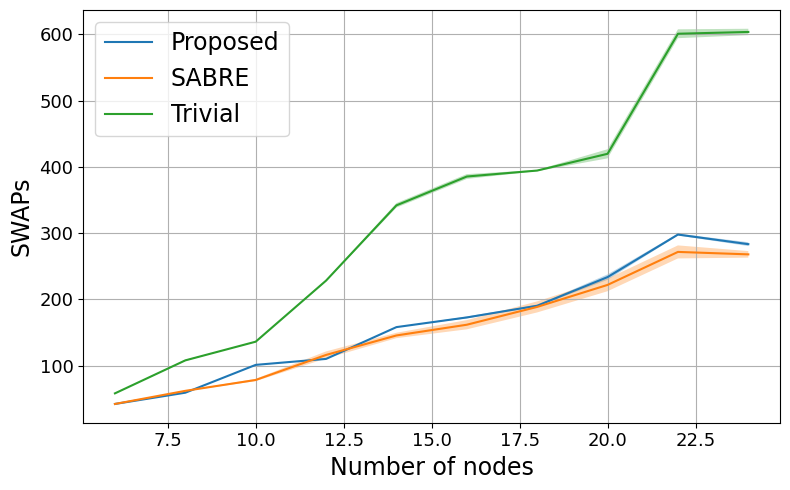

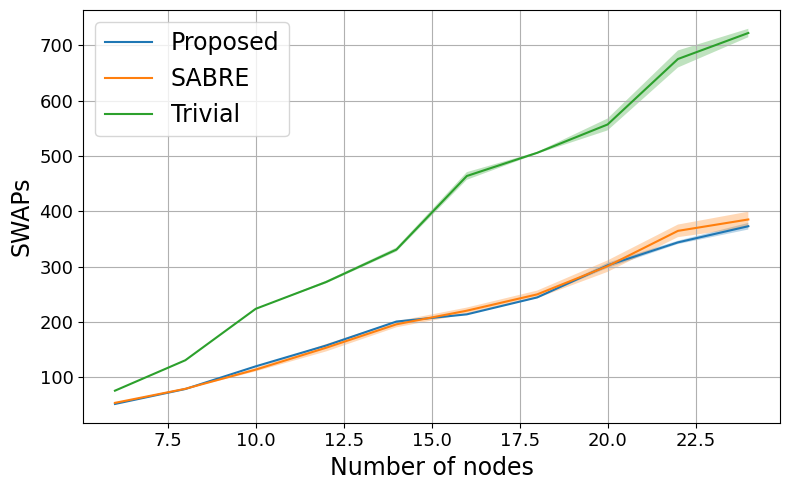

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method][:10])
        std = np.array(swaps_reg[param]['stddevs'][method][:10])
        plt.plot(nodes_reg[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_reg[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [31]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

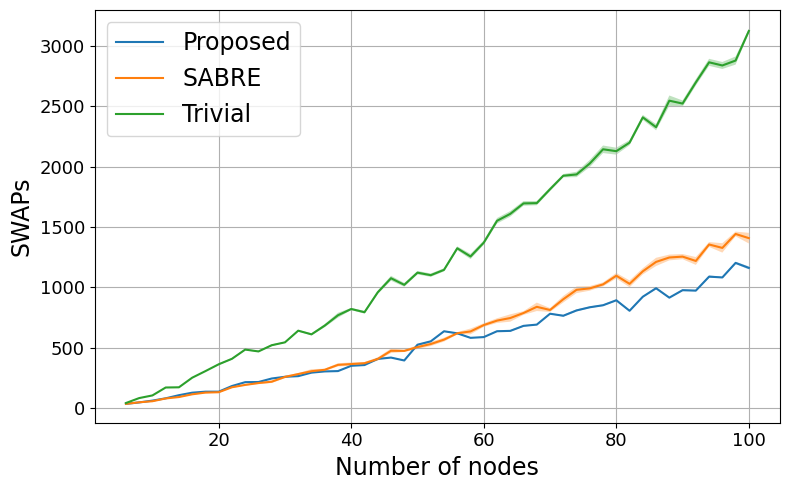

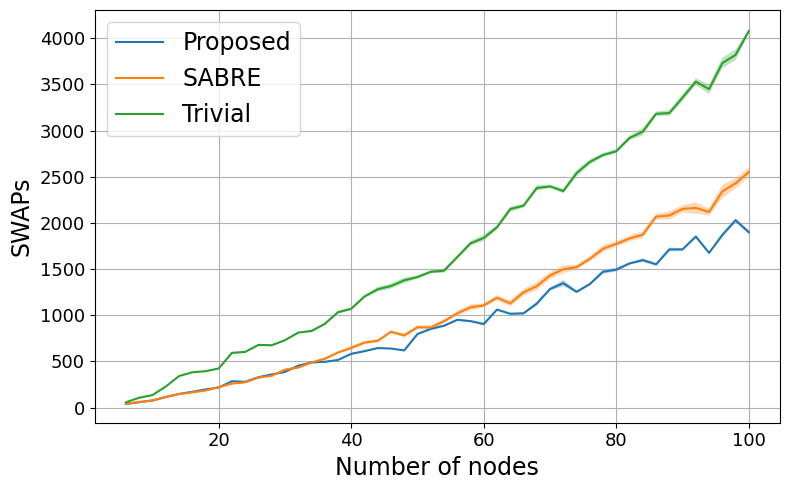

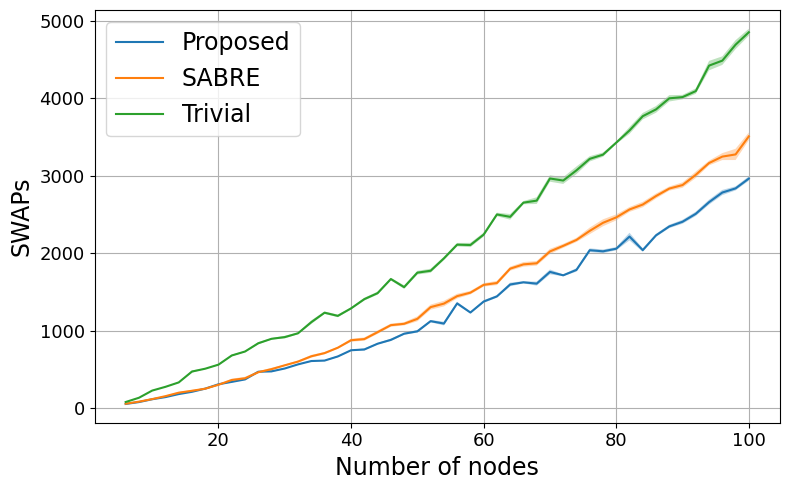

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


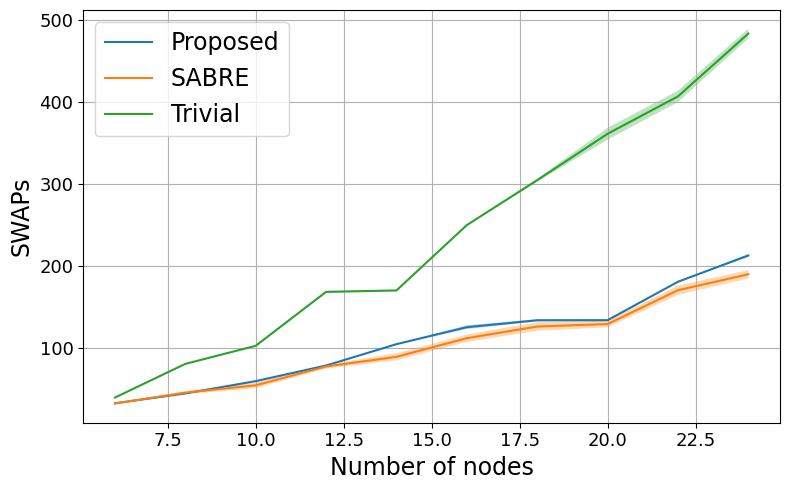

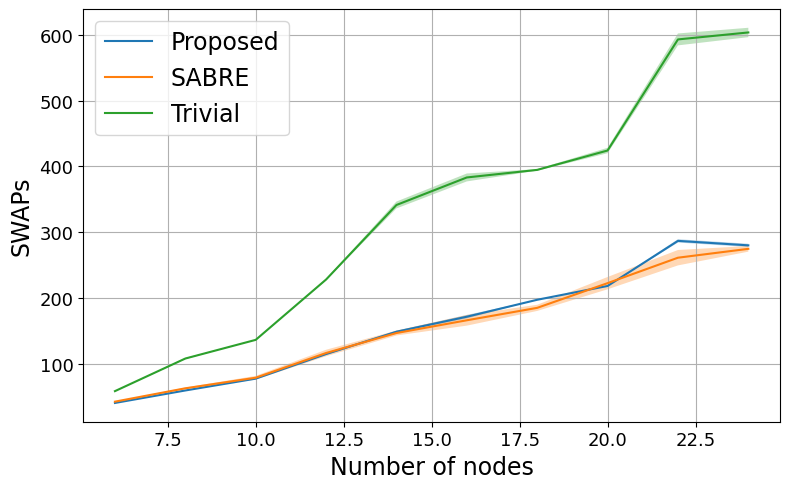

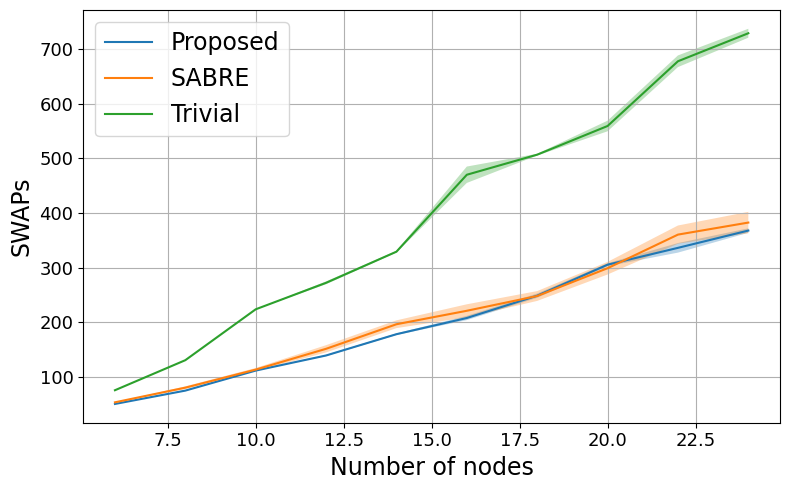

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method][:10])
        std = np.array(swaps_reg[param]['stddevs'][method][:10])
        plt.plot(nodes_reg[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_reg[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [34]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

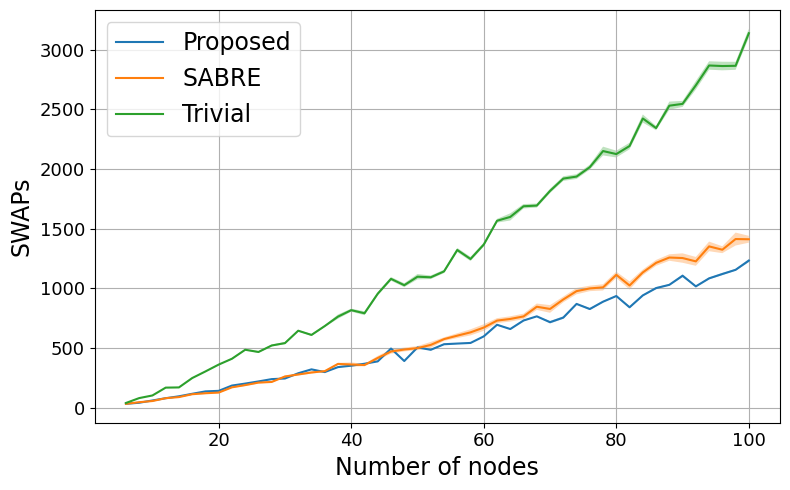

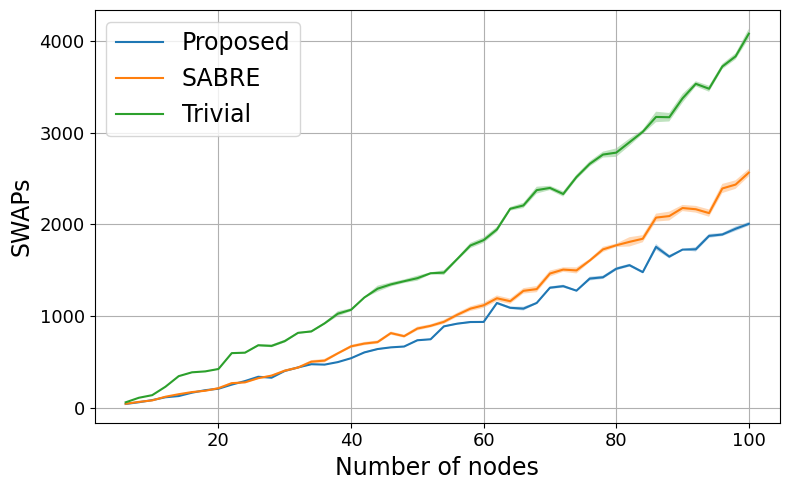

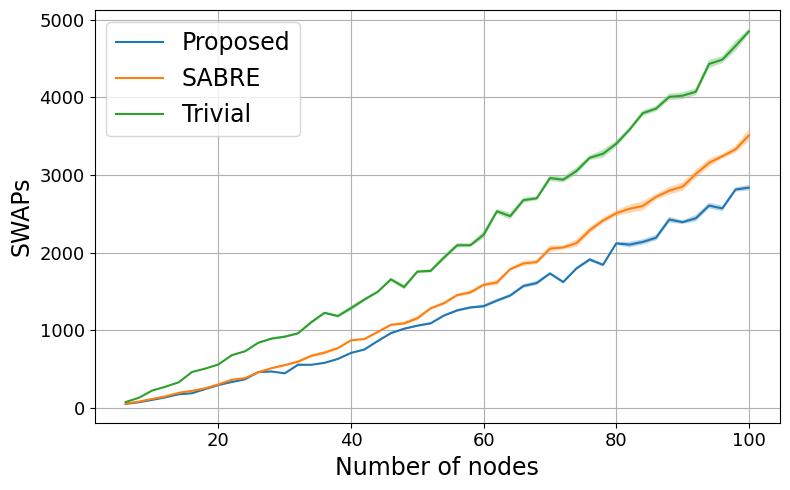

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


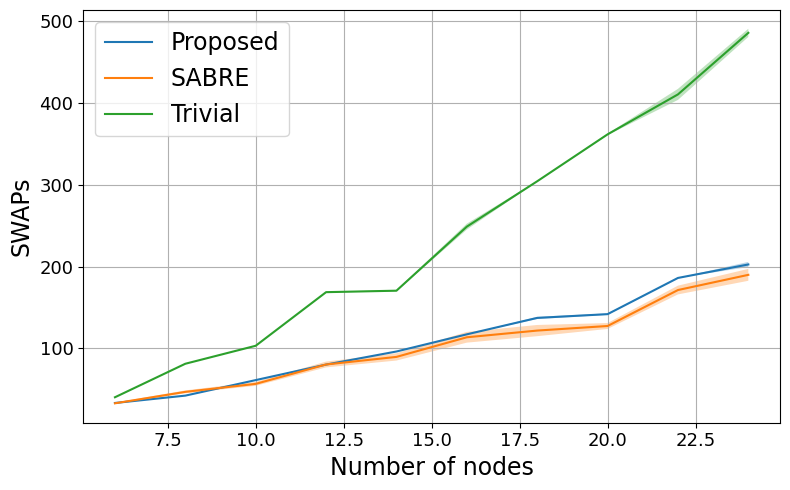

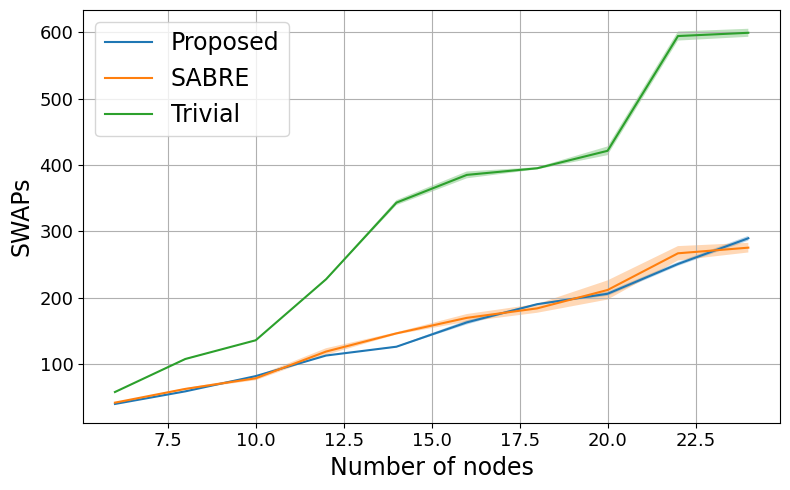

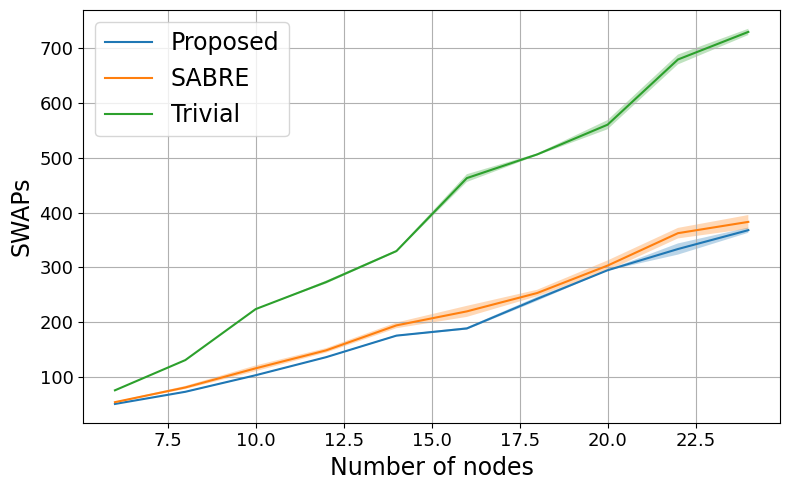

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method][:10])
        std = np.array(swaps_reg[param]['stddevs'][method][:10])
        plt.plot(nodes_reg[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_reg[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [37]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=10, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='cz', use_custom=True, opt_level=3, reps=1)

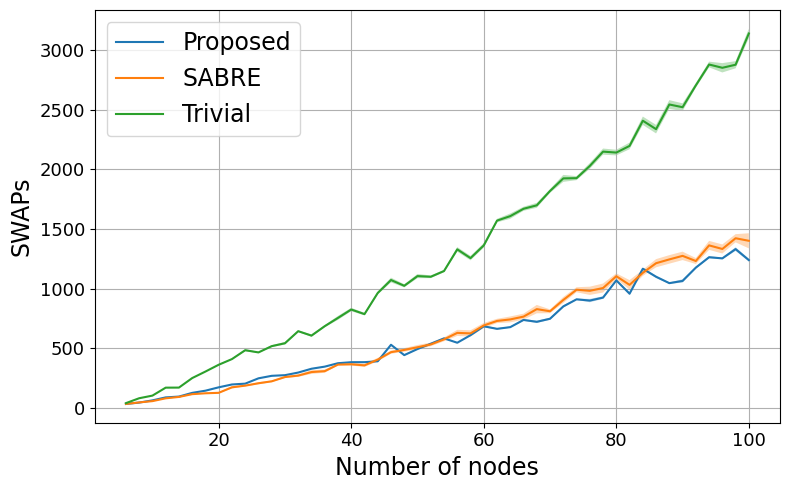

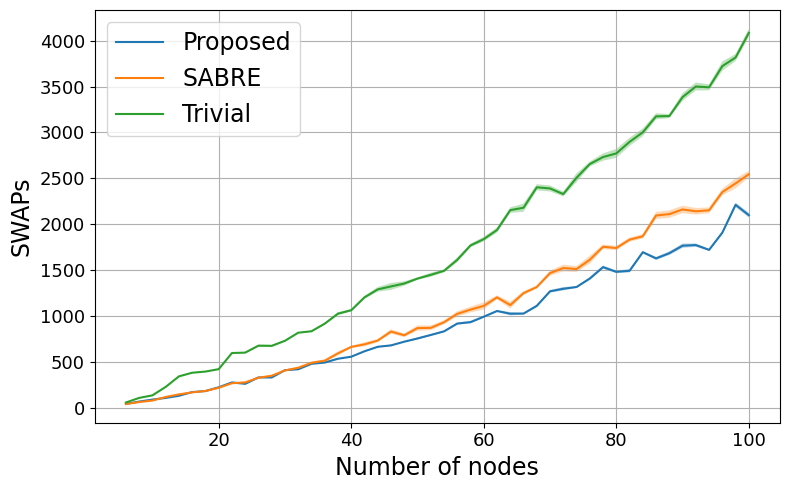

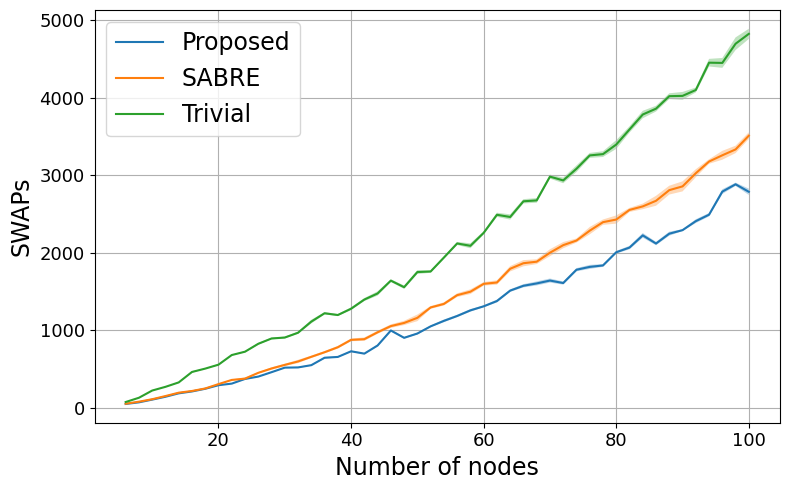

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


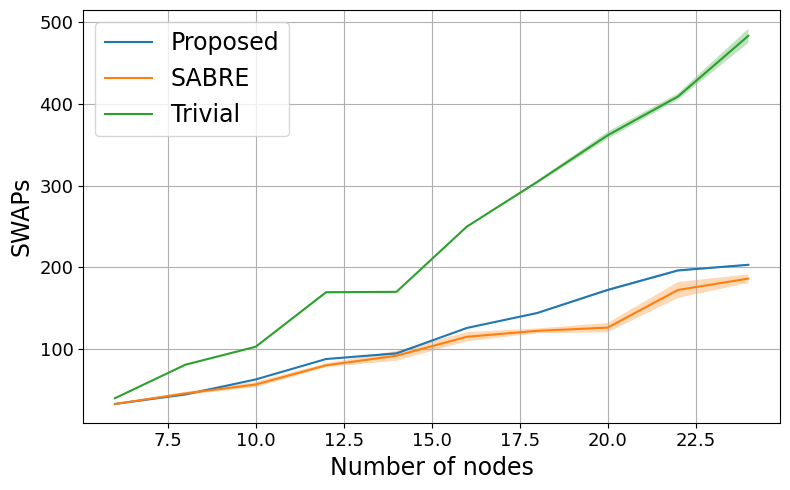

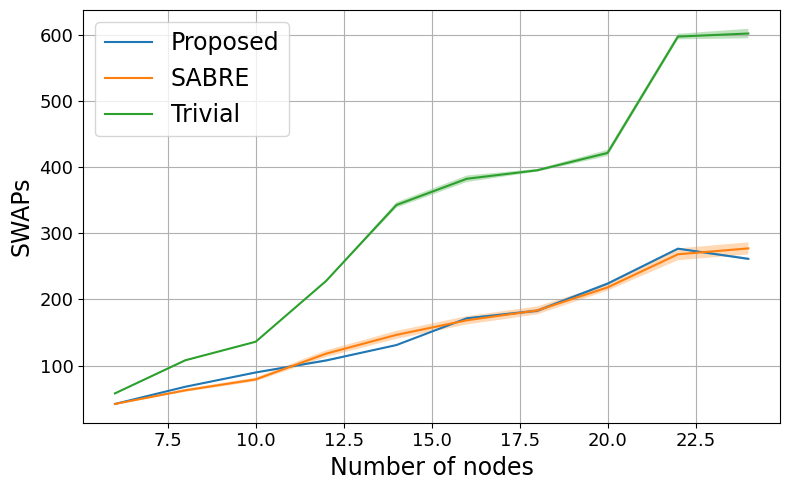

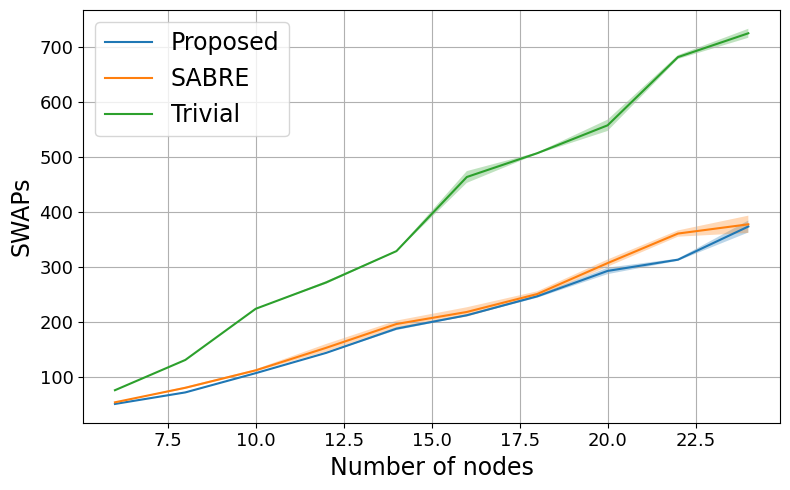

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method][:10])
        std = np.array(swaps_reg[param]['stddevs'][method][:10])
        plt.plot(nodes_reg[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_reg[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

Fiedler Mapped

In [40]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='1D', use_custom=True, opt_level=3, reps=1)

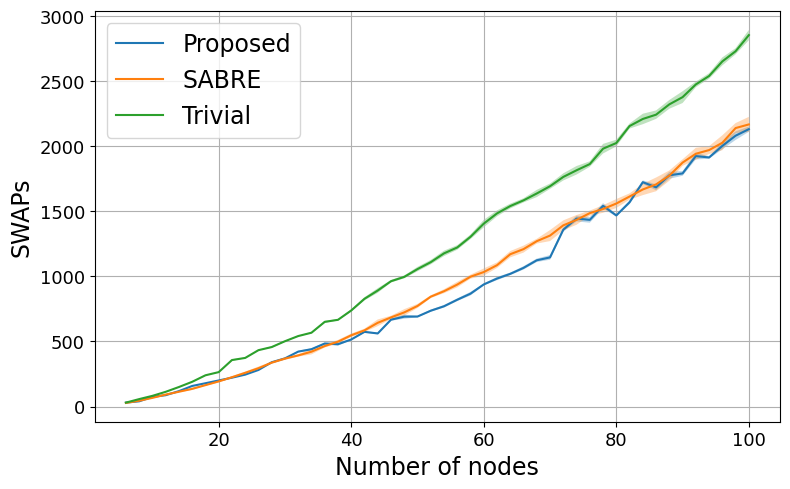

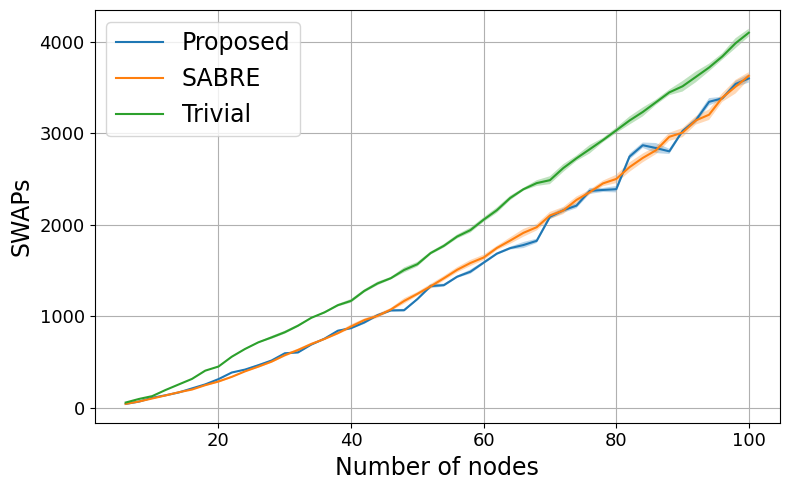

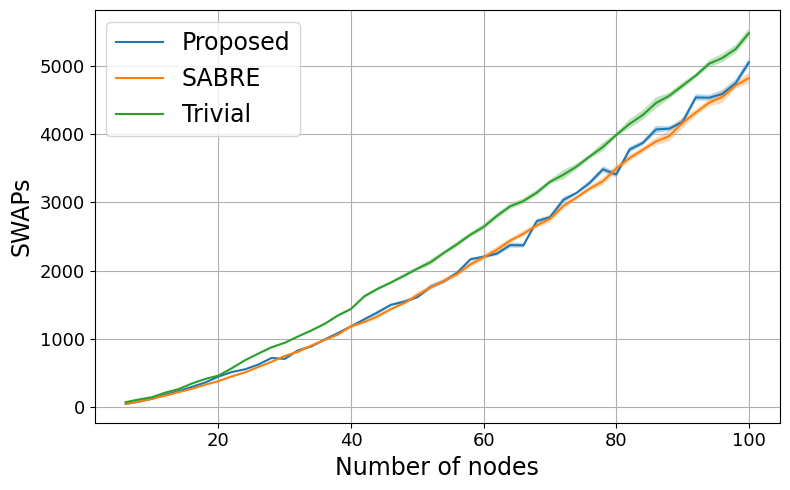

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


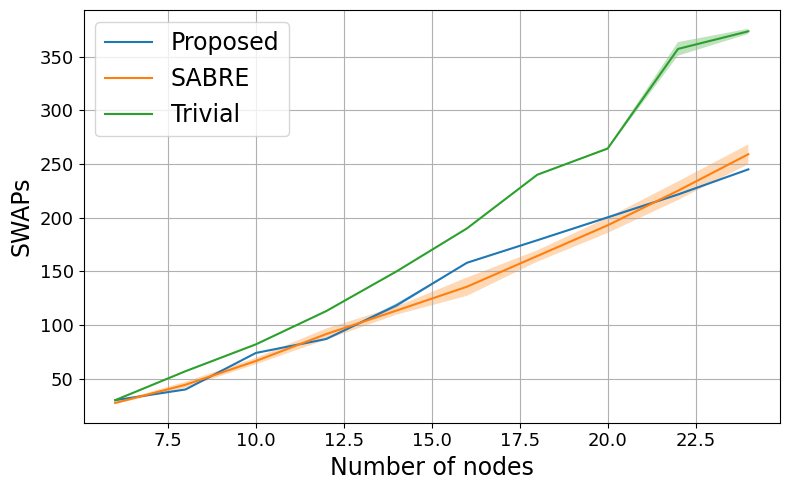

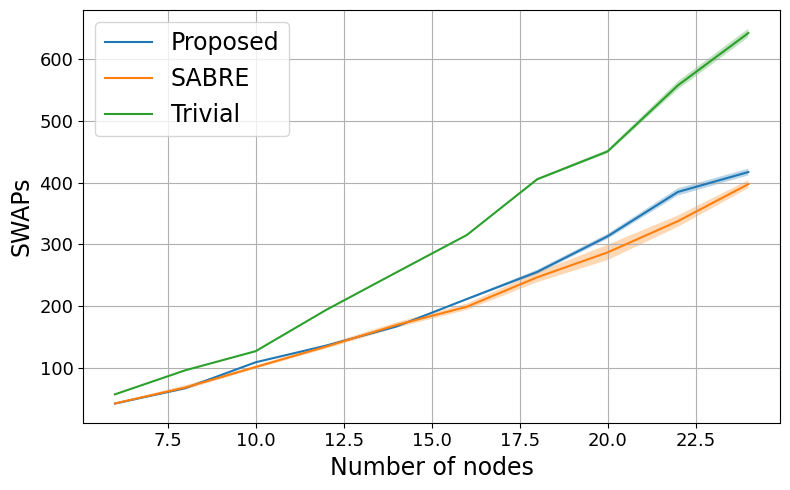

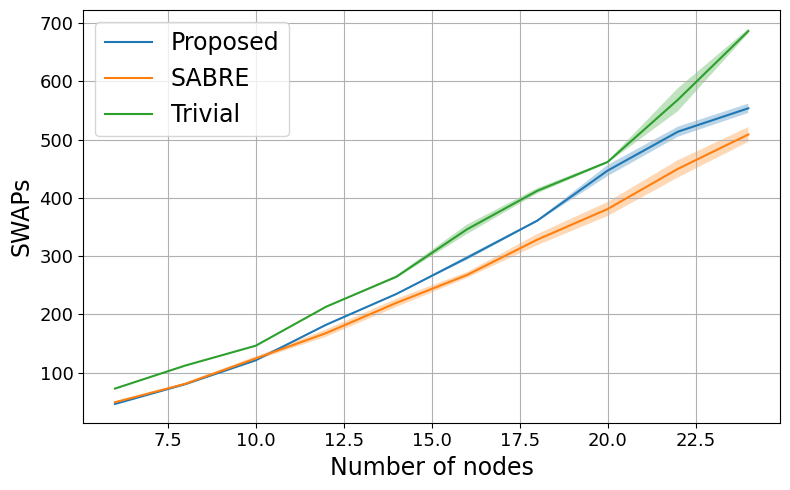

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method][:10])
        std = np.array(swaps_ba[param]['stddevs'][method][:10])
        plt.plot(nodes_ba[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_ba[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [43]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='2D', use_custom=True, opt_level=3, reps=1, k=2, normalize_laplacian=True)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

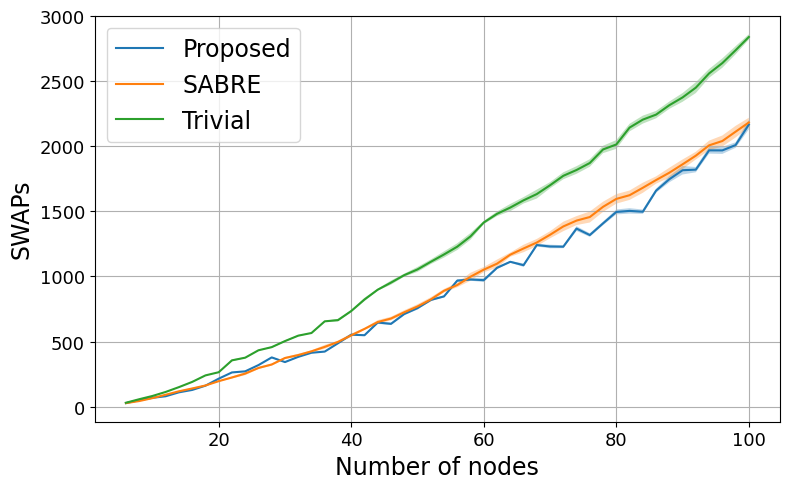

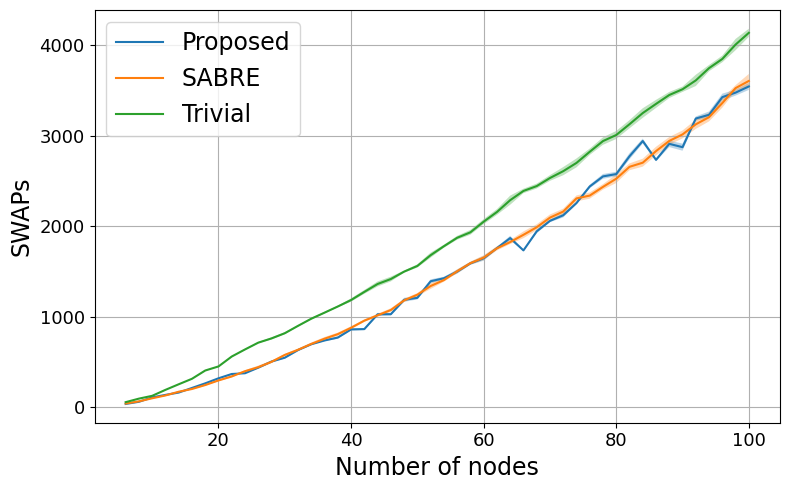

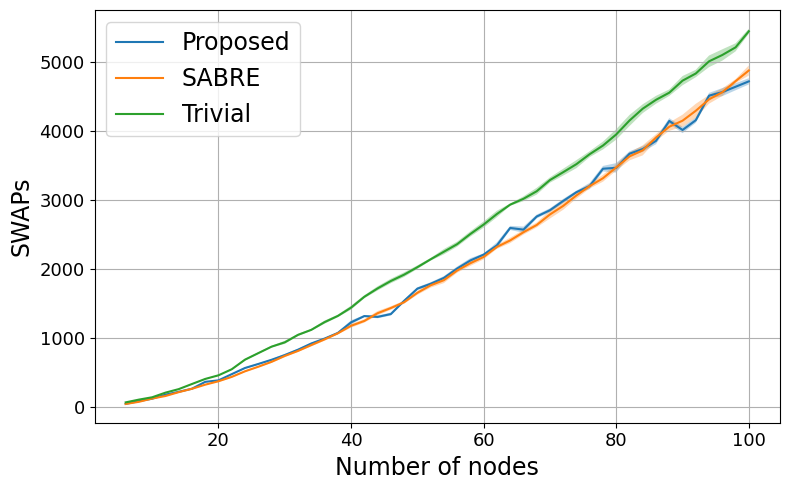

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


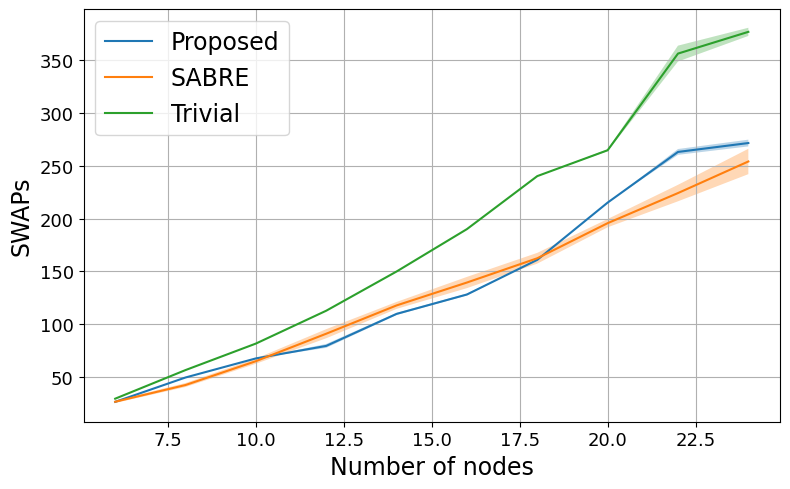

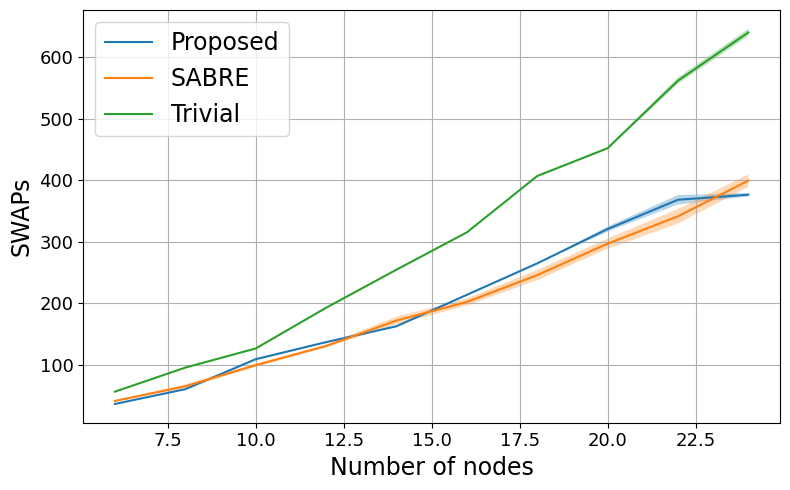

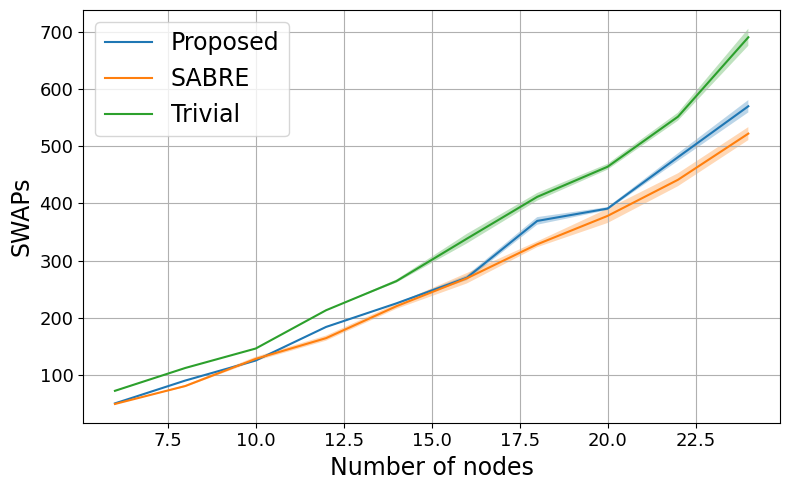

In [45]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method][:10])
        std = np.array(swaps_ba[param]['stddevs'][method][:10])
        plt.plot(nodes_ba[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_ba[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [46]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='2D', use_custom=True, opt_level=3, reps=1, k=3, normalize_laplacian=True)

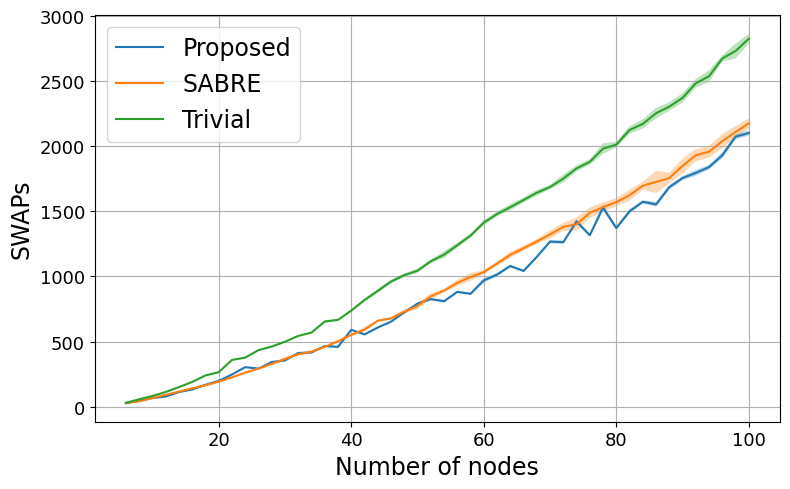

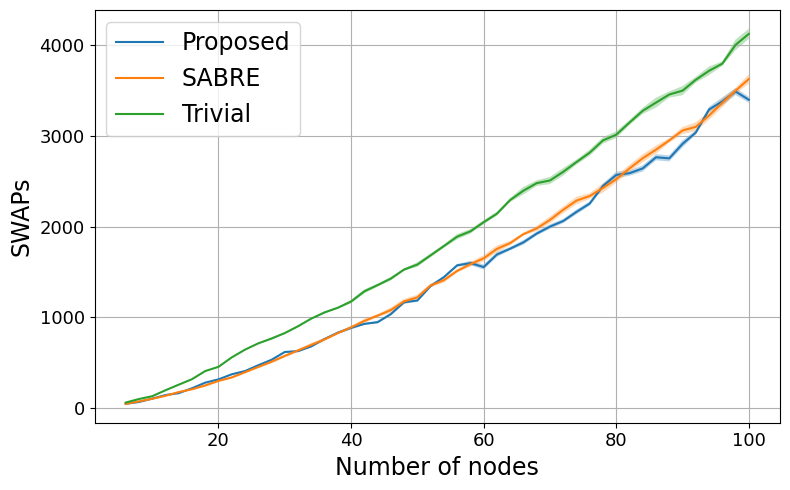

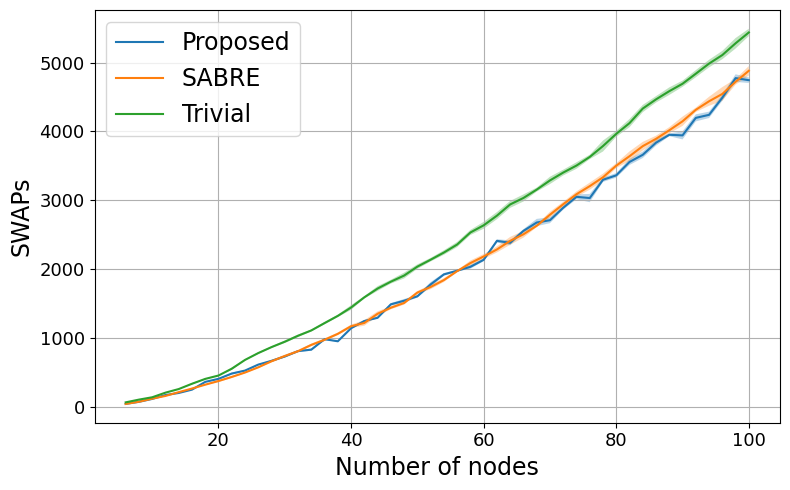

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


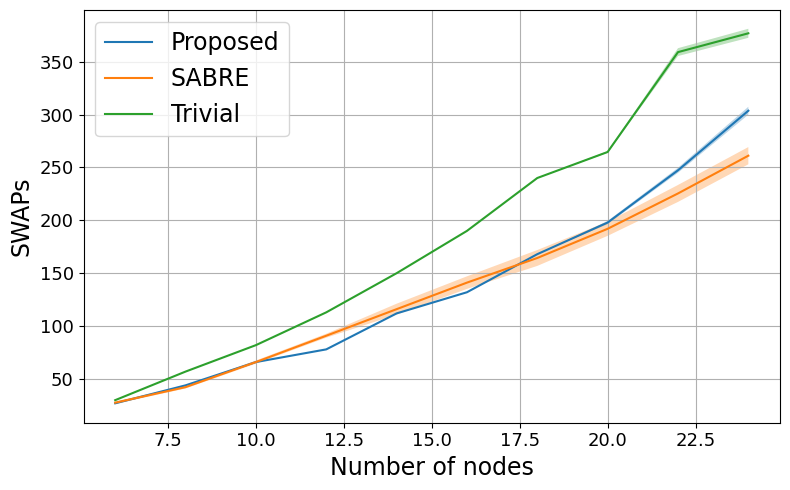

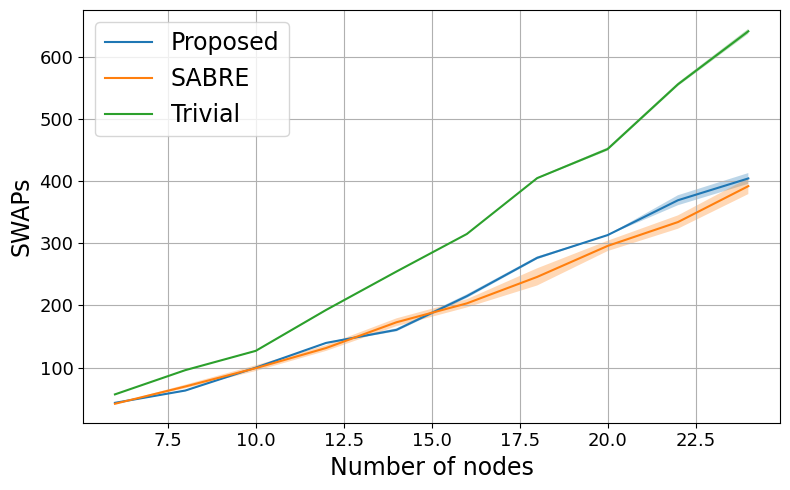

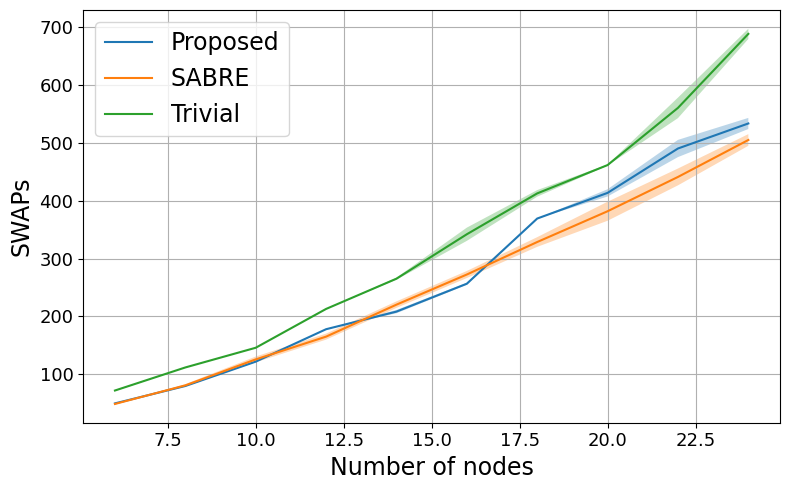

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method][:10])
        std = np.array(swaps_ba[param]['stddevs'][method][:10])
        plt.plot(nodes_ba[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_ba[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [49]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='cz', tech='2D', use_custom=True, opt_level=3, reps=1, k=5, normalize_laplacian=True)

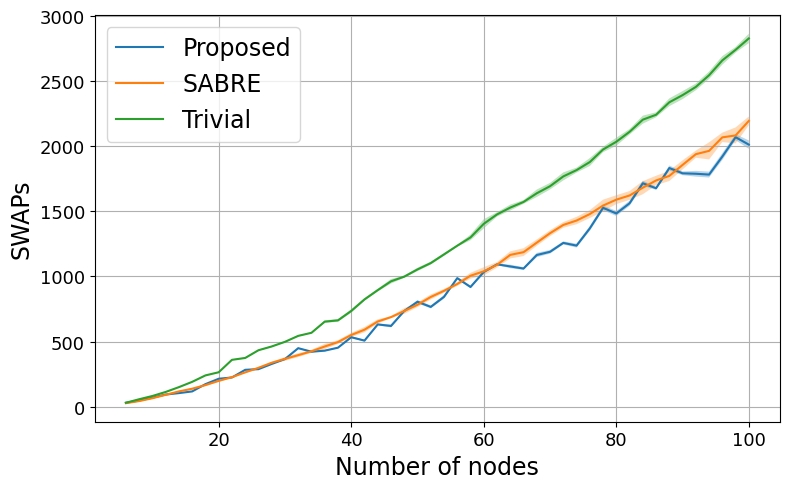

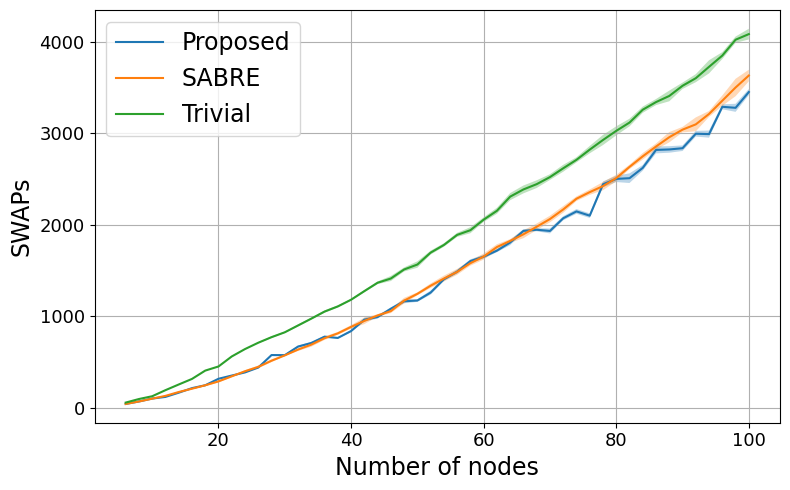

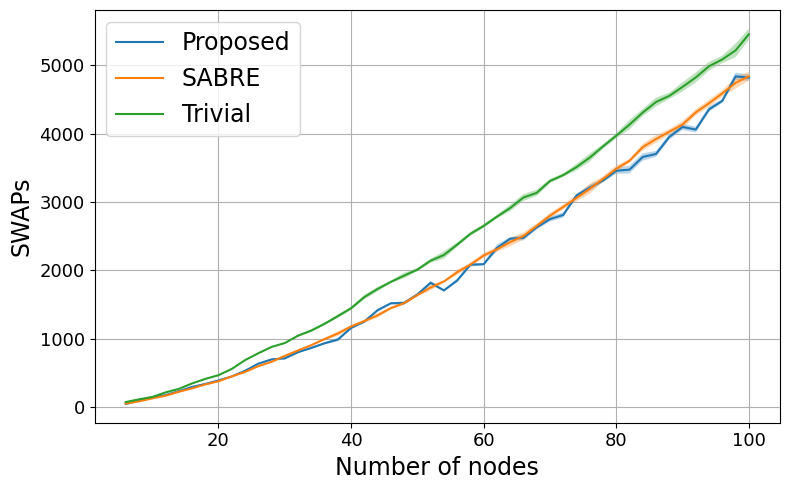

In [50]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


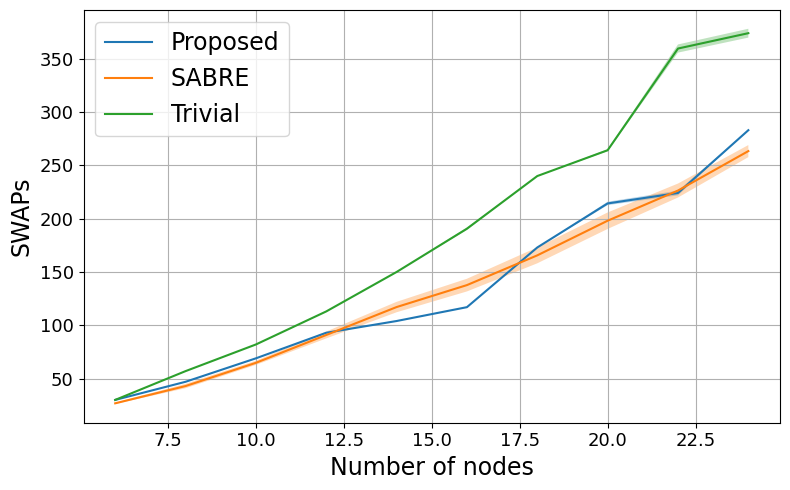

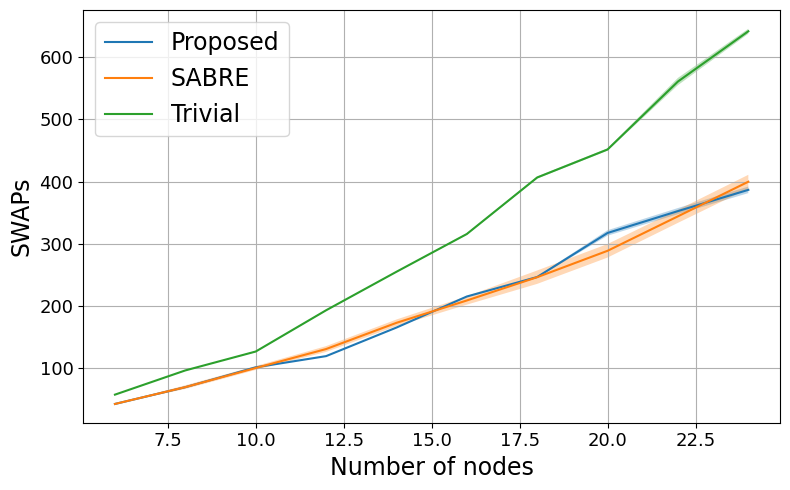

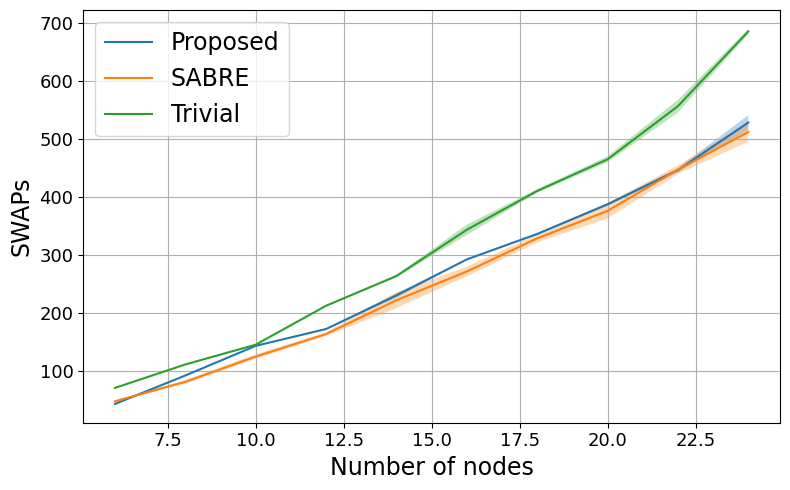

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method][:10])
        std = np.array(swaps_ba[param]['stddevs'][method][:10])
        plt.plot(nodes_ba[:10], mean, label=method)  # line for mean
        plt.fill_between(nodes_ba[:10], mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Simulator

In [142]:

def QAOA_max_cut(candidate_circuit:QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, estimator_shots=1000, sampler_shots=1000):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = estimator_shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
    optimized_circuit = candidate_circuit.assign_parameters(result.x)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = sampler_shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin
    # keys = list(final_distribution_bin.keys())
    # values = list(final_distribution_bin.values())
    # most_likely = keys[np.argmax(np.abs(values))]

    # return most_likely[::-1]

def optimized_parameters(candidate_circuit: QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, shots=100):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
        return result.x
    
def sample_distribution(candidate_circuit:QuantumCircuit, optimized_params, backend, shots=1000):
    optimized_circuit = candidate_circuit.assign_parameters(optimized_params)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    return job.job_id()

def dist_from_job_id(job_id, backend):
    job = backend.retrieve_job(job_id)
    result = job.result()
    counts = result[0].data.meas.get_counts()
    total = sum(counts.values())
    return {k: v / total for k, v in counts.items()}

def evaluate_cut(graph: nx.Graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v in list(graph.edges()):
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += 1
    return cut_value

def maxcut_dict(graph, cut_dict):
    mc_dict = defaultdict(int)
    for bitstr, prob in cut_dict.items():
        mc_dict[evaluate_cut(graph, bitstr[::-1])] += prob
    return mc_dict

In [143]:
def maxcut_dist(sim, backend, num_nodes, graph_type='reg', param=4, reps=1, opt_level=3, estimator_shots=1000, sampler_shots=1000, root_on_backend=None, normalize_laplacian=True, tech='1D', k=2, noise_aware=False, default=False, gate='cz'):
    if graph_type=='reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    hamiltonian = get_hamiltonian(graph)

    if default:
        opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=reps), backend, initial_mapping=None, opt_level=opt_level)
        print('Default=> ', gate,': ', opt_gen.count_ops().get(gate, 0), 'Depth: ',opt_gen.depth())
        return QAOA_max_cut(opt_gen, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)
    else:
        if tech=='1D':
                tree = dfs_spanning_tree(graph, root=0)
                proposed_mapping = initial_layout(tree, backend=backend, how='fiedler', noise_aware=noise_aware)
        elif tech=='2D':
                logical_embedding = graph_laplacian_embedding(graph, k=k, normalized=normalize_laplacian)

                if noise_aware:
                    H = get_coupling_graph(backend, weighted=True)
                    S = selective_bfs(H, source=H.number_of_nodes()//2, n=num_nodes)
                else:
                    H = get_coupling_graph(backend)
                    S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=num_nodes)
                physical_embedding = graph_laplacian_embedding(S, k=k)
                proposed_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))

        # Distribution with Proposed Initial Mapping
        prop = custom_qaoa_ansatz(graph, proposed_mapping, backend.coupling_map, reps=reps)
        opt_prop = final_optimized_circuit(prop, backend, proposed_mapping, opt_level=opt_level)

        print('Prop=> ', gate,': ', opt_prop.count_ops().get(gate, 0), 'Depth: ',opt_prop.depth())
        
        return QAOA_max_cut(opt_prop, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)  
    # mc_dist_prop = maxcut_dict(graph, prop_dist)
    # mc_dist_gen = maxcut_dict(graph, gen_dist)

    # return mc_dist_prop, mc_dist_gen, maxcut_dist_over_all_possible(graph)

def most_likely_cut(dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    most_likely = keys[np.argmax(np.abs(values))]

    return most_likely[::-1]

def expected_size(graph, dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    sumValue = 0.0
    
    for key in keys:
        sumValue += dist[key] * evaluate_cut(graph, key[::-1]) # qiskit circuit measurements are returned in little-endian format, so we have to reverse the bitstrings

    return sumValue

def random_size(graph, dist: dict):
    keys = list(dist.keys())
    numKey = float(len(keys))
    sumValue = 0.0
    
    for key in keys:
        sumValue += evaluate_cut(graph, key[::-1]) / numKey

    return sumValue

import matplotlib.pyplot as plt

def plot_histogram(dist, keep_top=50, title=None, ax=None):
    # Step 1: Get top `keep_top` items by value
    if not keep_top or keep_top>len(dist):
        keep_top = len(dist)
    top_items = sorted(dist.items(), key=lambda x: x[1], reverse=True)[:keep_top]

    # Step 2: Sort by bitstring key (lexicographically)
    top_items_sorted = sorted(top_items, key=lambda x: x[0])

    keys, values = zip(*top_items_sorted)

    # Create axes if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # ax.bar(range(len(values)), values, tick_label=keys)
    ax.bar(range(len(values)), values, tick_label=keys, width=0.5)
    ax.set_xticks([])
    # ax.set_xticklabels(keys, rotation=90)
    ax.set_xlabel(f'Bitstrings')
    ax.set_ylabel('Probability')
    if title:
        ax.set_title(title)

    if ax is None:
        plt.tight_layout()
        plt.show()

def show_histograms(dist, y_lim=None, keep_top=None):
    fig, axs = plt.subplots(1, 2, figsize=(20, 5))  # (rows, cols)

    plot_histogram(dist['def'], ax=axs[0], keep_top=keep_top)
    plot_histogram(dist['prop'], ax=axs[1], keep_top=keep_top)

    axs[0].set_title("Default Qiskit")
    axs[1].set_title("With proposed method")

    # uncomment if want to see with consistent scale
    if y_lim:
        axs[0].set_ylim(0, y_lim)
        axs[1].set_ylim(0, y_lim)

    plt.tight_layout()
    plt.show()
    

In [498]:
s=(0,1,2)
s.append(4)
s

AttributeError: 'tuple' object has no attribute 'append'

In [499]:
s= [['0', '1', '2']]
s.append(['0'])
np.array(s, dtype=object)

array([list(['0', '1', '2']), list(['0'])], dtype=object)

In [501]:
[0,1,2]==[2,1,0]

False

In [407]:
backend = FakeBrisbane()

Default

In [48]:
def_dist = maxcut_dist(sim=backend, backend=backend, num_nodes=14, param=5, default=True, gate='ecr')

Default=>  ecr :  198 Depth:  450


In [1]:
plot_histogram(def_dist, keep_top=100)

NameError: name 'plot_histogram' is not defined

Fiedler

In [49]:
fied_nag = maxcut_dist(sim=backend, backend=backend, num_nodes=14, param=5, tech='1D', gate='ecr')

Prop=>  ecr :  179 Depth:  362


In [50]:
fied_naw = maxcut_dist(sim=backend, backend=backend, num_nodes=14, tech='1D', noise_aware=True, gate='ecr')

Prop=>  ecr :  150 Depth:  286


2D

In [113]:
embed_nag = maxcut_dist(sim=backend, backend=backend, num_nodes=14, param=5, tech='2D', k=3, gate='ecr')

Prop=>  ecr :  177 Depth:  332


In [408]:
embed_naw = maxcut_dist(sim=backend, backend=backend, num_nodes=14, param=5, tech='2D', k=3, noise_aware=True, gate='ecr')

Prop=>  ecr :  155 Depth:  265


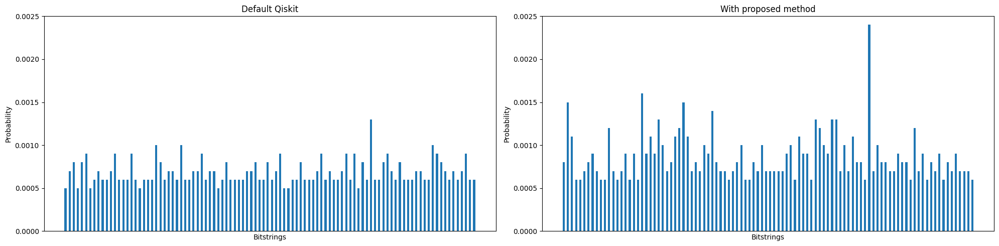

In [456]:
show_histograms({'prop':fied_naw, 'def':def_dist}, keep_top=100, y_lim=0.0025)

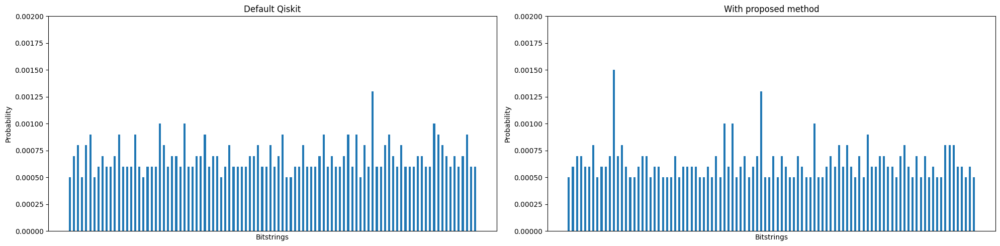

In [457]:
show_histograms({'prop':embed_nag, 'def':def_dist}, keep_top=100, y_lim=0.002)

In [410]:
max(def_dist.values()), max(embed_naw.values())

(0.0013, 0.0012)

In [144]:
backend = FakeBrisbane()

Default

In [146]:
def_dist = maxcut_dist(sim=backend, backend=backend, graph_type='ba', num_nodes=14, param=2, default=True, gate='ecr')

Default=>  ecr :  115 Depth:  265


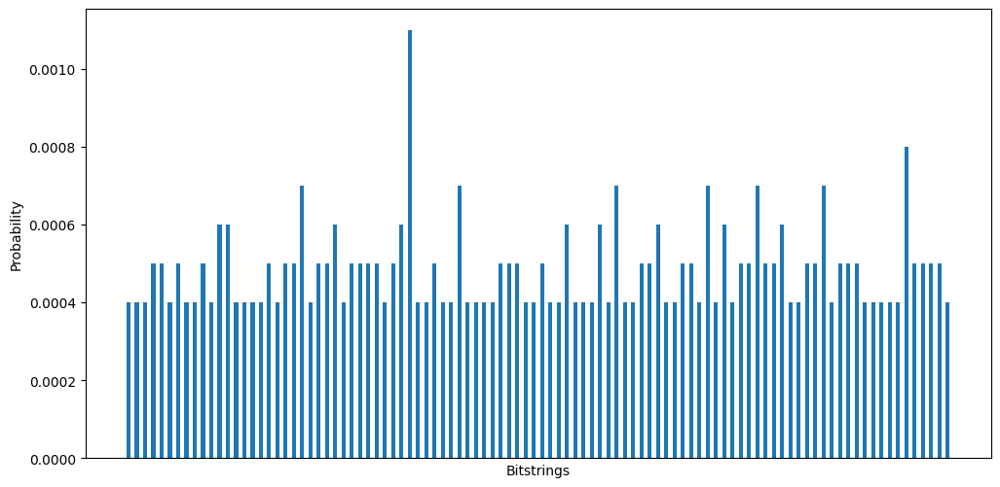

In [147]:
plot_histogram(def_dist, keep_top=100)

Fiedler

In [ ]:
fied_nag = maxcut_dist(sim=backend, backend=backend, num_nodes=14, param=2, tech='1D', gate='ecr')

Prop=>  ecr :  179 Depth:  362


In [149]:
fied_naw = maxcut_dist(sim=backend, backend=backend, graph_type='ba', num_nodes=14, param=2, tech='1D', noise_aware=True, gate='ecr')

Prop=>  ecr :  114 Depth:  253


embedded

In [ ]:
embed_nag = maxcut_dist(sim=backend, backend=backend, num_nodes=14, param=5, tech='2D', k=3, gate='ecr')

Prop=>  ecr :  177 Depth:  332


In [151]:
embed_naw = maxcut_dist(sim=backend, backend=backend, graph_type='ba',num_nodes=14, param=2, tech='2D', k=3, noise_aware=True, gate='ecr')

Prop=>  ecr :  128 Depth:  281


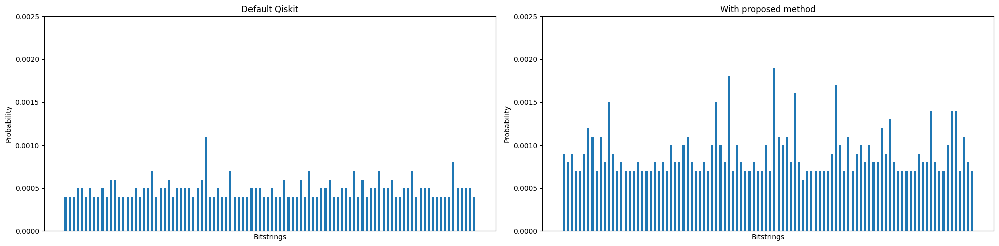

In [150]:
show_histograms({'prop':fied_naw, 'def':def_dist}, keep_top=100, y_lim=0.0025)

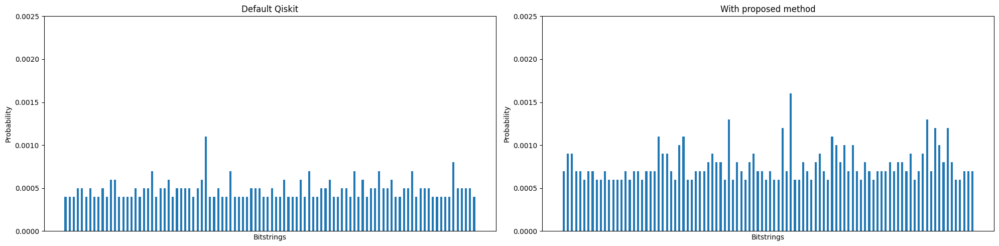

In [153]:
show_histograms({'prop':embed_naw, 'def':def_dist}, keep_top=100, y_lim=0.0025)